# Adversarial Search: Playing Connect 4

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]

## Learning Outcomes

* Implement adversarial search algorithms for strategic game play.
* Analyze and optimize search in complex game spaces.
* Design effective heuristic evaluation functions.
* Compare performance across different agent strategies.
* Evaluate algorithmic trade-offs between decision quality and efficiency.

## Instructions

Total Points: Undergraduates 100, graduate students 110

Complete this notebook and submit it. The notebook needs to be a complete project report with your implementation, documentation including a short discussion of how your implementation works and your design choices, and experimental results (e.g., tables and charts with simulation results) with a short discussion of what they mean. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 


## Introduction

You will implement different versions of agents that play Connect 4:

> "Connect 4 is a two-player connection board game, in which the players choose a color and then take turns dropping colored discs into a seven-column, six-row vertically suspended grid. The pieces fall straight down, occupying the lowest available space within the column. The objective of the game is to be the first to form a horizontal, vertical, or diagonal line of four of one's own discs." (see [Connect Four on Wikipedia](https://en.wikipedia.org/wiki/Connect_Four))

Note that [Connect-4 has been solved](https://en.wikipedia.org/wiki/Connect_Four#Mathematical_solution)
in 1988. A connect-4 solver with a discussion of how to solve different parts of the problem can be found here: https://connect4.gamesolver.org/en/

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## Task 1: Defining the Search Problem [10 point]

Define the components of the search problem:

* Initial state
* Actions
* Transition model (result function)
* Goal state (terminal state and utility)

Describe each component and then implement it as a function that can be used by search algorithms.

**Mô tả các thành phần của bài toán tìm kiếm Connect 4** (bàn chuẩn 6 hàng × 7 cột; mọi hàm đều dùng được cho kích thước bàn khác):

| Thành phần | Mô tả | Hàm cài đặt |
|---|---|---|
| **Trạng thái** | mảng numpy `hàng × cột`: `0` = ô trống, `1` = quân người chơi 1 (đỏ, đi trước), `-1` = quân người chơi −1 (vàng); hàng 0 là hàng trên cùng | – |
| **Trạng thái đầu** | bàn cờ rỗng | `initial_state(shape)` |
| **Hành động** | chọn một **cột** chưa đầy (ô trên cùng của cột còn trống): tối đa 7 hành động | `actions(board)` |
| **Mô hình chuyển trạng thái** | quân của người chơi rơi xuống ô trống thấp nhất của cột đã chọn; trả về một **bản sao** của bàn cờ | `result(board, player, action)` |
| **Kiểm tra trạng thái kết thúc** | có 4 quân cùng màu liên tiếp (ngang, dọc hoặc hai đường chéo) **hoặc** bàn cờ đã đầy (hòa) | `terminal(board)`, `winner(board)` |
| **Lợi ích (utility)** | +1 nếu `player` thắng, 0 nếu hòa, −1 nếu thua; `None` khi ván chưa kết thúc | `utility(board, player)` |
| Người đến lượt | suy ra từ số quân trên bàn (người 1 đi trước) | `player_to_move(board)` |

In [2]:
# Your code/answer goes here.

import math, random, time, itertools
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# ---------------------------------------------------------------------------------------------
# Bài toán tìm kiếm Connect 4 trên mảng numpy:  0 = ô trống, 1 = người chơi 1 (đỏ, đi trước), -1 = người chơi -1 (vàng)
# Hàng 0 là hàng trên cùng, hàng cuối là hàng dưới cùng (giống hàm `visualize` bên dưới).
# ---------------------------------------------------------------------------------------------

def initial_state(shape = (6, 7)):
    """Trạng thái đầu: bàn cờ rỗng."""
    return np.full(shape = shape, fill_value = 0)

def actions(board):
    """Các hành động hợp lệ = các cột chưa đầy (ô trên cùng của cột còn trống)."""
    return [int(c) for c in np.flatnonzero(board[0] == 0)]

def result(board, player, action):
    """Mô hình chuyển trạng thái: quân của `player` rơi xuống ô trống thấp nhất của cột `action`.
    Trả về một bản sao của bàn cờ (không sửa bàn cờ gốc)."""
    if board[0, action] != 0:
        raise ValueError(f"Hành động {action} không hợp lệ: cột đã đầy")
    new_board = board.copy()
    row = np.flatnonzero(board[:, action] == 0)[-1]      # ô trống có chỉ số hàng lớn nhất = thấp nhất
    new_board[row, action] = player
    return new_board

def winner(board):
    """Trả về 1 hoặc -1 nếu người chơi đó có 4 quân liên tiếp (ngang, dọc, chéo), ngược lại trả về 0.
    Dùng được cho bàn cờ có kích thước bất kỳ."""
    for p in (1, -1):
        b = (board == p)
        if (b[:, :-3] & b[:, 1:-2] & b[:, 2:-1] & b[:, 3:]).any(): return p                # hàng ngang
        if (b[:-3, :] & b[1:-2, :] & b[2:-1, :] & b[3:, :]).any(): return p                # cột dọc
        if (b[:-3, :-3] & b[1:-2, 1:-2] & b[2:-1, 2:-1] & b[3:, 3:]).any(): return p       # chéo "\"
        if (b[3:, :-3] & b[2:-1, 1:-2] & b[1:-2, 2:-1] & b[:-3, 3:]).any(): return p       # chéo "/"
    return 0

def terminal(board):
    """Trạng thái kết thúc: có người thắng hoặc bàn cờ đã đầy."""
    return winner(board) != 0 or len(actions(board)) == 0

def utility(board, player = 1):
    """Lợi ích của trạng thái kết thúc đối với `player`: +1 thắng, 0 hòa, -1 thua. None nếu chưa kết thúc."""
    w = winner(board)
    if w == player:  return +1
    if w == -player: return -1
    if len(actions(board)) == 0: return 0
    return None

def player_to_move(board):
    """Người đến lượt suy ra từ số quân trên bàn (người chơi 1 đi trước)."""
    return 1 if np.sum(board == 1) == np.sum(board == -1) else -1

# thử nhanh: đi vài nước trên bàn chuẩn 6 x 7
b = initial_state()
for a in (3, 3, 4, 4, 2):
    b = result(b, player_to_move(b), a)
print(b)
print("hành động hợp lệ:", actions(b), "| kết thúc?", terminal(b), "| lợi ích cho người 1:", utility(b, 1))

[[ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0  0  0 -1 -1  0  0]
 [ 0  0  1  1  1  0  0]]
hành động hợp lệ: [0, 1, 2, 3, 4, 5, 6] | kết thúc? False | lợi ích cho người 1: None


### Biểu diễn bitboard dùng bên trong các thuật toán tìm kiếm

Giao diện của các hàm (`actions`, `result`, `terminal`, `utility`, tác tử `agent(board, player)`) dùng **mảng numpy** đúng như đề bài, nên các tác tử của nhóm có thể đấu với tác tử của nhóm khác. Tuy nhiên mỗi nút của cây tìm kiếm mà phải sao chép mảng numpy và quét 69 cửa sổ 4 ô thì rất chậm (cỡ 100 µs). Vì vậy **bên trong** các tác tử, bàn cờ được đổi một lần sang **bitboard** (kỹ thuật của John Tromp) rồi tìm kiếm trên các số nguyên Python:

* mỗi cột dùng `rows + 1` bit liên tiếp (bit trên cùng là bit đệm luôn bằng 0) nên bàn 6 × 7 dùng 49 bit:

```
 .  .  .  .  .  .  .     <- hàng đệm (luôn 0)
 5 12 19 26 33 40 47
 4 11 18 25 32 39 46
 3 10 17 24 31 38 45
 2  9 16 23 30 37 44
 1  8 15 22 29 36 43
 0  7 14 21 28 35 42      <- hàng dưới cùng
```

* một vị trí = hai số nguyên `(cur, mask)`: `mask` = mọi ô có quân, `cur` = quân của người **đang đến lượt**; quân đối thủ là `cur ^ mask` (nên đổi lượt chỉ cần `cur ^ mask`);
* **thả quân** vào cột `c`: ô mới là `(mask + bottom[c]) & col_mask[c]` (phép cộng làm "nổi" quân lên ô trống thấp nhất), vị trí mới là `(cur ^ mask, mask | ô_mới)`;
* **kiểm tra thắng**: với bước dịch `s` (dọc: 1, ngang: `H`, hai đường chéo: `H - 1` và `H + 1`), đặt `m = pos & (pos >> s)` thì `m & (m >> 2s) != 0` khi và chỉ khi có 4 quân liên tiếp theo hướng đó;
* `winning_cells` tính cùng lúc **mọi ô** mà một người sẽ thắng nếu đặt quân vào (dùng để phát hiện nước thắng ngay và nước buộc phải chặn).

Mã bên dưới được **kiểm chứng chéo** với các hàm numpy ở trên trên nhiều kích thước bàn cờ khác nhau (ô code kế tiếp).

In [3]:
# popcount (đếm bit 1): int.bit_count có từ Python 3.10
try:
    (1).bit_count()
    popcount = int.bit_count
except AttributeError:
    popcount = lambda x: bin(x).count("1")

class Geometry:
    """Các hằng số bit của bàn cờ `rows x cols` theo bố cục của John Tromp.

    Mỗi cột chiếm `H = rows + 1` bit liên tiếp (bit thấp nhất = ô dưới cùng, bit cao nhất của cột là bit "đệm" luôn bằng 0).
    Một vị trí được lưu bằng hai số nguyên: `mask` (mọi ô có quân) và `cur` (quân của người đang đến lượt);
    quân của đối thủ là `cur ^ mask`.
    """
    _cache = {}

    @classmethod
    def get(cls, rows, cols):
        if (rows, cols) not in cls._cache:
            cls._cache[(rows, cols)] = cls(rows, cols)
        return cls._cache[(rows, cols)]

    def __init__(self, rows, cols):
        self.rows, self.cols, self.cells = rows, cols, rows * cols
        self.H = H = rows + 1
        self.bottom   = [1 << (c * H) for c in range(cols)]                      # ô dưới cùng của từng cột
        self.col_mask = [((1 << rows) - 1) << (c * H) for c in range(cols)]      # mọi ô của từng cột
        self.top      = [1 << (c * H + rows - 1) for c in range(cols)]           # ô trên cùng của từng cột
        self.board_mask = sum(self.col_mask)
        self.bottom_all = sum(self.bottom)
        # thứ tự cột từ giữa ra hai bên, ví dụ bàn 7 cột: 3, 2, 4, 1, 5, 0, 6
        self.center_order = sorted(range(cols), key = lambda c: (abs(c - (cols - 1) / 2), c))
        mid = [cols // 2] if cols % 2 else [cols // 2 - 1, cols // 2]
        self.center_mask = sum(self.col_mask[c] for c in mid)
        # tất cả các "cửa sổ" 4 ô thẳng hàng (dùng cho hàm heuristic)
        self.windows = []
        for dc, dk in ((0, 1), (1, 0), (1, 1), (1, -1)):        # dọc, ngang, chéo lên, chéo xuống
            for c in range(cols):
                for k in range(rows):
                    if 0 <= c + 3 * dc < cols and 0 <= k + 3 * dk < rows:
                        self.windows.append(sum(1 << ((c + j * dc) * H + k + j * dk) for j in range(4)))

    # ---- chuyển đổi giữa mảng numpy và bitboard ----
    def to_bits(self, board, player):
        """(cur, mask) của bàn cờ numpy khi đến lượt `player`."""
        cur = mask = 0
        for r, c in zip(*np.nonzero(board)):
            bit = 1 << (int(c) * self.H + (self.rows - 1 - int(r)))
            mask |= bit
            if board[r, c] == player: cur |= bit
        return cur, mask

    def to_board(self, cur, mask, player = 1):
        """Ngược lại: bitboard -> mảng numpy (`cur` là quân của `player`)."""
        board = np.zeros((self.rows, self.cols), dtype = int)
        for c in range(self.cols):
            for k in range(self.rows):
                bit = 1 << (c * self.H + k)
                if mask & bit:
                    board[self.rows - 1 - k, c] = player if cur & bit else -player
        return board

    # ---- các phép toán bit ----
    def is_win(self, pos):
        """`pos` (quân của một người chơi) có 4 quân liên tiếp không? Mỗi hướng cần 2 phép dịch bit."""
        H = self.H
        m = pos & (pos >> H)
        if m & (m >> (2 * H)): return True              # ngang
        m = pos & (pos >> (H - 1))
        if m & (m >> (2 * (H - 1))): return True        # chéo
        m = pos & (pos >> (H + 1))
        if m & (m >> (2 * (H + 1))): return True        # chéo ngược
        m = pos & (pos >> 1)
        return bool(m & (m >> 2))                       # dọc

    def winning_cells(self, pos, mask):
        """Các ô trống mà nếu `pos` đặt quân vào thì tạo thành 4 quân liên tiếp (mọi ô, kể cả chưa đặt được ngay)."""
        H = self.H
        r = (pos << 1) & (pos << 2) & (pos << 3)        # dọc
        for s in (H, H - 1, H + 1):                     # ngang và hai đường chéo
            p = (pos << s) & (pos << 2 * s)
            r |= p & (pos << 3 * s)
            r |= p & (pos >> s)
            p = (pos >> s) & (pos >> 2 * s)
            r |= p & (pos << s)
            r |= p & (pos >> 3 * s)
        return r & (self.board_mask ^ mask)

    def mirror(self, x):
        """Đối xứng trái-phải của một bitboard."""
        H, full = self.H, (1 << self.H) - 1
        return sum(((x >> (c * H)) & full) << ((self.cols - 1 - c) * H) for c in range(self.cols))

In [4]:
def check_geometry(shapes, games = 200, seed = 0):
    """Kiểm tra chéo bitboard với các hàm numpy trên các ván chơi ngẫu nhiên."""
    rng = random.Random(seed)
    rows_out = []
    for shape in shapes:
        g = Geometry.get(*shape)
        checked = 0
        for _ in range(games):
            board, p = initial_state(shape), 1
            while True:
                cur, mask = g.to_bits(board, p)
                opp = cur ^ mask
                # 1. chuyển đổi hai chiều
                assert (g.to_board(cur, mask, p) == board).all()
                # 2. phát hiện thắng
                w_bits = 1 if g.is_win(g.to_bits(board, 1)[0]) else (-1 if g.is_win(g.to_bits(board, -1)[0]) else 0)
                assert w_bits == winner(board), (shape, board)
                if terminal(board): break
                # 3. hành động hợp lệ và các ô "thắng ngay"
                acts = actions(board)
                assert acts == [c for c in range(shape[1]) if not (mask & g.top[c])]
                cells = g.winning_cells(cur, mask)
                for c in acts:
                    nb = (mask + g.bottom[c]) & g.col_mask[c]
                    assert g.is_win(cur | nb) == (utility(result(board, p, c), p) == 1)
                    assert bool(cells & nb) == g.is_win(cur | nb)
                # 4. mô hình chuyển trạng thái
                a = rng.choice(acts)
                nb = (mask + g.bottom[a]) & g.col_mask[a]
                nxt = result(board, p, a)
                assert (g.to_board(opp, mask | nb, -p) == nxt).all()
                board, p = nxt, -p
                checked += 1
        rows_out.append({"Kích thước (hàng x cột)": f"{shape[0]} x {shape[1]}", "Số vị trí đã kiểm tra": checked, "Kết quả": "khớp hoàn toàn"})
    return pd.DataFrame(rows_out)

display(check_geometry([(4, 4), (5, 6), (6, 7), (3, 9), (7, 5), (4, 7)], games = 200))

,Kích thước (hàng x cột),Số vị trí đã kiểm tra,Kết quả
0,4 x 4,2907,khớp hoàn toàn
1,5 x 6,3836,khớp hoàn toàn
2,6 x 7,4345,khớp hoàn toàn
3,3 x 9,4242,khớp hoàn toàn
4,7 x 5,3922,khớp hoàn toàn
5,4 x 7,3881,khớp hoàn toàn


How big is the state space? Give an estimate and explain it.

`<Your answer goes here>`

In [5]:
from math import comb

SUPERSCRIPT = str.maketrans("-0123456789", "⁻⁰¹²³⁴⁵⁶⁷⁸⁹")
def sci(x, digits = 2):
    """Số dạng khoa học dễ đọc: 4.53 · 10¹²."""
    e = int(math.floor(math.log10(abs(x)))) if x else 0
    return f"{x / 10 ** e:.{digits - 1}f} · 10{str(e).translate(SUPERSCRIPT)}"

def count_height_vectors(rows, cols):
    """N[k] = số cách chọn chiều cao các cột (0..rows) sao cho tổng số quân là k."""
    N = [1] + [0] * (rows * cols)
    for _ in range(cols):
        new = [0] * (rows * cols + 1)
        for k, v in enumerate(N):
            if v:
                for h in range(rows + 1):
                    if k + h <= rows * cols: new[k + h] += v
        N = new
    return N

def upper_bounds(rows, cols):
    """Ba cận trên cho số trạng thái (mỗi cận chặt hơn cận trước)."""
    naive = 3 ** (rows * cols)                                           # mỗi ô: trống / đỏ / vàng
    gravity = (2 ** (rows + 1) - 1) ** cols                              # quân dồn xuống: mỗi cột cao 0..rows, mỗi quân 2 màu
    N = count_height_vectors(rows, cols)
    balanced = sum(N[k] * comb(k, (k + 1) // 2) for k in range(rows * cols + 1))     # + số quân đỏ - vàng chênh nhau tối đa 1
    return naive, gravity, balanced

def exact_counts(rows, cols):
    """Đếm CHÍNH XÁC (quy hoạch động theo từng lớp lượt đi, gộp các vị trí trùng nhau):
    số vị trí đạt được, số nút của cây trò chơi (mọi dãy nước đi) và số ván hoàn chỉnh (lá của cây)."""
    g = Geometry.get(rows, cols)
    level = {(0, 0): 1}                         # (cur, mask) -> số dãy nước đi dẫn tới vị trí này
    positions = nodes = 1
    games = 0
    for ply in range(rows * cols):
        nxt, won = {}, {}
        for (cur, mask), n in level.items():
            for c in range(cols):
                if mask & g.top[c]: continue
                nb = (mask + g.bottom[c]) & g.col_mask[c]
                if g.is_win(cur | nb):
                    k = (cur | nb, mask | nb); won[k] = won.get(k, 0) + n        # vị trí có người thắng: nút lá
                else:
                    k = (cur ^ mask, mask | nb); nxt[k] = nxt.get(k, 0) + n
        positions += len(nxt) + len(won)
        nodes += sum(nxt.values()) + sum(won.values())
        games += sum(won.values())
        level = nxt
        if not level: break
    games += sum(level.values())                # bàn cờ đầy không ai thắng = hòa
    return positions, nodes, games

rows_out = []
exact = {}
for shape in [(3, 4), (4, 4), (5, 4), (4, 5)]:
    t0 = time.time()
    exact[shape] = exact_counts(*shape)
    naive, gravity, balanced = upper_bounds(*shape)
    pos, nodes, games = exact[shape]
    rows_out.append({"Bàn cờ (hàng x cột)": f"{shape[0]} x {shape[1]}", "3^(số ô)": f"{naive:.3g}", "Cận có trọng lực": f"{gravity:.3g}",
                     "Cận có cân bằng quân": f"{balanced:,}", "Số vị trí THỰC TẾ": f"{pos:,}", "Cận / thực tế": round(balanced / pos, 2),
                     "Số nút cây trò chơi": f"{nodes:,}", "Số ván hoàn chỉnh": f"{games:,}", "Thời gian đếm (s)": round(time.time() - t0, 1)})
naive, gravity, balanced = upper_bounds(6, 7)
KNOWN_POSITIONS_6x7 = 4_531_985_219_092      # Edelkamp & Kissmann / John Tromp, OEIS A212693
rows_out.append({"Bàn cờ (hàng x cột)": "6 x 7 (chuẩn)", "3^(số ô)": f"{naive:.3g}", "Cận có trọng lực": f"{gravity:.3g}",
                 "Cận có cân bằng quân": f"{balanced:,}", "Số vị trí THỰC TẾ": f"{KNOWN_POSITIONS_6x7:,} (tài liệu)", "Cận / thực tế": round(balanced / KNOWN_POSITIONS_6x7, 2),
                 "Số nút cây trò chơi": "xem ô sau", "Số ván hoàn chỉnh": "—", "Thời gian đếm (s)": "—"})
states_table = pd.DataFrame(rows_out)
display(states_table)

# Kiểm chứng độc lập: số ván hoàn chỉnh khớp OEIS A342329 (bàn (n+1) cột x n hàng): 356232 (n = 3) và 152505051772 (n = 4)
assert exact[(3, 4)][2] == 356232 and exact[(4, 5)][2] == 152505051772
print("Số ván hoàn chỉnh tính được khớp chuỗi OEIS A342329 (356.232 ván trên bàn 3 x 4 và 152.505.051.772 ván trên bàn 4 x 5).")

,Bàn cờ (hàng x cột),3^(số ô),Cận có trọng lực,Cận có cân bằng quân,Số vị trí THỰC TẾ,Cận / thực tế,Số nút cây trò chơi,Số ván hoàn chỉnh,Thời gian đếm (s)
0,3 x 4,5.31e+05,5.06e+04,"12,933","12,031",1.07,"1,057,009","356,232",0.0
1,4 x 4,4.3e+07,9.24e+05,"201,755","161,029",1.25,"131,060,741","47,982,540",0.3
2,5 x 4,3.49e+09,1.58e+07,"3,039,959","1,706,255",1.78,"14,464,709,375","5,317,582,722",3.1
3,4 x 5,3.49e+09,2.86e+07,"5,621,939","3,945,711",1.42,"385,361,807,273","152,505,051,772",8.2
4,6 x 7 (chuẩn),1.09e+20,5.33e+14,"70,728,639,995,483","4,531,985,219,092 (tài liệu)",15.61,xem ô sau,—,—


Số ván hoàn chỉnh tính được khớp chuỗi OEIS A342329 (356.232 ván trên bàn 3 x 4 và 152.505.051.772 ván trên bàn 4 x 5).


In [6]:
b_naive, b_grav, b_bal = upper_bounds(6, 7)
ratios = [float(x) for x in states_table["Cận / thực tế"].iloc[:-1]]
col_growth = exact[(4, 5)][0] / exact[(4, 4)][0]
display(Markdown(f"""
**Ước lượng số trạng thái (bàn chuẩn 6 × 7): khoảng {sci(KNOWN_POSITIONS_6x7)} vị trí** (số chính xác trong tài liệu: {KNOWN_POSITIONS_6x7:,}).

Cách ước lượng, từ thô đến chặt:

1. **Mỗi ô có 3 giá trị** (trống, đỏ, vàng) ⇒ 3⁴² ≈ {sci(b_naive)}. Cận này rất lỏng vì cho phép quân "lơ lửng" giữa không trung.
2. **Trọng lực:** quân phải dồn xuống đáy nên mỗi cột chỉ được mô tả bằng chiều cao 0…6 và màu từng quân: (2⁷ − 1)⁷ = 127⁷ ≈ {sci(b_grav)}.
3. **Luân phiên lượt:** hai người đặt quân xen kẽ nên số quân đỏ và vàng chênh nhau tối đa 1. Đếm các cách chọn chiều cao cột có tổng k quân rồi nhân với C(k, ⌈k/2⌉) cho số cách tô màu ⇒ ≈ {sci(b_bal)}.
4. **Luật kết thúc ván:** vị trí đã có 4 quân liên tiếp thì không đi tiếp, và nhiều tổ hợp màu không thể xảy ra trong thực tế. Cận (3) còn đếm cả những vị trí này nên lớn hơn số thật khoảng **{b_bal / KNOWN_POSITIONS_6x7:.0f} lần**; số thật ≈ **{sci(KNOWN_POSITIONS_6x7)}**.

Để kiểm tra cách ước lượng, bảng trên **đếm chính xác** số vị trí của các bàn nhỏ bằng quy hoạch động: cận (3) luôn lớn hơn số thật nhưng khá sát ở các bàn nhỏ (lớn hơn {min(ratios):.2f}–{max(ratios):.2f} lần), còn ở bàn 6 × 7 khoảng cách lên tới {b_bal / KNOWN_POSITIONS_6x7:.1f} lần vì bàn lớn có nhiều vị trí đã có người thắng hoặc không thể đạt tới hơn; do là cận trên nên không có gì mâu thuẫn. Số vị trí tăng cỡ **×{col_growth:.0f} khi thêm một cột** (4 × 4 → 4 × 5: {exact[(4,4)][0]:,} → {exact[(4,5)][0]:,}).

Ý nghĩa: ngay cả khi mỗi vị trí chỉ tốn 8 byte, lưu hết {sci(KNOWN_POSITIONS_6x7)} vị trí cần ≈ {KNOWN_POSITIONS_6x7 * 8 / 1e12:.0f} TB, nên **không thể** lập bảng mọi trạng thái trong bộ nhớ như với Tic-Tac-Toe (chỉ 5.478 trạng thái hợp lệ); thuật toán phải dựa vào bảng chuyển vị có kích thước giới hạn.
"""))


**Ước lượng số trạng thái (bàn chuẩn 6 × 7): khoảng 4.5 · 10¹² vị trí** (số chính xác trong tài liệu: 4,531,985,219,092).

Cách ước lượng, từ thô đến chặt:

1. **Mỗi ô có 3 giá trị** (trống, đỏ, vàng) ⇒ 3⁴² ≈ 1.1 · 10²⁰. Cận này rất lỏng vì cho phép quân "lơ lửng" giữa không trung.
2. **Trọng lực:** quân phải dồn xuống đáy nên mỗi cột chỉ được mô tả bằng chiều cao 0…6 và màu từng quân: (2⁷ − 1)⁷ = 127⁷ ≈ 5.3 · 10¹⁴.
3. **Luân phiên lượt:** hai người đặt quân xen kẽ nên số quân đỏ và vàng chênh nhau tối đa 1. Đếm các cách chọn chiều cao cột có tổng k quân rồi nhân với C(k, ⌈k/2⌉) cho số cách tô màu ⇒ ≈ 7.1 · 10¹³.
4. **Luật kết thúc ván:** vị trí đã có 4 quân liên tiếp thì không đi tiếp, và nhiều tổ hợp màu không thể xảy ra trong thực tế. Cận (3) còn đếm cả những vị trí này nên lớn hơn số thật khoảng **16 lần**; số thật ≈ **4.5 · 10¹²**.

Để kiểm tra cách ước lượng, bảng trên **đếm chính xác** số vị trí của các bàn nhỏ bằng quy hoạch động: cận (3) luôn lớn hơn số thật nhưng khá sát ở các bàn nhỏ (lớn hơn 1.07–1.78 lần), còn ở bàn 6 × 7 khoảng cách lên tới 15.6 lần vì bàn lớn có nhiều vị trí đã có người thắng hoặc không thể đạt tới hơn; do là cận trên nên không có gì mâu thuẫn. Số vị trí tăng cỡ **×25 khi thêm một cột** (4 × 4 → 4 × 5: 161,029 → 3,945,711).

Ý nghĩa: ngay cả khi mỗi vị trí chỉ tốn 8 byte, lưu hết 4.5 · 10¹² vị trí cần ≈ 36 TB, nên **không thể** lập bảng mọi trạng thái trong bộ nhớ như với Tic-Tac-Toe (chỉ 5.478 trạng thái hợp lệ); thuật toán phải dựa vào bảng chuyển vị có kích thước giới hạn.


How big is the game tree that minimax search will go through? Give an estimate and explain it.

`<Your answer goes here>`

In [7]:
def knuth_estimate(rows, cols, probes, seed = 0):
    """Ước lượng kích thước cây trò chơi bằng phương pháp của Knuth (1975): đi một đường ngẫu nhiên từ gốc, gọi b_i là số
    nước đi hợp lệ tại độ sâu i thì  1 + b_0 + b_0 b_1 + b_0 b_1 b_2 + ...  là ước lượng KHÔNG chệch của số nút của cây."""
    g = Geometry.get(rows, cols)
    rng = random.Random(seed)
    total = total2 = lengths = 0.0
    for _ in range(probes):
        cur = mask = 0
        prod, est, plies = 1, 1, 0
        open_cols = list(range(cols))
        while open_cols:
            b = len(open_cols)
            prod *= b; est += prod
            c = open_cols[int(rng.random() * b)]
            nb = (mask + g.bottom[c]) & g.col_mask[c]
            plies += 1
            if g.is_win(cur | nb): break                     # đạt trạng thái kết thúc
            cur, mask = cur ^ mask, mask | nb
            if mask & g.top[c]: open_cols.remove(c)
        total += est; total2 += est * est; lengths += plies
    mean = total / probes
    se = math.sqrt(max(total2 / probes - mean * mean, 0) / probes)
    return mean, se, lengths / probes

# 1) kiểm chứng phương pháp trên các bàn nhỏ đã biết chính xác số nút
rows_out = []
for shape in [(4, 4), (5, 4), (4, 5)]:
    est, se, L = knuth_estimate(*shape, probes = 100000)
    true = exact[shape][1]
    rows_out.append({"Bàn cờ": f"{shape[0]} x {shape[1]}", "Số nút CHÍNH XÁC": f"{true:,}", "Ước lượng Knuth": f"{est:.4g}", "Sai số chuẩn": f"{se:.2g}",
                     "|ước lượng - thật| / sai số chuẩn": round(abs(est - true) / se, 1)})
knuth_check = pd.DataFrame(rows_out)
display(knuth_check)

# 2) áp dụng cho bàn chuẩn 6 x 7
t0 = time.time()
tree_est, tree_se, avg_len = knuth_estimate(6, 7, probes = 400000, seed = 1)
print(f"Cây trò chơi 6 x 7: ≈ {tree_est:.3g} nút (± {100 * tree_se / tree_est:.0f} %), độ dài trung bình của một ván ngẫu nhiên: {avg_len:.1f} nước  [{time.time() - t0:.0f} s]")

branching_bound   = 7 ** 42                                                  # độ sâu tối đa 42, tối đa 7 nước mỗi lượt
fill_sequences    = math.factorial(42) // math.factorial(6) ** 7             # số dãy cột lấp đầy bàn cờ (bỏ qua luật thắng)
ab_best_case      = math.sqrt(tree_est)                                      # Alpha-Beta tốt nhất ~ căn bậc hai
print(f"Cận trên 7^42 = {branching_bound:.3g}; số dãy nước lấp đầy bàn = 42!/(6!)^7 = {fill_sequences:.3g}; sqrt(kích thước cây) = {ab_best_case:.3g}")

,Bàn cờ,Số nút CHÍNH XÁC,Ước lượng Knuth,Sai số chuẩn,|ước lượng - thật| / sai số chuẩn
0,4 x 4,"131,060,741",1.309e+08,6.1e+05,0.2
1,5 x 4,"14,464,709,375",1.441e+10,1.1e+08,0.6
2,4 x 5,"385,361,807,273",3.888e+11,3e+09,1.1


Cây trò chơi 6 x 7: ≈ 1.96e+29 nút (± 9 %), độ dài trung bình của một ván ngẫu nhiên: 21.3 nước  [9 s]
Cận trên 7^42 = 3.12e+35; số dãy nước lấp đầy bàn = 42!/(6!)^7 = 1.4e+31; sqrt(kích thước cây) = 4.43e+14


In [8]:
max_dev = float(knuth_check["|ước lượng - thật| / sai số chuẩn"].max())
display(Markdown(f"""
**Cây trò chơi mà Minimax duyệt có cỡ ≈ {sci(tree_est)} nút trên bàn 6 × 7.**

* **Cận trên thô:** độ sâu tối đa là 42 lượt (đủ 42 ô) và mỗi lượt có tối đa 7 nước ⇒ 7⁴² ≈ {sci(branching_bound)}. Cận này lớn quá mức vì các cột đầy dần và ván có thể kết thúc sớm.
* **Dãy nước lấp đầy bàn cờ:** số cách sắp thứ tự 42 nước vào 7 cột (mỗi cột đúng 6 quân) là 42!/(6!)⁷ ≈ {sci(fill_sequences)}; số ván thực sự nhỏ hơn con số này vì ván dừng ngay khi có người thắng.
* **Ước lượng thực nghiệm (Knuth):** đi {400000:,} đường ngẫu nhiên từ gốc và nhân các hệ số nhánh dọc đường cho **≈ {sci(tree_est)} nút** với sai số chuẩn ≈ {100 * tree_se / tree_est:.0f} %. Phương pháp được kiểm chứng ở bảng trên: trên các bàn 4 × 4, 5 × 4, 4 × 5 ước lượng khớp số nút chính xác (lệch tối đa {max_dev:.1f} sai số chuẩn). Ván ngẫu nhiên trung bình chỉ dài {avg_len:.1f} nước (không phải 42), nhưng nhánh dài vẫn chiếm phần lớn số nút.
* **Alpha-Beta tốt nhất** chỉ cần cỡ căn bậc hai: √({sci(tree_est)}) ≈ {sci(ab_best_case)} nút. Với tốc độ cỡ 10⁶ nút/giây của mã Python dùng bitboard (đo ở Task 3), con số này vẫn cần ≈ {ab_best_case / 1e6 / 3600 / 24 / 365:.0f} năm cho **một** nước đi ⇒ tìm kiếm tới trạng thái kết thúc trên bàn chuẩn là không khả thi nếu không có cắt tỉa mạnh, bảng chuyển vị, thứ tự nước đi tốt, hoặc cắt độ sâu và heuristic (Task 4–5).
"""))


**Cây trò chơi mà Minimax duyệt có cỡ ≈ 2.0 · 10²⁹ nút trên bàn 6 × 7.**

* **Cận trên thô:** độ sâu tối đa là 42 lượt (đủ 42 ô) và mỗi lượt có tối đa 7 nước ⇒ 7⁴² ≈ 3.1 · 10³⁵. Cận này lớn quá mức vì các cột đầy dần và ván có thể kết thúc sớm.
* **Dãy nước lấp đầy bàn cờ:** số cách sắp thứ tự 42 nước vào 7 cột (mỗi cột đúng 6 quân) là 42!/(6!)⁷ ≈ 1.4 · 10³¹; số ván thực sự nhỏ hơn con số này vì ván dừng ngay khi có người thắng.
* **Ước lượng thực nghiệm (Knuth):** đi 400,000 đường ngẫu nhiên từ gốc và nhân các hệ số nhánh dọc đường cho **≈ 2.0 · 10²⁹ nút** với sai số chuẩn ≈ 9 %. Phương pháp được kiểm chứng ở bảng trên: trên các bàn 4 × 4, 5 × 4, 4 × 5 ước lượng khớp số nút chính xác (lệch tối đa 1.1 sai số chuẩn). Ván ngẫu nhiên trung bình chỉ dài 21.3 nước (không phải 42), nhưng nhánh dài vẫn chiếm phần lớn số nút.
* **Alpha-Beta tốt nhất** chỉ cần cỡ căn bậc hai: √(2.0 · 10²⁹) ≈ 4.4 · 10¹⁴ nút. Với tốc độ cỡ 10⁶ nút/giây của mã Python dùng bitboard (đo ở Task 3), con số này vẫn cần ≈ 14 năm cho **một** nước đi ⇒ tìm kiếm tới trạng thái kết thúc trên bàn chuẩn là không khả thi nếu không có cắt tỉa mạnh, bảng chuyển vị, thứ tự nước đi tốt, hoặc cắt độ sâu và heuristic (Task 4–5).


## Task 2: Game Environment and Random Agent [25 point]

Use a numpy character array as the board.

In [9]:
import numpy as np

def empty_board(shape=(6, 7)):
    return np.full(shape=shape, fill_value=0)

print(empty_board())

[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


The standard board is $6 \times 7$ but you can use smaller boards to test your code. Instead of colors (red and yellow), I use 1 and -1 to represent the players. Make sure that your agent functions all have the from: `agent_type(board, player = 1)`, where board is the current board position (in the format above) and player is the player whose next move it is and who the agent should play (as 1 and -1).

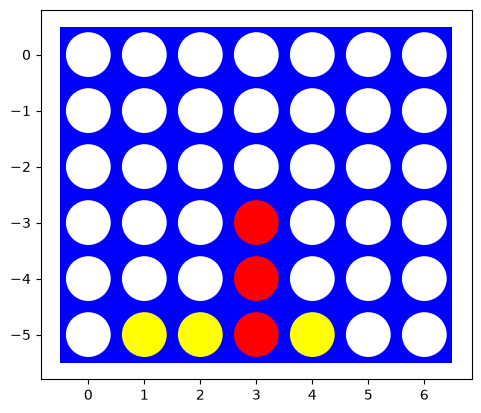

In [10]:
# Visualization code by Randolph Rankin

import matplotlib.pyplot as plt

def visualize(board):
    plt.axes()
    rectangle=plt.Rectangle((-0.5,len(board)*-1+0.5),len(board[0]),len(board),fc='blue')
    circles=[]
    for i,row in enumerate(board):
        for j,val in enumerate(row):
            color='white' if val==0 else 'red' if val==1 else 'yellow'
            circles.append(plt.Circle((j,i*-1),0.4,fc=color))

    plt.gca().add_patch(rectangle)
    for circle in circles:
        plt.gca().add_patch(circle)

    plt.axis('scaled')
    plt.show()
    
board = [[0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0,-1,-1, 1,-1, 0, 0]]
visualize(board)

Implement helper functions for:

* A check for available actions in each state `actions(state)`.
* The transition model `result(state, player, action)`.
* Check for terminal states `terminal(state)`.
* The utility function `utility(state, player)`.

The player argument is used so your agent can play red or yellow.
Make sure that all these functions work with boards of different sizes (number of columns and rows).
You can follow the [tic-tac-toe example from class.](tictactoe_definitions.ipynb)

In [11]:
# Your code/ answer goes here.

# Các hàm actions / result / terminal / utility được định nghĩa ở Task 1 (ô code phía trên) và dùng lại ở đây.
# Ở Task 2 bổ sung các hàm tiện ích để TẠO và VẼ bàn cờ thử nghiệm; ô code kế tiếp kiểm thử các hàm trên nhiều kích thước bàn.

# ---------- Các hàm tiện ích: tạo bàn cờ thử nghiệm và vẽ nhiều bàn cờ cạnh nhau ----------
def board_from_strings(rows):
    """Tạo bàn cờ từ danh sách chuỗi (từ hàng trên xuống dưới): 'X' = người 1 (đỏ), 'O' = người -1 (vàng), '.' = trống."""
    sym = {".": 0, "X": 1, "O": -1}
    board = np.array([[sym[ch] for ch in row] for row in rows])
    for c in range(board.shape[1]):                              # kiểm tra trọng lực: không có quân lơ lửng
        col = board[:, c]
        filled = np.flatnonzero(col != 0)
        assert len(filled) == 0 or (col[filled[0]:] != 0).all(), f"quân lơ lửng ở cột {c}"
    return board

def board_from_moves(moves, shape = (6, 7)):
    """Tạo bàn cờ bằng cách cho hai người chơi lần lượt đi các cột trong `moves` (người 1 đi trước)."""
    board = initial_state(shape)
    for a in moves:
        board = result(board, player_to_move(board), a)
    return board

def draw_board(ax, board, title = None, mark = None):
    """Vẽ bàn cờ lên trục `ax` (cùng phong cách với `visualize`); `mark` = cột (hoặc danh sách cột) cần đánh dấu bằng mũi tên."""
    board = np.asarray(board)
    rows, cols = board.shape
    ax.add_patch(plt.Rectangle((-0.5, -rows + 0.5), cols, rows, fc = "blue"))
    for i in range(rows):
        for j in range(cols):
            v = board[i, j]
            ax.add_patch(plt.Circle((j, -i), 0.4, fc = "white" if v == 0 else "red" if v == 1 else "yellow"))
    for c in ([] if mark is None else np.atleast_1d(mark)):
        ax.text(c, 0.95, "▼", ha = "center", va = "center", color = "green", fontsize = 12)
    ax.set_xlim(-0.6, cols - 0.4); ax.set_ylim(-rows + 0.4, 1.4); ax.set_aspect("equal"); ax.axis("off")
    if title: ax.set_title(title, fontsize = 8.5)

def visualize_grid(boards, titles = None, marks = None, ncols = 4, size = 2.3):
    """Vẽ nhiều bàn cờ trong một hình."""
    n = len(boards)
    nrows = math.ceil(n / ncols)
    cmax, rmax = max(b.shape[1] for b in boards), max(b.shape[0] for b in boards)          # bàn lớn nhất quyết định cỡ hình (các bàn có thể khác kích thước)
    fig, axes = plt.subplots(nrows, ncols, figsize = (size * ncols * cmax / 7, size * nrows * rmax / 6 * 1.1))
    axes = np.atleast_1d(axes).ravel()
    for i, ax in enumerate(axes):
        if i < n:
            draw_board(ax, boards[i], None if titles is None else titles[i], None if marks is None else marks[i])
        else:
            ax.axis("off")
    plt.tight_layout(); plt.show()

tất cả kiểm thử đạt


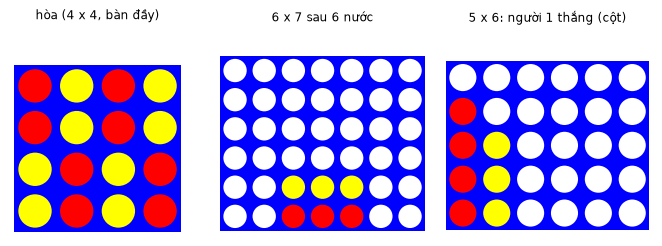

In [12]:
# ---------- Kiểm thử các hàm với nhiều kích thước bàn cờ ----------
def run_unit_tests():
    for shape in [(4, 4), (5, 6), (6, 7), (3, 9), (7, 5), (4, 7)]:
        rows, cols = shape
        # bàn rỗng
        b = initial_state(shape)
        assert actions(b) == list(range(cols)) and not terminal(b) and utility(b, 1) is None and winner(b) == 0
        # thắng theo cột dọc (cần bàn cao ít nhất 4 hàng)
        if rows >= 4:
            v = b.copy()
            for _ in range(4): v = result(v, 1, 0)
            assert winner(v) == 1 and terminal(v) and utility(v, 1) == 1 and utility(v, -1) == -1
        # thắng theo hàng ngang (hàng dưới cùng)
        h = b.copy()
        for c in range(4): h = result(h, -1, c)
        assert winner(h) == -1 and utility(h, -1) == 1 and utility(h, 1) == -1
        # thắng theo đường chéo (cần bàn cao ít nhất 4 hàng): cột c có c quân đệm của người -1 rồi đến quân của người 1
        if rows >= 4:
            d = b.copy()
            for c in range(4):
                for _ in range(c): d = result(d, -1, c)
                d = result(d, 1, c)
            assert winner(d) == 1, "đường chéo lên"
            d2 = b.copy()
            for c in range(4):
                for _ in range(3 - c): d2 = result(d2, -1, c)
                d2 = result(d2, 1, c)
            assert winner(d2) == 1, "đường chéo xuống"
        # cột đầy: hành động bị loại và result báo lỗi
        f = b.copy()
        for i in range(rows): f = result(f, 1 if i % 2 == 0 else -1, 0)
        assert 0 not in actions(f)
        try:
            result(f, 1, 0); raise AssertionError("phải báo lỗi")
        except ValueError:
            pass
        # result không làm thay đổi bàn cờ gốc
        before = b.copy(); result(b, 1, 1); assert (b == before).all()
    # ván hòa thật trên bàn 4 x 4 (mẫu từ ô thử nghiệm)
    draw = board_from_strings(["XOXO", "XOXO", "OXOX", "OXOX"])
    assert terminal(draw) and winner(draw) == 0 and utility(draw, 1) == 0 and utility(draw, -1) == 0 and actions(draw) == []
    return "tất cả kiểm thử đạt"

print(run_unit_tests())
visualize_grid([board_from_strings(["XOXO", "XOXO", "OXOX", "OXOX"]), board_from_moves([3, 3, 4, 4, 2, 2]), board_from_moves([0, 1, 0, 1, 0, 1, 0], (5, 6))],
               ["hòa (4 x 4, bàn đầy)", "6 x 7 sau 6 nước", "5 x 6: người 1 thắng (cột)"], ncols = 3)

Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = 1): ...`

The argument `player` is used for agents that do not store what color they are playing. The value passed on by the environment should be 1 ot -1 for player red and yellow, respectively.  See [Experiments section for tic-tac-toe](tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

In [13]:
# Your code/ answer goes here.

def random_player(board, player = 1):
    """Tác tử ngẫu nhiên: chọn đều ngẫu nhiên một cột còn trống. `player` không dùng đến."""
    return int(np.random.choice(actions(board)))

# thử: tác tử trả về hành động hợp lệ trên bàn có cột đầy
np.random.seed(0)
b = board_from_strings(["O......", "X......", "O......", "X......", "O......", "XO.X..."])
print("Cột 0 đã đầy; các hành động hợp lệ:", actions(b), "→ tác tử ngẫu nhiên chọn:", [random_player(b, 1) for _ in range(8)])

Cột 0 đã đầy; các hành động hợp lệ: [1, 2, 3, 4, 5, 6] → tác tử ngẫu nhiên chọn: [5, 6, 1, 4, 4, 4, 2, 4]


Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

,Kết quả,Số ván,Tỷ lệ (%),Khoảng tin cậy 95 % (±)
0,"Người 1 (đỏ, đi trước) thắng",534,53.4,3.1
1,"Người -1 (vàng, đi sau) thắng",465,46.5,3.1
2,Hòa,1,0.1,0.2


Độ dài trung bình một ván: 21.4 nước (ngắn nhất 7, dài nhất 42) – 1.1 s
100,000 ván (bitboard): người 1 thắng 55.4 %, người -1 thắng 44.4 %, hòa 0.27 %; độ dài TB 21.3 nước  [2 s]


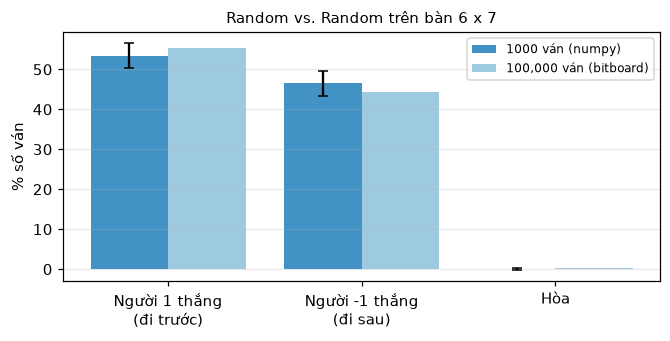

In [14]:
# Your code/ answer goes here.

def play_game(red, yellow, board = None, player = 1):
    """Một ván chơi. `red` điều khiển quân 1, `yellow` điều khiển quân -1; `player` là người đi trước (mặc định 1).
    Môi trường chỉ gửi cho tác tử bàn cờ + người cần đi và chỉ nhận lại một cột (đúng như HOWTO trong lớp).
    Trả về dict: winner (1, -1 hoặc 0), moves (số nước), time (tổng thời gian suy nghĩ mỗi bên), board (bàn cờ cuối)."""
    agents = {1: red, -1: yellow}
    board = initial_state() if board is None else board.copy()
    spent = {1: 0.0, -1: 0.0}
    moves = 0
    while not terminal(board):
        t0 = time.perf_counter()
        a = agents[player](board, player)
        spent[player] += time.perf_counter() - t0
        if a not in actions(board):
            raise ValueError(f"Tác tử của người {player} trả về hành động không hợp lệ: {a}")
        board = result(board, player, a)
        player, moves = -player, moves + 1
    return {"winner": winner(board), "moves": moves, "time": spent, "board": board}

def play(red, yellow, N = 100, shape = (6, 7)):
    """Cho hai tác tử chơi N ván trên bàn `shape` (`red` luôn đi trước). Trả về Counter {1: đỏ thắng, -1: vàng thắng, 0: hòa}."""
    results = Counter({1: 0, -1: 0, 0: 0})
    for _ in range(N):
        results[play_game(red, yellow, initial_state(shape))["winner"]] += 1
    return results

# ----- Hai tác tử ngẫu nhiên chơi 1000 ván -----
np.random.seed(2026)
t0 = time.time()
lengths = []
random_results = Counter({1: 0, -1: 0, 0: 0})
for _ in range(1000):
    g_ = play_game(random_player, random_player)
    random_results[g_["winner"]] += 1
    lengths.append(g_["moves"])
n = 1000
ci = lambda k: 1.96 * math.sqrt((k / n) * (1 - k / n) / n) * 100
random_table = pd.DataFrame({
    "Kết quả": ["Người 1 (đỏ, đi trước) thắng", "Người -1 (vàng, đi sau) thắng", "Hòa"],
    "Số ván": [random_results[1], random_results[-1], random_results[0]],
    "Tỷ lệ (%)": [100 * random_results[1] / n, 100 * random_results[-1] / n, 100 * random_results[0] / n],
    "Khoảng tin cậy 95 % (±)": [ci(random_results[1]), ci(random_results[-1]), ci(random_results[0])]}).round(1)
display(random_table)
print(f"Độ dài trung bình một ván: {np.mean(lengths):.1f} nước (ngắn nhất {min(lengths)}, dài nhất {max(lengths)}) – {time.time() - t0:.1f} s")

# ----- Ước lượng chính xác hơn bằng bitboard: 100000 ván ngẫu nhiên -----
def fast_random_games(rows, cols, n, seed = 0):
    """Chơi n ván ngẫu nhiên bằng bitboard (nhanh hơn ~50 lần); trả về (Counter kết quả, độ dài trung bình)."""
    g = Geometry.get(rows, cols)
    rng = random.Random(seed)
    res, total_len = Counter({1: 0, -1: 0, 0: 0}), 0
    for _ in range(n):
        cur = mask = 0
        open_cols, sign, plies = list(range(cols)), 1, 0       # sign = người đang đi (1 hoặc -1)
        while True:
            if not open_cols: res[0] += 1; break
            c = open_cols[int(rng.random() * len(open_cols))]
            nb = (mask + g.bottom[c]) & g.col_mask[c]
            plies += 1
            if g.is_win(cur | nb): res[sign] += 1; break
            cur, mask, sign = cur ^ mask, mask | nb, -sign
            if mask & g.top[c]: open_cols.remove(c)
        total_len += plies
    return res, total_len / n

t0 = time.time()
fast_res, fast_len = fast_random_games(6, 7, 100000, seed = 7)
NF = 100000
print(f"{NF:,} ván (bitboard): người 1 thắng {100 * fast_res[1] / NF:.1f} %, người -1 thắng {100 * fast_res[-1] / NF:.1f} %, hòa {100 * fast_res[0] / NF:.2f} %; độ dài TB {fast_len:.1f} nước  [{time.time() - t0:.0f} s]")

fig, ax = plt.subplots(figsize = (6.2, 3.2), dpi = 110)
labels = ["Người 1 thắng\n(đi trước)", "Người -1 thắng\n(đi sau)", "Hòa"]
x = np.arange(3)
ax.bar(x - 0.2, [100 * random_results[k] / n for k in (1, -1, 0)], 0.4, yerr = [ci(random_results[k]) for k in (1, -1, 0)], capsize = 3, label = f"{n} ván (numpy)", color = "#4292c6")
ax.bar(x + 0.2, [100 * fast_res[k] / NF for k in (1, -1, 0)], 0.4, label = f"{NF:,} ván (bitboard)", color = "#9ecae1")
ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylabel("% số ván"); ax.set_title("Random vs. Random trên bàn 6 x 7", fontsize = 10); ax.legend(fontsize = 8); ax.grid(axis = "y", alpha = .3)
plt.tight_layout(); plt.show()

In [15]:
first, second = 100 * fast_res[1] / NF, 100 * fast_res[-1] / NF
display(Markdown(f"""
**Kết quả:** trong {n} ván, người chơi 1 (đi trước) thắng **{random_results[1]}** ván ({100 * random_results[1] / n:.1f} %), người chơi -1 (đi sau) thắng **{random_results[-1]}** ván ({100 * random_results[-1] / n:.1f} %) và hòa **{random_results[0]}** ván ({100 * random_results[0] / n:.1f} %).
Ước lượng chính xác hơn từ {NF:,} ván bitboard: {first:.1f} % – {second:.1f} % – {100 * fast_res[0] / NF:.2f} %.

**Kết quả có đúng như mong đợi không? Có.**
* Hai tác tử giống hệt nhau nên chênh lệch chỉ do **lợi thế đi trước**: người đi trước luôn có số quân bằng hoặc nhiều hơn người đi sau tại mọi thời điểm và là người đầu tiên có thể tạo ra 4 quân liên tiếp (một ván ngẫu nhiên trung bình kết thúc sau chỉ ≈ {fast_len:.0f} nước), nên thắng nhiều hơn rõ rệt ({first:.1f} % so với {second:.1f} %). Chênh lệch này vượt xa khoảng tin cậy 95 % (± {ci(random_results[1]):.1f} %) của {n} ván.
* **Hòa rất hiếm** (≈ {100 * fast_res[0] / NF:.1f} %): chơi ngẫu nhiên không biết chặn, nên hầu như luôn có người tạo được 4 quân liên tiếp trước khi bàn cờ đầy (42 nước). Điều này khác Tic-Tac-Toe, nơi hòa chiếm ≈ 12 % số ván ngẫu nhiên.
* Tỷ lệ thắng của người đi trước ({first:.0f} %) là **đường cơ sở (baseline)** để so sánh các tác tử sau này: một tác tử thông minh phải thắng Random nhiều hơn mức này rất nhiều, ở cả hai vai.
"""))


**Kết quả:** trong 1000 ván, người chơi 1 (đi trước) thắng **534** ván (53.4 %), người chơi -1 (đi sau) thắng **465** ván (46.5 %) và hòa **1** ván (0.1 %).
Ước lượng chính xác hơn từ 100,000 ván bitboard: 55.4 % – 44.4 % – 0.27 %.

**Kết quả có đúng như mong đợi không? Có.**
* Hai tác tử giống hệt nhau nên chênh lệch chỉ do **lợi thế đi trước**: người đi trước luôn có số quân bằng hoặc nhiều hơn người đi sau tại mọi thời điểm và là người đầu tiên có thể tạo ra 4 quân liên tiếp (một ván ngẫu nhiên trung bình kết thúc sau chỉ ≈ 21 nước), nên thắng nhiều hơn rõ rệt (55.4 % so với 44.4 %). Chênh lệch này vượt xa khoảng tin cậy 95 % (± 3.1 %) của 1000 ván.
* **Hòa rất hiếm** (≈ 0.3 %): chơi ngẫu nhiên không biết chặn, nên hầu như luôn có người tạo được 4 quân liên tiếp trước khi bàn cờ đầy (42 nước). Điều này khác Tic-Tac-Toe, nơi hòa chiếm ≈ 12 % số ván ngẫu nhiên.
* Tỷ lệ thắng của người đi trước (55 %) là **đường cơ sở (baseline)** để so sánh các tác tử sau này: một tác tử thông minh phải thắng Random nhiều hơn mức này rất nhiều, ở cả hai vai.


## Task 3: Minimax Search with Alpha-Beta Pruning

### Implement the Search [10 points] 

Implement minimax search starting from a given board for specifying the player.

__Important Notes:__ 
* You can reuse code from the [tic-tac-toe examples](.).
* Make sure that all your agent functions have a signature consistent with the random agent above and that it [uses a class to store state information.](store_agent_state_information.ipynb)
This is essential to be able play against agents from other students later.
* The game tree for a $6 \times 7$ board is huge and optimal algorithms need to visit each or a large percentage of all nodes in the tree. You can experiment with smaller boards like a $4 \times 4$ board first.

In [16]:
# Your code/ answer goes here.

# =====================================================================================================
# (A) Bản tham chiếu, viết thẳng trên các hàm numpy (giống code Tic-Tac-Toe trên lớp) – dễ đọc nhưng chậm
# =====================================================================================================
class ReferenceAlphaBetaPlayer:
    """Minimax với cắt tỉa Alpha-Beta tới trạng thái kết thúc, dùng trực tiếp actions/result/utility (numpy)."""
    def __init__(self, name = "Alpha-Beta (numpy, bản tham chiếu)"):
        self.name, self.nodes, self.last_value = name, 0, None

    def __call__(self, board, player = 1):
        self.nodes = 0
        value = utility(board, player)
        if value is not None:
            self.last_value = value
            return None
        value, action = self.max_value(board, player, player, -math.inf, math.inf)
        self.last_value = value
        return action

    def max_value(self, state, me, mover, alpha, beta):
        """Giá trị của `state` đối với `me` khi `mover` (= me) đi."""
        self.nodes += 1
        v, move = -math.inf, None
        for a in actions(state):
            nxt = result(state, mover, a)
            u = utility(nxt, me)
            v2 = u if u is not None else self.min_value(nxt, me, -mover, alpha, beta)[0]
            if v2 > v:
                v, move = v2, a
                alpha = max(alpha, v)
            if v >= beta: return v, move
        return v, move

    def min_value(self, state, me, mover, alpha, beta):
        self.nodes += 1
        v, move = math.inf, None
        for a in actions(state):
            nxt = result(state, mover, a)
            u = utility(nxt, me)
            v2 = u if u is not None else self.max_value(nxt, me, -mover, alpha, beta)[0]
            if v2 < v:
                v, move = v2, a
                beta = min(beta, v)
            if v <= alpha: return v, move
        return v, move


# =====================================================================================================
# (B) Bản nhanh: negamax + Alpha-Beta trên bitboard. Dùng một LỚP để lưu trạng thái của tác tử (số nút, bảng chuyển vị...)
# =====================================================================================================
class AlphaBetaPlayer:
    """Minimax (dạng negamax) với cắt tỉa Alpha-Beta tới trạng thái kết thúc (KHÔNG giới hạn độ sâu).

    Giá trị trả về là giá trị lý thuyết của ván cờ đối với người đang đi: +1 thắng, 0 hòa, -1 thua.
    Tùy chọn (mặc định: duyệt từ giữa, không kiểm tra thắng sớm/cắt nước thua/bảng chuyển vị):
      ordering     : thứ tự duyệt cột – "natural" (0..cols-1), "center" (từ giữa ra), "edges" (từ biên vào, tệ nhất), "random"
      win_first    : trước khi đệ quy, kiểm tra xem có nước THẮNG NGAY không
      forced       : cắt các nước chắc chắn thua: có nước thắng ngay thì trả về +1; đối thủ đe dọa thắng ngay thì CHỈ xét nước chặn
                     (nếu có 2 đe dọa thì thua); không đi ngay dưới ô thắng của đối thủ
      use_tt       : bảng chuyển vị (lưu giá trị đúng/cận trên/cận dưới của mỗi vị trí)
      symmetry_root: nếu bàn cờ đối xứng trái-phải, chỉ xét một nửa số cột ở gốc
      node_limit   : dừng (ném NodeLimit) nếu duyệt quá số nút này – dùng để đo các trường hợp "không khả thi"
    """
    class NodeLimit(Exception):
        pass

    def __init__(self, ordering = "center", win_first = False, forced = False, use_tt = False, symmetry_root = False,
                 node_limit = None, tt_max = 2_000_000, seed = 0, name = None):
        self.ordering, self.win_first, self.forced, self.use_tt = ordering, win_first, forced, use_tt
        self.symmetry_root, self.node_limit, self.tt_max = symmetry_root, node_limit, tt_max
        self.rng = random.Random(seed)
        self.tt = {}                       # bảng chuyển vị: khóa -> (cờ, giá trị); giữ lại giữa các lần gọi
        self.nodes, self.last_value = 0, None
        parts = [ordering] + (["win"] if win_first else []) + (["forced"] if forced else []) + (["TT"] if use_tt else []) + (["sym"] if symmetry_root else [])
        self.name = name or "Alpha-Beta(" + "+".join(parts) + ")"

    # --- giao diện đúng như đề: agent(board, player) -> cột ---
    def __call__(self, board, player = 1):
        g = Geometry.get(*board.shape)
        cur, mask = g.to_bits(board, player)
        column, value = self.search(g, cur, mask)
        self.last_value = value
        return column

    def value(self, board, player = 1):
        """Giá trị lý thuyết (+1/0/-1) của bàn cờ đối với `player` đang đến lượt."""
        g = Geometry.get(*board.shape)
        cur, mask = g.to_bits(board, player)
        return self.search(g, cur, mask)[1]

    def action_values(self, board, player = 1):
        """Giá trị lý thuyết của TỪNG nước đi hợp lệ (đối với `player`): dict cột -> +1/0/-1."""
        g = Geometry.get(*board.shape)
        cur, mask = g.to_bits(board, player)
        return self.search(g, cur, mask, analyze = True)[1]

    def search(self, g, cur, mask, analyze = False):
        cols, cells = g.cols, g.cells
        bottom, colm, top = g.bottom, g.col_mask, g.top
        board_mask, bottom_all = g.board_mask, g.bottom_all
        is_win, winning_cells = g.is_win, g.winning_cells
        self.nodes = 0
        if is_win(cur) or is_win(cur ^ mask) or mask == board_mask:
            value = 1 if is_win(cur) else (-1 if is_win(cur ^ mask) else 0)
            return (None, {}) if analyze else (None, value)
        win_first, forced, tt, rng = self.win_first, self.forced, (self.tt if self.use_tt else None), self.rng
        if tt is not None and len(tt) > self.tt_max: tt.clear()
        static = {"natural": list(range(cols)), "center": g.center_order, "edges": g.center_order[::-1], "random": None}[self.ordering]
        limit = self.node_limit or float("inf")
        nodes = 0

        def negamax(cur, mask, nm, alpha, beta):
            """Giá trị (đối với người đang đi, sở hữu `cur`) của vị trí chưa kết thúc; nm = số quân trên bàn."""
            nonlocal nodes
            nodes += 1
            if nodes > limit: raise AlphaBetaPlayer.NodeLimit()
            if nm == cells: return 0                                    # bàn cờ đầy: hòa
            if tt is not None:
                key = (g.rows, g.cols, cur + mask)                       # Không dùng lẫn kết quả giữa các kích thước bàn.
                entry = tt.get(key)
                if entry is not None:
                    flag, val = entry
                    if flag == 0: return val                            # giá trị chính xác
                    if flag == 1:                                       # cận dưới
                        if val >= beta: return val
                        if val > alpha: alpha = val
                    else:                                               # cận trên
                        if val <= alpha: return val
                        if val < beta: beta = val
                    if alpha >= beta: return val
                alpha0 = alpha
            opp = cur ^ mask
            order = static if static is not None else rng.sample(range(cols), cols)
            if forced:
                possible = (mask + bottom_all) & board_mask             # ô có thể đặt quân ngay (mỗi cột một ô)
                if winning_cells(cur, mask) & possible: return 1        # có nước thắng ngay
                danger = winning_cells(opp, mask)                       # các ô mà đối thủ sẽ thắng nếu đặt vào
                must = danger & possible
                if must:
                    if must & (must - 1): return -1                     # hai đe dọa cùng lúc: không chặn nổi
                    possible = must                                     # chỉ còn nước chặn
                else:
                    possible &= ~(danger >> 1)                          # không đặt quân ngay dưới ô thắng của đối thủ
                    if not possible: return -1
                order = [c for c in order if possible & colm[c]]
            elif win_first:
                for c in order:
                    if not (mask & top[c]) and is_win(cur | ((mask + bottom[c]) & colm[c])): return 1
            best = -2
            for c in order:
                if mask & top[c]: continue
                nb = (mask + bottom[c]) & colm[c]                       # ô mà quân mới chiếm
                if not forced and not win_first and is_win(cur | nb):
                    v = 1
                else:
                    v = -negamax(opp, mask | nb, nm + 1, -beta, -alpha)
                if v > best:
                    best = v
                    if v > alpha:
                        alpha = v
                        if alpha >= beta: break                         # cắt tỉa beta
            if tt is not None:
                tt[key] = (2 if best <= alpha0 else (1 if best >= beta else 0), best)
            return best

        # ---- gốc cây: duyệt từng nước để biết nước đi tốt nhất ----
        nm0 = popcount(mask)
        columns = static if static is not None else rng.sample(range(cols), cols)
        if self.symmetry_root and not analyze and g.mirror(cur) == cur and g.mirror(mask) == mask:
            columns = [c for c in columns if c <= (cols - 1) // 2]      # vị trí đối xứng: nửa còn lại cho giá trị tương đương
        best, best_col, values = -2, None, {}
        alpha, beta = -1, 1
        opp = cur ^ mask
        try:
            for c in columns:
                if mask & top[c]: continue
                nb = (mask + bottom[c]) & colm[c]
                if is_win(cur | nb): v = 1
                else: v = -negamax(opp, mask | nb, nm0 + 1, -1 if analyze else -beta, 1 if analyze else -alpha)
                values[c] = v
                if v > best:
                    best, best_col = v, c
                    if not analyze and v > alpha:
                        alpha = v
                        if alpha >= beta: break
        finally:
            self.nodes = nodes
        return (best_col, best) if not analyze else (best_col, values)

**Kiểm tra tính đúng đắn.** Trước khi dùng bản bitboard cho các thí nghiệm, ta kiểm tra nó trên các bàn nhỏ (nơi Minimax thuần túy còn tính nổi): cả năm biến thể bitboard (khác nhau ở thứ tự duyệt, kiểm tra nước thắng ngay, cắt nước chắc thua, bảng chuyển vị) phải cho **cùng giá trị** và chọn **nước đi tối ưu** giống bản numpy tham chiếu và Minimax không cắt tỉa; các lệnh `assert` bên dưới sẽ báo lỗi nếu có khác biệt.

In [17]:
# ---- Kiểm tra chéo: bản bitboard cho CÙNG giá trị và nước đi tối ưu như bản numpy tham chiếu và Minimax thuần ----
def minimax_values(board, player, memo):
    """Giá trị Minimax của từng nước đi, bản đơn giản nhất (không cắt tỉa, có nhớ kết quả) – dùng làm chuẩn để so sánh."""
    def value(b, mover):                         # giá trị của b (chưa kết thúc) đối với `mover` đang đi
        key = (b.tobytes(), mover)
        if key not in memo:
            best = -2
            for a in actions(b):
                nxt = result(b, mover, a)
                u = utility(nxt, mover)
                best = max(best, u if u is not None else -value(nxt, -mover))
            memo[key] = best
        return memo[key]
    out = {}
    for a in actions(board):
        nxt = result(board, player, a)
        u = utility(nxt, player)
        out[a] = u if u is not None else -value(nxt, -player)
    return out

def cross_validate(shapes, per_shape = 25, seed = 3):
    rng = random.Random(seed)
    variants = [dict(ordering = "natural"), dict(ordering = "center", win_first = True), dict(ordering = "center", forced = True),
                dict(ordering = "center", use_tt = True), dict(ordering = "random", forced = True, use_tt = True)]
    rows_out = []
    for shape in shapes:
        memo, n_pos = {}, 0
        ref = ReferenceAlphaBetaPlayer()
        for _ in range(per_shape):
            b, p = initial_state(shape), 1
            for _ in range(rng.randint(0, 7)):
                if terminal(b): break
                b = result(b, p, rng.choice(actions(b))); p = -p
            if terminal(b): continue
            vals = minimax_values(b, p, memo)
            best = max(vals.values())
            optimal = {a for a, v in vals.items() if v == best}
            a_ref = ref(b, p)
            assert ref.last_value == best and a_ref in optimal
            for kw in variants:
                ab = AlphaBetaPlayer(**kw)
                a = ab(b, p)
                assert ab.last_value == best and a in optimal, (shape, kw)
                assert AlphaBetaPlayer(**kw).action_values(b, p) == vals
            n_pos += 1
        rows_out.append({"Kích thước": f"{shape[0]} x {shape[1]}", "Số vị trí thử": n_pos, "Số biến thể bitboard so sánh": len(variants) + 1, "Kết quả": "giá trị và nước đi đều khớp Minimax"})
    return pd.DataFrame(rows_out)

display(cross_validate([(4, 4), (4, 3), (5, 4), (3, 5)], per_shape = 25))

,Kích thước,Số vị trí thử,Số biến thể bitboard so sánh,Kết quả
0,4 x 4,25,6,giá trị và nước đi đều khớp Minimax
1,4 x 3,25,6,giá trị và nước đi đều khớp Minimax
2,5 x 4,25,6,giá trị và nước đi đều khớp Minimax
3,3 x 5,25,6,giá trị và nước đi đều khớp Minimax


Experiment with some manually created boards (at least 5) to check if the agent spots winning opportunities.

,Bàn cờ,Đến lượt,Ô trống,Giá trị lý thuyết,Thắng ép sau (nửa-nước),Giá trị mỗi cột (đúng),Cột Alpha-Beta chọn,Chọn đúng?,Số nút,Thời gian (s)
0,1. Thắng ngay,X (đỏ),14,thắng,1,0:-1 2:+1 5:-1 6:-1,2,có,56,0.000
1,2. Phải chặn,X (đỏ),12,hòa,—,0:-1 1:+0 6:-1,1,có,946,0.001
2,3. Thắng sau 3 nửa-nước,X (đỏ),16,thắng,3,0:+1 1:+1 3:+1 4:+1 6:-1,0,có,530,0.001
3,4. Thắng sau 5 nửa-nước,O (vàng),21,thắng,5,0:-1 1:+1 4:+1 5:+1 6:+0,1,có,"366,613",0.410
4,5. Thắng sau 7 nửa-nước,X (đỏ),20,thắng,7,0:-1 1:-1 3:-1 4:-1 5:-1 6:+1,6,có,"695,364",0.816
5,6. Chỉ hòa nếu đi đúng,O (vàng),19,hòa,—,0:-1 1:-1 4:-1 5:+0 6:+0,5,có,"55,231",0.061
6,7. Thế thua,O (vàng),21,thua,—,0:-1 1:-1 4:-1 5:-1 6:-1,0,có,"4,177",0.005


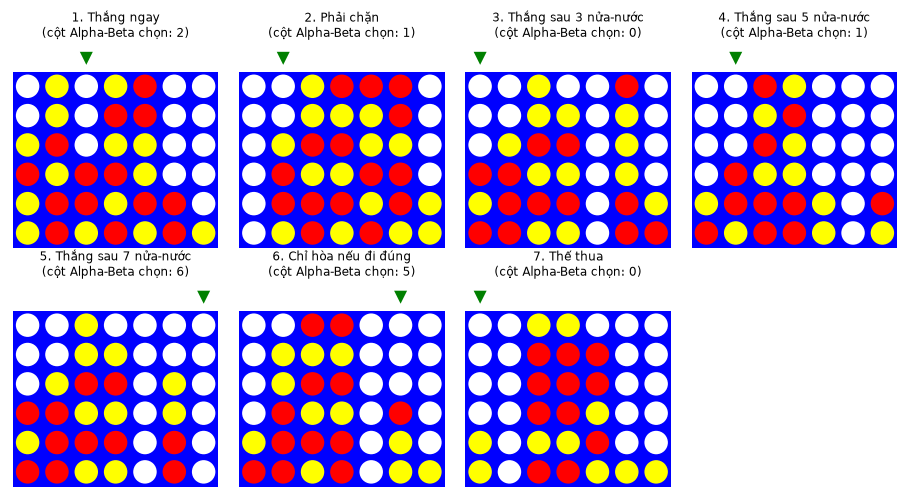

In [18]:
# Your code/ answer goes here.

# ---- Các bàn cờ thử nghiệm tự tạo (bàn chuẩn 6 x 7; 'X' = người 1 (đỏ), 'O' = người -1 (vàng), '.' = trống) ----
# Mỗi bàn minh họa một chủ đề chiến thuật; kết luận lý thuyết (cột nào thắng/hòa/thua) được tính bằng bộ giải chính xác bên dưới.
TEST_BOARDS = {
    "1. Thắng ngay": board_from_strings([
        ".O.OX..", ".O.XX..", "OX.OO..", "XOXXO..", "OXXOXX.", "OXOXOXO"]),
    "2. Phải chặn": board_from_strings([
        "..OXXX.", "..OOOX.", ".OXXOO.", ".XOOXX.", ".XXXOXO", ".OXOXOO"]),
    "3. Thắng sau 3 nửa-nước": board_from_strings([
        "..O..X.", "..OO.O.", ".OXX.O.", "XXOO.O.", "OXXX.XO", "XXOO.XX"]),
    "4. Thắng sau 5 nửa-nước": board_from_strings([
        "..XO...", "..OX...", "..XO...", ".XOO...", "OXXXO.X", "XOXXO.O"]),
    "5. Thắng sau 7 nửa-nước": board_from_strings([
        "..O....", "..OO...", ".OXX.O.", "XXOO.O.", "OXXX.X.", "XXOO.X."]),
    "6. Chỉ hòa nếu đi đúng": board_from_strings([
        "..XX...", ".OOO...", ".OXX...", ".XOO.X.", "OXXX.O.", "XXOX.OO"]),
    "7. Thế thua": board_from_strings([
        "..OO...", "..XXX..", "..XXX..", "..XXO..", "O.OOX..", "O.XXOOO"]),
}
TEST_NAMES = list(TEST_BOARDS)

def forced_win_plies(board, player, max_plies = 9):
    """Số nửa-nước ít nhất để `player` (đang đi) ép thắng (1 = thắng ngay, 3, 5, ...), hoặc None nếu không ép thắng được trong max_plies."""
    g = Geometry.get(*board.shape)
    cur, mask = g.to_bits(board, player)
    memo = {}
    def win_within(cur, mask, d):
        key = (cur, mask, d)
        if key in memo: return memo[key]
        moves = []
        for c in range(g.cols):
            if mask & g.top[c]: continue
            nb = (mask + g.bottom[c]) & g.col_mask[c]
            if g.is_win(cur | nb): memo[key] = True; return True
            moves.append(nb)
        res = False
        if d >= 3:
            opp = cur ^ mask
            for nb in moves:                                   # tồn tại nước đi sao cho MỌI phản ứng của đối thủ đều dẫn tới thắng
                nmask, ok, replies = mask | nb, True, 0
                for c2 in range(g.cols):
                    if nmask & g.top[c2]: continue
                    replies += 1
                    nb2 = (nmask + g.bottom[c2]) & g.col_mask[c2]
                    if g.is_win(opp | nb2) or not win_within(cur | nb, nmask | nb2, d - 2): ok = False; break
                if ok and replies: res = True; break
        memo[key] = res
        return res
    for d in range(1, max_plies + 1, 2):
        if win_within(cur, mask, d): return d
    return None

# bộ giải chính xác (nhanh nhất): dùng để biết đáp án đúng; bảng chuyển vị được giữ lại giữa các lần gọi
solver = AlphaBetaPlayer(ordering = "center", forced = True, use_tt = True, name = "bộ giải chính xác")

def analyse(board, player):
    vals = solver.action_values(board, player)
    best = max(vals.values())
    return vals, {c for c, v in vals.items() if v == best}, best

TEST_INFO = {}
for name, b in TEST_BOARDS.items():
    p = player_to_move(b)
    vals, optimal, best = analyse(b, p)
    TEST_INFO[name] = dict(player = p, values = vals, optimal = optimal, value = best, win_plies = forced_win_plies(b, p) if best == 1 else None)

# ---- Thuật toán thuần (thứ tự trái -> phải, không bảng chuyển vị) có tìm ra nước đi tối ưu không? ----
rows_out, chosen = [], []
for name, b in TEST_BOARDS.items():
    info = TEST_INFO[name]
    ab = AlphaBetaPlayer(ordering = "natural")
    t0 = time.perf_counter()
    a = ab(b, info["player"])
    dt = time.perf_counter() - t0
    chosen.append(a)
    rows_out.append({"Bàn cờ": name, "Đến lượt": "X (đỏ)" if info["player"] == 1 else "O (vàng)", "Ô trống": int((b == 0).sum()),
                     "Giá trị lý thuyết": {1: "thắng", 0: "hòa", -1: "thua"}[info["value"]],
                     "Thắng ép sau (nửa-nước)": info["win_plies"] if info["win_plies"] else "—",
                     "Giá trị mỗi cột (đúng)": " ".join(f"{c}:{info['values'][c]:+d}" for c in sorted(info["values"])),
                     "Cột Alpha-Beta chọn": a, "Chọn đúng?": "có" if a in info["optimal"] else "KHÔNG",
                     "Số nút": f"{ab.nodes:,}", "Thời gian (s)": round(dt, 3)})
display(pd.DataFrame(rows_out))
visualize_grid(list(TEST_BOARDS.values()), [f"{n}\n(cột Alpha-Beta chọn: {a})" for n, a in zip(TEST_NAMES, chosen)], marks = chosen, ncols = 4)

In [19]:
n_ok = sum(c in TEST_INFO[n]["optimal"] for n, c in zip(TEST_NAMES, chosen))
node_counts = {r["Bàn cờ"]: int(r["Số nút"].replace(",", "")) for r in rows_out}
win_info = sorted((TEST_INFO[n]["win_plies"], n) for n in TEST_NAMES if TEST_INFO[n]["win_plies"])
by_value = {v: [n for n in TEST_NAMES if TEST_INFO[n]["value"] == v] for v in (1, 0, -1)}
wins_txt = "; ".join(f"thắng sau {k} nửa-nước: {node_counts[n]:,} nút" for k, n in win_info)
block = [n for n in by_value[0] if len(TEST_INFO[n]["optimal"]) < len(TEST_INFO[n]["values"])]
lost = by_value[-1]
display(Markdown(f"""
**Nhận xét.** Alpha-Beta thuần tìm tới cuối ván nên là thuật toán **chính xác**: nó chọn đúng nước tối ưu ở **{n_ok}/{len(TEST_NAMES)} bàn thử** ("đúng" = cột đạt giá trị lý thuyết cao nhất; bảng còn liệt kê giá trị của *từng* cột). Các bàn thử phủ ba loại tình huống:

* **Cơ hội thắng** ({len(win_info)} bàn): tác tử không chỉ thấy nước thắng ngay mà còn tìm ra đòn thắng ép dài tới {win_info[-1][0] if win_info else '–'} nửa-nước. Độ dài chuỗi thắng ép được tính độc lập bằng hàm `forced_win_plies` (tìm kiếm thắng ép theo độ sâu tăng dần) và khớp với giá trị Minimax. Chi phí tăng rất nhanh theo độ dài chuỗi thắng: {wins_txt}.
* **Phải chặn** ({len(block)} bàn có giá trị lý thuyết là hòa nhưng *chỉ* một số cột giữ được hòa): tác tử chọn đúng cột chặn; các cột còn lại có giá trị −1 (thua) – xem cột "Giá trị mỗi cột".
* **Thế thua** ({len(lost)} bàn): mọi cột đều có giá trị −1 nên không có nước "đúng"; Minimax chỉ biết thua hay không thua, không phân biệt thua nhanh hay chậm, nên chọn cột đầu tiên theo thứ tự duyệt (bản chất của giá trị ±1, không phải lỗi của cài đặt).

Kết quả trên 7 bàn hỗ trợ kiểm chứng cài đặt, nhưng không thay thế chứng minh tính đúng đắn của Alpha-Beta. Chi phí (hàng trăm nghìn nút cho đòn thắng 5–7 nửa-nước) cho thấy vì sao không thể áp dụng nguyên xi cho bàn trống (xem mục tiếp theo).
"""))


**Nhận xét.** Alpha-Beta thuần tìm tới cuối ván nên là thuật toán **chính xác**: nó chọn đúng nước tối ưu ở **7/7 bàn thử** ("đúng" = cột đạt giá trị lý thuyết cao nhất; bảng còn liệt kê giá trị của *từng* cột). Các bàn thử phủ ba loại tình huống:

* **Cơ hội thắng** (4 bàn): tác tử không chỉ thấy nước thắng ngay mà còn tìm ra đòn thắng ép dài tới 7 nửa-nước. Độ dài chuỗi thắng ép được tính độc lập bằng hàm `forced_win_plies` (tìm kiếm thắng ép theo độ sâu tăng dần) và khớp với giá trị Minimax. Chi phí tăng rất nhanh theo độ dài chuỗi thắng: thắng sau 1 nửa-nước: 56 nút; thắng sau 3 nửa-nước: 530 nút; thắng sau 5 nửa-nước: 366,613 nút; thắng sau 7 nửa-nước: 695,364 nút.
* **Phải chặn** (2 bàn có giá trị lý thuyết là hòa nhưng *chỉ* một số cột giữ được hòa): tác tử chọn đúng cột chặn; các cột còn lại có giá trị −1 (thua) – xem cột "Giá trị mỗi cột".
* **Thế thua** (1 bàn): mọi cột đều có giá trị −1 nên không có nước "đúng"; Minimax chỉ biết thua hay không thua, không phân biệt thua nhanh hay chậm, nên chọn cột đầu tiên theo thứ tự duyệt (bản chất của giá trị ±1, không phải lỗi của cài đặt).

Kết quả trên 7 bàn hỗ trợ kiểm chứng cài đặt, nhưng không thay thế chứng minh tính đúng đắn của Alpha-Beta. Chi phí (hàng trăm nghìn nút cho đòn thắng 5–7 nửa-nước) cho thấy vì sao không thể áp dụng nguyên xi cho bàn trống (xem mục tiếp theo).


How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns/rows. Explain why using this algorithm on a standard $6 \times 7$ board is not feasible.

,Hàng x cột,Số ô,Thuần: số nút,Thuần: thời gian (s),Cải tiến: số nút,Cải tiến: thời gian (s),Kết quả lý thuyết cho người đi trước
0,4 x 4,16,"50,047",0.04,"12,511",0.03,hòa
1,5 x 4,20,"1,008,969",0.68,"47,985",0.11,hòa
2,6 x 4,24,"> 5,000,001",> 3.2 (dừng),"488,016",1.18,hòa
3,4 x 5,20,"> 5,000,001",> 3.3 (dừng),"82,958",0.18,hòa
4,5 x 5,25,"> 5,000,001",> 3.3 (dừng),"1,071,715",2.73,hòa
5,4 x 6,24,"> 5,000,001",> 3.7 (dừng),"1,162,358",2.90,thua
6,6 x 7,42,"> 5,000,001",> 5.1 (dừng),"> 3,000,001",> 10.3 (dừng),?


Thuần = thứ tự trái → phải, không bảng chuyển vị. Cải tiến = thứ tự từ giữa + cắt nước chắc thua + bảng chuyển vị. Giới hạn: 5,000,000 / 3,000,000 nút (dừng nếu vượt).
Thuần: số nút ×2.1 mỗi ô thêm vào (khớp trên 2 bàn đã giải xong) ⇒ ngoại suy cho 6 x 7: ≈ 1.5e+13 nút ≈ 192 ngày ở tốc độ đo được 907,914 nút/s.
Cải tiến: số nút ×1.7 mỗi ô thêm vào (khớp trên 6 bàn đã giải xong) ⇒ ngoại suy cho 6 x 7: ≈ 8.3e+09 nút ≈ 3 giờ ở tốc độ đo được 907,914 nút/s.
Mốc minh họa sqrt(kích thước cây, Task 1), KHÔNG phải cận dưới chính xác cho bàn Connect 4: 4.4e+14 nút ≈ 15.5 năm.


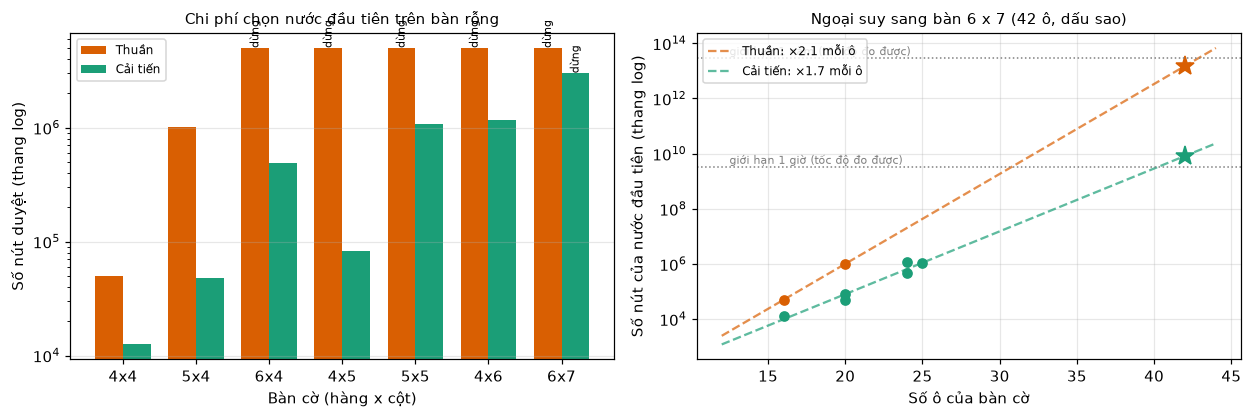

In [20]:
# Your code/ answer goes here.

def first_move_cost(shape, node_limit, **kw):
    """Chi phí chọn nước đầu tiên (bàn rỗng = trường hợp xấu nhất) cho tác tử Alpha-Beta với các tùy chọn kw."""
    ab = AlphaBetaPlayer(node_limit = node_limit, **kw)
    t0 = time.perf_counter()
    try:
        ab(initial_state(shape), 1); done = True
    except AlphaBetaPlayer.NodeLimit:
        done = False
    return dict(done = done, nodes = ab.nodes, time = time.perf_counter() - t0, value = ab.last_value if done else None)

SIZES = [(4, 4), (5, 4), (6, 4), (4, 5), (5, 5), (4, 6), (6, 7)]        # (số hàng, số cột): bắt đầu với 4 cột rồi thêm hàng/cột
PLAIN_LIMIT, BEST_LIMIT = 5000000, 3000000
rows_out, size_data = [], {}
for shape in SIZES:
    plain = first_move_cost(shape, PLAIN_LIMIT, ordering = "natural")
    best = first_move_cost(shape, BEST_LIMIT, ordering = "center", forced = True, use_tt = True)
    size_data[shape] = (plain, best)
    fmt = lambda r, key: (f"{r['nodes']:,}" if key == "nodes" else f"{r['time']:.2f}") if r["done"] else (f"> {r['nodes']:,}" if key == "nodes" else f"> {r['time']:.1f} (dừng)")
    rows_out.append({"Hàng x cột": f"{shape[0]} x {shape[1]}", "Số ô": shape[0] * shape[1],
                     "Thuần: số nút": fmt(plain, "nodes"), "Thuần: thời gian (s)": fmt(plain, "time"),
                     "Cải tiến: số nút": fmt(best, "nodes"), "Cải tiến: thời gian (s)": fmt(best, "time"),
                     "Kết quả lý thuyết cho người đi trước": {1: "thắng", 0: "hòa", -1: "thua", None: "?"}[best["value"]]})
display(pd.DataFrame(rows_out))
print(f"Thuần = thứ tự trái → phải, không bảng chuyển vị. Cải tiến = thứ tự từ giữa + cắt nước chắc thua + bảng chuyển vị. Giới hạn: {PLAIN_LIMIT:,} / {BEST_LIMIT:,} nút (dừng nếu vượt).")

# ---- Chi phí tăng theo số ô của bàn cờ: số nút ≈ c · g^(số ô). Khớp trên các bàn đã giải xong rồi ngoại suy cho 6 x 7 (42 ô) ----
ab_rate = float(np.mean([r["nodes"] / r["time"] for s in SIZES for r in size_data[s] if r["time"] > 0.05]))      # nút / giây của mã Python bitboard
fits = {}
for k, lab in enumerate(("Thuần", "Cải tiến")):
    pts = sorted({(s[0] * s[1], size_data[s][k]["nodes"]) for s in SIZES if size_data[s][k]["done"]})
    if len({c for c, _ in pts}) >= 2:
        slope, icpt = np.polyfit([c for c, _ in pts], np.log([n for _, n in pts]), 1)
        fits[lab] = dict(g = math.exp(slope), a = icpt, b = slope, n_boards = len(pts), pred = math.exp(icpt + slope * 42))
YEAR = 3600 * 24 * 365
def human(sec):
    """Đổi số giây thành đơn vị dễ đọc."""
    if sec < 90: return f"{sec:.0f} giây"
    if sec < 5400: return f"{sec / 60:.0f} phút"
    if sec < 2 * 86400: return f"{sec / 3600:.0f} giờ"
    if sec < 2 * 365 * 86400: return f"{sec / 86400:.0f} ngày"
    return f"{sec / YEAR:.1f} năm"
for lab, f in fits.items():
    print(f"{lab}: số nút ×{f['g']:.1f} mỗi ô thêm vào (khớp trên {f['n_boards']} bàn đã giải xong) ⇒ ngoại suy cho 6 x 7: ≈ {f['pred']:.2g} nút "
          f"≈ {human(f['pred'] / ab_rate)} ở tốc độ đo được {ab_rate:,.0f} nút/s.")
print(f"Mốc minh họa sqrt(kích thước cây, Task 1), KHÔNG phải cận dưới chính xác cho bàn Connect 4: {math.sqrt(tree_est):.2g} nút ≈ {human(math.sqrt(tree_est) / ab_rate)}.")

fig, ax = plt.subplots(1, 2, figsize = (11.5, 3.9), dpi = 110)
labels = [f"{s[0]}x{s[1]}" for s in SIZES]
xs = np.arange(len(SIZES))
for k, (lab, color) in enumerate((("Thuần", "#d95f02"), ("Cải tiến", "#1b9e77"))):
    ns = [size_data[s][k]["nodes"] for s in SIZES]
    done = [size_data[s][k]["done"] for s in SIZES]
    ax[0].bar(xs + (k - .5) * .38, ns, .38, label = lab, color = color)
    for x_, n_, d_ in zip(xs, ns, done):
        if not d_: ax[0].text(x_ + (k - .5) * .38, n_, "dừng", rotation = 90, ha = "center", va = "bottom", fontsize = 7)
ax[0].set_yscale("log"); ax[0].set_xticks(xs); ax[0].set_xticklabels(labels); ax[0].set_xlabel("Bàn cờ (hàng x cột)"); ax[0].set_ylabel("Số nút duyệt (thang log)")
ax[0].set_title("Chi phí chọn nước đầu tiên trên bàn rỗng", fontsize = 10); ax[0].legend(fontsize = 8); ax[0].grid(axis = "y", alpha = .3)
cells_x = np.arange(12, 45)
for lab, color in (("Thuần", "#d95f02"), ("Cải tiến", "#1b9e77")):
    k = 0 if lab == "Thuần" else 1
    pts = sorted({(s[0] * s[1], size_data[s][k]["nodes"]) for s in SIZES if size_data[s][k]["done"]})
    if lab in fits:
        f = fits[lab]
        ax[1].plot(cells_x, np.exp(f["a"] + f["b"] * cells_x), "--", color = color, alpha = .7, label = f"{lab}: ×{f['g']:.1f} mỗi ô")
        ax[1].plot([42], [f["pred"]], "*", ms = 13, color = color)
    ax[1].plot([c for c, _ in pts], [n for _, n in pts], "o", color = color)
for sec, name in ((ab_rate * 3600, "1 giờ"), (ab_rate * YEAR, "1 năm")):
    ax[1].axhline(sec, color = "gray", ls = ":", lw = 1); ax[1].text(12.5, sec * 1.3, f"giới hạn {name} (tốc độ đo được)", fontsize = 7, color = "gray")
ax[1].set_yscale("log"); ax[1].set_xlabel("Số ô của bàn cờ"); ax[1].set_ylabel("Số nút của nước đầu tiên (thang log)"); ax[1].legend(fontsize = 8, loc = "upper left")
ax[1].set_title("Ngoại suy sang bàn 6 x 7 (42 ô, dấu sao)", fontsize = 10); ax[1].grid(alpha = .3)
plt.tight_layout(); plt.show()

In [21]:
solved_plain = [s for s in SIZES if size_data[s][0]["done"]]
solved_best = [s for s in SIZES if size_data[s][1]["done"]]
shp = lambda s: f"{s[0]} × {s[1]}"
same_cells = [(a, b) for a in SIZES for b in SIZES if a[0] * a[1] == b[0] * b[1] and a[0] > b[0] and size_data[a][1]["done"] and size_data[b][1]["done"]]
cells_txt = ""
if same_cells:
    a, b = same_cells[0]
    na, nb = size_data[a][1]["nodes"], size_data[b][1]["nodes"]
    cells_txt = f"* **Thêm hàng hay thêm cột?** Hai bàn cùng {a[0] * a[1]} ô nhưng hình dạng khác nhau tốn chi phí khác nhau: {shp(a)} cần {na:,} nút, {shp(b)} cần {nb:,} nút (bản cải tiến) – hình dạng bàn ảnh hưởng không kém số ô."
fit_p, fit_b = fits.get("Thuần"), fits.get("Cải tiến")
display(Markdown(f"""
**Nhận xét.**
* **Chi phí tăng gần như theo hàm mũ với số ô.** Thuật toán thuần chỉ giải xong {len(solved_plain)}/{len(SIZES)} bàn ({', '.join(shp(s) for s in solved_plain) or 'không bàn nào'}) trong giới hạn {PLAIN_LIMIT:,} nút; phiên bản cải tiến (thứ tự từ giữa, cắt nước chắc thua, bảng chuyển vị) giải xong {len(solved_best)}/{len(SIZES)} bàn, bàn lớn nhất giải được là {shp(max(solved_best, key = lambda s: s[0] * s[1]))} ({max(solved_best, key = lambda s: s[0] * s[1])[0] * max(solved_best, key = lambda s: s[0] * s[1])[1]} ô).
{'* **Hệ số tăng:** mỗi ô thêm vào nhân số nút lên ≈ ×' + format(fit_p['g'], '.1f') + ' (thuần) và ≈ ×' + format(fit_b['g'], '.1f') + ' (cải tiến) – cải tiến không đổi bản chất hàm mũ mà chỉ hạ hệ số xuống.' if fit_p and fit_b else '* Số bàn giải xong chưa đủ để khớp hệ số tăng cho cả hai phiên bản.'}
{cells_txt}
{'* **Ngoại suy cho bàn 6 × 7 (42 ô):** ≈ ' + format(fit_b['pred'], '.1g') + ' nút (cải tiến) ≈ ' + human(fit_b['pred'] / ab_rate) + ' ở tốc độ Python đo được' + (', còn thuật toán thuần ≈ ' + format(fit_p['pred'], '.1g') + ' nút ≈ ' + human(fit_p['pred'] / ab_rate) if fit_p else '') + '. Ngoại suy từ bàn nhỏ chỉ cho bậc độ lớn (hệ số tăng thực tế thay đổi theo hình dạng bàn), nhưng đủ để kết luận bài toán nằm ở ranh giới không thực dụng với Python.' if fit_b else ''}
* **Kết luận:** muốn chơi bàn chuẩn trong thời gian chấp nhận được cần **không tìm tới cuối ván**: cắt tìm kiếm ở độ sâu cố định và đánh giá bằng hàm heuristic (Task 4), hoặc dùng ước lượng thống kê (Pure Monte Carlo, Task 5).
"""))


**Nhận xét.**
* **Chi phí tăng gần như theo hàm mũ với số ô.** Thuật toán thuần chỉ giải xong 2/7 bàn (4 × 4, 5 × 4) trong giới hạn 5,000,000 nút; phiên bản cải tiến (thứ tự từ giữa, cắt nước chắc thua, bảng chuyển vị) giải xong 6/7 bàn, bàn lớn nhất giải được là 5 × 5 (25 ô).
* **Hệ số tăng:** mỗi ô thêm vào nhân số nút lên ≈ ×2.1 (thuần) và ≈ ×1.7 (cải tiến) – cải tiến không đổi bản chất hàm mũ mà chỉ hạ hệ số xuống.
* **Thêm hàng hay thêm cột?** Hai bàn cùng 20 ô nhưng hình dạng khác nhau tốn chi phí khác nhau: 5 × 4 cần 47,985 nút, 4 × 5 cần 82,958 nút (bản cải tiến) – hình dạng bàn ảnh hưởng không kém số ô.
* **Ngoại suy cho bàn 6 × 7 (42 ô):** ≈ 8e+09 nút (cải tiến) ≈ 3 giờ ở tốc độ Python đo được, còn thuật toán thuần ≈ 2e+13 nút ≈ 192 ngày. Ngoại suy từ bàn nhỏ chỉ cho bậc độ lớn (hệ số tăng thực tế thay đổi theo hình dạng bàn), nhưng đủ để kết luận bài toán nằm ở ranh giới không thực dụng với Python.
* **Kết luận:** muốn chơi bàn chuẩn trong thời gian chấp nhận được cần **không tìm tới cuối ván**: cắt tìm kiếm ở độ sâu cố định và đánh giá bằng hàm heuristic (Task 4), hoặc dùng ước lượng thống kê (Pure Monte Carlo, Task 5).


### Move ordering [5 points]

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. Make a table that shows how the ordering strategies influence the time it takes to make a move?

,Chiến lược duyệt nước đi,7 bàn thử: tổng số nút,7 bàn thử: thời gian (s),7 bàn: số bàn bị dừng,Bàn 4x4 rỗng: số nút,Bàn 4x4 rỗng: thời gian (s),20 thế cờ giữa ván: tổng số nút,20 thế giữa ván: thời gian (s),20 thế giữa ván: số thế bị dừng
0,Trái → phải (natural),"1,122,917",1.29,0,"50,047",0.032,"> 13,511,782",14.21,13
1,"Từ biên vào giữa (edges, tệ nhất)","> 4,273,096",4.27,1,"51,696",0.032,"> 15,616,976",16.98,14
2,Ngẫu nhiên (3 lần; giữa ván 1 lần),"> 2,948,368",7.13,1,"104,229",0.156,"> 12,885,143",34.94,11
3,Từ giữa ra (center),"124,799",0.14,0,"126,210",0.085,"> 12,508,415",17.18,10
4,center + kiểm tra nước thắng ngay,"49,107",0.09,0,"61,226",0.070,"> 1,772,442",3.00,1
5,center + cắt nước chắc thua (forced),"30,753",0.11,0,"50,741",0.103,"> 1,567,572",5.74,1
6,center + forced + bảng chuyển vị,"6,368",0.02,0,"12,511",0.026,"208,584",0.66,0


(Giới hạn 3,000,000 nút mỗi lần chạy với 7 bàn thử và bàn 4x4, 1,000,000 nút với các thế cờ giữa ván; '>' nghĩa là số thật còn lớn hơn vì có lần chạy bị dừng. Thế cờ giữa ván = đi ngẫu nhiên 22–28 nước từ bàn rỗng, bỏ thế quá dễ.)


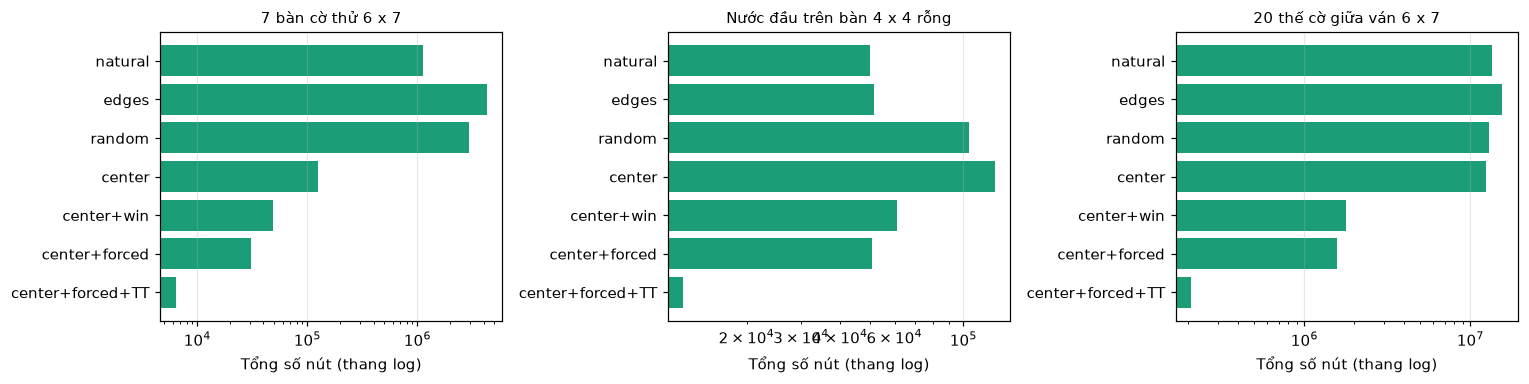

In [22]:
# Your code/ answer goes here.

ORDER_LIMIT = 3000000
ORDER_MID, ORDER_MID_LIMIT = 20, 1000000
ORDER_VARIANTS = [
    ("Trái → phải (natural)",                    dict(ordering = "natural")),
    ("Từ biên vào giữa (edges, tệ nhất)",         dict(ordering = "edges")),
    ("Ngẫu nhiên (3 lần; giữa ván 1 lần)",             dict(ordering = "random")),
    ("Từ giữa ra (center)",                       dict(ordering = "center")),
    ("center + kiểm tra nước thắng ngay",         dict(ordering = "center", win_first = True)),
    ("center + cắt nước chắc thua (forced)",      dict(ordering = "center", forced = True)),
    ("center + forced + bảng chuyển vị",          dict(ordering = "center", forced = True, use_tt = True)),
]

def run_variant(kw, board, player, seeds = (0,), limit = None):
    """Số nút TB, thời gian TB và số lần bị dừng (vượt giới hạn nút) khi giải thế cờ `board`; nút bị dừng được tính bằng giới hạn."""
    limit = limit or ORDER_LIMIT
    nodes, times, hit = [], [], 0
    for sd in seeds:
        ab = AlphaBetaPlayer(node_limit = limit, seed = sd, **kw)
        t0 = time.perf_counter()
        try:
            ab(board, player); nodes.append(max(ab.nodes, 1))
        except AlphaBetaPlayer.NodeLimit:
            hit += 1; nodes.append(limit)
        times.append(time.perf_counter() - t0)
    return np.mean(nodes), np.mean(times), hit

def mid_game_positions(n, plies, seed):
    """n thế cờ giữa ván: đi ngẫu nhiên plies[0]..plies[1] nước từ bàn rỗng; bỏ các thế cờ quá dễ (bộ giải tốt nhất cần < 200 nút)."""
    rng, easy = random.Random(seed), AlphaBetaPlayer(ordering = "center", forced = True, use_tt = True)
    out = []
    while len(out) < n:
        b, p = initial_state(), 1
        for _ in range(rng.randint(*plies)):
            if terminal(b): break
            b = result(b, p, rng.choice(actions(b))); p = -p
        if terminal(b): continue
        easy(b, p)
        if easy.nodes >= 200: out.append((b, p))
    return out
MID_POSITIONS = mid_game_positions(ORDER_MID, (22, 28), seed = 7)

rows_out, order_nodes = [], {}
for label, kw in ORDER_VARIANTS:
    seeds = (0, 1, 2) if kw["ordering"] == "random" else (0,)
    tot_n = tot_t = hits = 0
    for name, b in TEST_BOARDS.items():
        n_, t_, h_ = run_variant(kw, b, TEST_INFO[name]["player"], seeds)
        tot_n += n_; tot_t += t_; hits += h_ > 0
    n4, t4, h4 = run_variant(kw, initial_state((4, 4)), 1, seeds)
    mid_n = mid_t = mid_hits = 0
    for b, p in MID_POSITIONS:
        n_, t_, h_ = run_variant(kw, b, p, seeds[:1], ORDER_MID_LIMIT)          # thế cờ giữa ván: 1 lần chạy (random: seed 0)
        mid_n += n_; mid_t += t_; mid_hits += h_ > 0
    order_nodes[label] = dict(boards = (tot_n, tot_t, hits), empty44 = (n4, t4, h4), mid = (mid_n, mid_t, mid_hits))
    gt = lambda x, h: (f"> {x:,.0f}" if h else f"{x:,.0f}")
    rows_out.append({"Chiến lược duyệt nước đi": label,
                     "7 bàn thử: tổng số nút": gt(tot_n, hits), "7 bàn thử: thời gian (s)": round(tot_t, 2), "7 bàn: số bàn bị dừng": hits,
                     "Bàn 4x4 rỗng: số nút": f"{n4:,.0f}", "Bàn 4x4 rỗng: thời gian (s)": round(t4, 3),
                     f"{len(MID_POSITIONS)} thế cờ giữa ván: tổng số nút": gt(mid_n, mid_hits), f"{len(MID_POSITIONS)} thế giữa ván: thời gian (s)": round(mid_t, 2),
                     f"{len(MID_POSITIONS)} thế giữa ván: số thế bị dừng": mid_hits})
order_table = pd.DataFrame(rows_out)
display(order_table)
print(f"(Giới hạn {ORDER_LIMIT:,} nút mỗi lần chạy với 7 bàn thử và bàn 4x4, {ORDER_MID_LIMIT:,} nút với các thế cờ giữa ván; '>' nghĩa là số thật còn lớn hơn vì có lần chạy bị dừng. "
      f"Thế cờ giữa ván = đi ngẫu nhiên 22–28 nước từ bàn rỗng, bỏ thế quá dễ.)")

fig, ax = plt.subplots(1, 3, figsize = (14, 3.6), dpi = 110)
short = ["natural", "edges", "random", "center", "center+win", "center+forced", "center+forced+TT"]
for a_, key, title in ((ax[0], "boards", "7 bàn cờ thử 6 x 7"), (ax[1], "empty44", "Nước đầu trên bàn 4 x 4 rỗng"), (ax[2], "mid", f"{len(MID_POSITIONS)} thế cờ giữa ván 6 x 7")):
    a_.barh(short[::-1], [order_nodes[l][key][0] for l, _ in ORDER_VARIANTS][::-1], color = "#1b9e77"); a_.set_xscale("log")
    a_.set_xlabel("Tổng số nút (thang log)"); a_.set_title(title, fontsize = 10); a_.grid(axis = "x", alpha = .3)
plt.tight_layout(); plt.show()

In [23]:
O = {l: order_nodes[l] for l, _ in ORDER_VARIANTS}
L = [l for l, _ in ORDER_VARIANTS]
g67 = Geometry.get(6, 7)
cell_windows = [[sum(1 for w in g67.windows if w & (1 << (c * g67.H + k))) for c in range(7)] for k in range(6)]   # số cửa sổ đi qua mỗi ô
def change(a, b):
    """Mô tả số nút b so với a."""
    r = b / a
    return f"giảm {a / b:.1f} lần" if r < 0.9 else (f"tăng {r:.1f} lần" if r > 1.1 else "gần như không đổi")
mid = {k: O[l]["mid"] for k, l in zip(("nat", "edg", "rnd", "cen", "win", "frc", "tt"), L)}
brd = {k: O[l]["boards"] for k, l in zip(("nat", "edg", "rnd", "cen", "win", "frc", "tt"), L)}
e44 = {k: O[l]["empty44"] for k, l in zip(("nat", "edg", "rnd", "cen", "win", "frc", "tt"), L)}
n_center = sum(3 in TEST_INFO[n]["optimal"] for n in TEST_NAMES)
display(Markdown(f"""
**Chiến lược sắp xếp nước đi.** Alpha-Beta chỉ cắt được nhiều khi **nước tốt được xét trước**. Trong Connect 4 các ô ở **giữa bàn** tham gia nhiều "cửa sổ 4 ô" nhất (một ô ở giữa bàn nằm trong tới {max(max(r) for r in cell_windows)} cửa sổ, ô ở góc chỉ nằm trong {min(min(r) for r in cell_windows)}) nên các nước ở cột giữa thường tốt nhất; vì vậy ta duyệt cột theo thứ tự **3, 2, 4, 1, 5, 0, 6** (từ giữa ra hai bên) thay vì 0 … 6. Hai bước tiếp theo là sắp xếp "có hiểu biết": (i) xét **nước thắng ngay** trước, (ii) **cắt hẳn** các nước chắc chắn thua (đối thủ đang đe dọa thắng thì chỉ xét nước chặn, không đặt quân ngay dưới ô thắng của đối thủ) – hai bước này rẻ (vài phép toán bit) và giữ nguyên giá trị Minimax (đã kiểm chứng ở trên). Cuối cùng, **bảng chuyển vị** nhớ giá trị của các vị trí đã gặp.

**Kết quả đo được** (bảng và biểu đồ trên; ba bộ thế cờ để kết luận không phụ thuộc vào một loại thế cờ):

* **Chỉ đổi thứ tự cột** (4 dòng đầu). Trên {len(MID_POSITIONS)} thế cờ giữa ván, tổng số nút là {mid['nat'][0]:,.0f} (trái → phải), {mid['cen'][0]:,.0f} (từ giữa ra), {mid['edg'][0]:,.0f} (từ biên vào) và {mid['rnd'][0]:,.0f} (ngẫu nhiên): từ giữa ra {change(mid['nat'][0], mid['cen'][0])} so với trái → phải, còn từ biên vào {change(mid['nat'][0], mid['edg'][0])}. Không thể suy ra tỷ lệ chính xác giữa các cấu hình vì các lần chạy bị dừng ({mid['nat'][2]}, {mid['cen'][2]}, {mid['edg'][2]}, {mid['rnd'][2]} thế) chỉ được tính bằng đúng giới hạn nút.
* **Kiểm tra nước thắng ngay và cắt nước chắc thua** có tác dụng lớn hơn nhiều: từ {mid['cen'][0]:,.0f} nút xuống {mid['win'][0]:,.0f} (thắng ngay) rồi {mid['frc'][0]:,.0f} (thêm cắt nước thua) trên thế cờ giữa ván, vì hai bước này loại cả những nhánh mà đối thủ thắng ngay chứ không chỉ đổi thứ tự.
* **Bảng chuyển vị** giảm tiếp xuống {mid['tt'][0]:,.0f} nút: ít nhất **{mid['nat'][0] / mid['tt'][0]:.0f} lần** ít nút hơn thuật toán thuần ({mid['nat'][1]:.1f} s → {mid['tt'][1]:.2f} s) và không còn thế cờ nào bị dừng ({mid['tt'][2]} thế). Đây là cải tiến đáng giá nhất, vì rất nhiều dãy nước đi khác nhau dẫn tới cùng một vị trí.
* **Trung thực về thứ tự "từ giữa ra":** trên **7 bàn thử** nó {change(brd['nat'][0], brd['cen'][0])} ({brd['nat'][0]:,.0f} → {brd['cen'][0]:,.0f} nút) và trên **bàn 4 × 4 rỗng** {change(e44['nat'][0], e44['cen'][0])} ({e44['nat'][0]:,.0f} → {e44['cen'][0]:,.0f} nút). Với các bàn thử, nguyên nhân dễ thấy là nước đúng thường *không* ở cột giữa (chỉ {n_center}/{len(TEST_NAMES)} bàn có cột giữa là một nước tối ưu), còn với thế hòa như bàn 4 × 4 thì cả hai phía đều phải bị "chứng minh" nên thứ tự cột ít giúp được. Vì vậy thứ tự cột *đơn lẻ* chỉ là phỏng đoán hợp lý (heuristic), hiệu quả phụ thuộc thế cờ; còn việc xét nước thắng/chặn trước và bảng chuyển vị thì hiệu quả ổn định ở cả ba bộ thế cờ.
"""))


**Chiến lược sắp xếp nước đi.** Alpha-Beta chỉ cắt được nhiều khi **nước tốt được xét trước**. Trong Connect 4 các ô ở **giữa bàn** tham gia nhiều "cửa sổ 4 ô" nhất (một ô ở giữa bàn nằm trong tới 13 cửa sổ, ô ở góc chỉ nằm trong 3) nên các nước ở cột giữa thường tốt nhất; vì vậy ta duyệt cột theo thứ tự **3, 2, 4, 1, 5, 0, 6** (từ giữa ra hai bên) thay vì 0 … 6. Hai bước tiếp theo là sắp xếp "có hiểu biết": (i) xét **nước thắng ngay** trước, (ii) **cắt hẳn** các nước chắc chắn thua (đối thủ đang đe dọa thắng thì chỉ xét nước chặn, không đặt quân ngay dưới ô thắng của đối thủ) – hai bước này rẻ (vài phép toán bit) và giữ nguyên giá trị Minimax (đã kiểm chứng ở trên). Cuối cùng, **bảng chuyển vị** nhớ giá trị của các vị trí đã gặp.

**Kết quả đo được** (bảng và biểu đồ trên; ba bộ thế cờ để kết luận không phụ thuộc vào một loại thế cờ):

* **Chỉ đổi thứ tự cột** (4 dòng đầu). Trên 20 thế cờ giữa ván, tổng số nút là 13,511,782 (trái → phải), 12,508,415 (từ giữa ra), 15,616,976 (từ biên vào) và 12,885,143 (ngẫu nhiên): từ giữa ra gần như không đổi so với trái → phải, còn từ biên vào tăng 1.2 lần. Không thể suy ra tỷ lệ chính xác giữa các cấu hình vì các lần chạy bị dừng (13, 10, 14, 11 thế) chỉ được tính bằng đúng giới hạn nút.
* **Kiểm tra nước thắng ngay và cắt nước chắc thua** có tác dụng lớn hơn nhiều: từ 12,508,415 nút xuống 1,772,442 (thắng ngay) rồi 1,567,572 (thêm cắt nước thua) trên thế cờ giữa ván, vì hai bước này loại cả những nhánh mà đối thủ thắng ngay chứ không chỉ đổi thứ tự.
* **Bảng chuyển vị** giảm tiếp xuống 208,584 nút: ít nhất **65 lần** ít nút hơn thuật toán thuần (14.2 s → 0.66 s) và không còn thế cờ nào bị dừng (0 thế). Đây là cải tiến đáng giá nhất, vì rất nhiều dãy nước đi khác nhau dẫn tới cùng một vị trí.
* **Trung thực về thứ tự "từ giữa ra":** trên **7 bàn thử** nó giảm 9.0 lần (1,122,917 → 124,799 nút) và trên **bàn 4 × 4 rỗng** tăng 2.5 lần (50,047 → 126,210 nút). Với các bàn thử, nguyên nhân dễ thấy là nước đúng thường *không* ở cột giữa (chỉ 1/7 bàn có cột giữa là một nước tối ưu), còn với thế hòa như bàn 4 × 4 thì cả hai phía đều phải bị "chứng minh" nên thứ tự cột ít giúp được. Vì vậy thứ tự cột *đơn lẻ* chỉ là phỏng đoán hợp lý (heuristic), hiệu quả phụ thuộc thế cờ; còn việc xét nước thắng/chặn trước và bảng chuyển vị thì hiệu quả ổn định ở cả ba bộ thế cờ.


### The first few moves [5 points]

Start with an empty board. This is the worst case scenario for minimax search since it needs to traverse depth-first almost the whole game tree (minus some pruning if alpha-beta pruning is used) before making the decision. Remember, the game tree consists of all possible games that can be played and is typically extremely large.

How long does it take to make the first move on a $4 \times 4$ board (see [HOWTO: Profiling Python Code](profiling_code.ipynb))? Describe what your agent could do to improve this time.

In [24]:
# Your code/ answer goes here.

import cProfile, pstats, io

board44 = initial_state((4, 4))
# 1) bản numpy tham chiếu: thời gian chọn nước đầu tiên trên bàn 4 x 4 rỗng
ref = ReferenceAlphaBetaPlayer()
t0 = time.perf_counter(); a_ref = ref(board44, 1); t_ref = time.perf_counter() - t0
print(f"Bản numpy: nước đầu = cột {a_ref}, giá trị lý thuyết = {ref.last_value}, {ref.nodes:,} nút, {t_ref:.2f} s")

# 2) phân tích thời gian bằng cProfile (xem HOWTO: Profiling Python Code)
pr = cProfile.Profile(); pr.enable(); ReferenceAlphaBetaPlayer()(board44, 1); pr.disable()
stream = io.StringIO(); pst = pstats.Stats(pr, stream = stream); pst.sort_stats("time").print_stats(6)
print("\n".join(line[:140] for line in stream.getvalue().splitlines() if line.strip())[:2200])
cum = {k[2]: v[3] for k, v in pst.stats.items()}               # thời gian TÍCH LŨY (gồm cả các hàm được gọi bên trong) theo tên hàm
share = lambda name: 100 * cum.get(name, 0) / pst.total_tt
winner_share, actions_share, result_share = share("winner"), share("actions"), share("result")
print(f"Thời gian tích lũy: winner {winner_share:.0f} %, actions {actions_share:.0f} %, result {result_share:.0f} % tổng thời gian")

Bản numpy: nước đầu = cột 0, giá trị lý thuyết = 0, 43,827 nút, 1.55 s
         3776723 function calls (3732896 primitive calls) in 2.200 seconds
   Ordered by: internal time
   List reduced from 171 to 6 due to restriction <6>
   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
    62889    0.948    0.000    1.456    0.000 /var/folders/6t/wpn58dz569l1p5sqj3mds9400000gn/T/ipykernel_40883/2135354845.py:33(winner)
   458176    0.348    0.000    0.348    0.000 {method 'reduce' of 'numpy.ufunc' objects}
    95869    0.154    0.000    0.381    0.000 /var/folders/6t/wpn58dz569l1p5sqj3mds9400000gn/T/ipykernel_40883/2135354845.py:19(actions)
   158757    0.111    0.000    0.364    0.000 /opt/anaconda3/lib/python3.14/site-packages/numpy/_core/numeric.py:679(flatnonzero)
    62888    0.100    0.000    0.266    0.000 /var/folders/6t/wpn58dz569l1p5sqj3mds9400000gn/T/ipykernel_40883/2135354845.py:23(result)
   458176    0.093    0.000    0.508    0.000 {method 'any' of 'numpy.nd

In [25]:
# 3) các cách làm nhanh hơn: đo thời gian nước đầu tiên trên bàn 4 x 4 rỗng
IMPROVEMENTS = [
    ("Bản numpy tham chiếu (actions/result/utility)", None),
    ("Bitboard, thứ tự trái → phải",                   dict(ordering = "natural")),
    ("+ duyệt từ giữa ra",                              dict(ordering = "center")),
    ("+ kiểm tra nước thắng ngay",                      dict(ordering = "center", win_first = True)),
    ("+ cắt nước chắc thua (forced)",                   dict(ordering = "center", forced = True)),
    ("+ bảng chuyển vị",                                dict(ordering = "center", forced = True, use_tt = True)),
    ("+ đối xứng ở gốc (chỉ xét nửa số cột)",            dict(ordering = "center", forced = True, use_tt = True, symmetry_root = True)),
]
rows_out, first_nodes, first_times = [], [], []
for label, kw in IMPROVEMENTS:
    if kw is None:
        first_nodes.append(ref.nodes); first_times.append(t_ref)
        rows_out.append({"Phiên bản": label, "Số nút": f"{ref.nodes:,}", "Thời gian (s)": round(t_ref, 3), "Nhanh hơn bản numpy": "1,0 ×"}); continue
    ab = AlphaBetaPlayer(**kw)
    t0 = time.perf_counter(); a = ab(board44, 1); dt = time.perf_counter() - t0
    first_nodes.append(ab.nodes); first_times.append(dt)
    rows_out.append({"Phiên bản": label, "Số nút": f"{ab.nodes:,}", "Thời gian (s)": round(dt, 4), "Nhanh hơn bản numpy": f"{t_ref / dt:,.0f} ×".replace(".", ",")})
first_table = pd.DataFrame(rows_out)
display(first_table)
print("Giá trị lý thuyết của bàn 4 x 4 rỗng đối với người đi trước:", AlphaBetaPlayer(ordering = "center", forced = True, use_tt = True).value(board44, 1), "(0 = hòa)")

,Phiên bản,Số nút,Thời gian (s),Nhanh hơn bản numpy
0,Bản numpy tham chiếu (actions/result/utility),"43,827",1.5470,"1,0 ×"
1,"Bitboard, thứ tự trái → phải","50,047",0.0345,45 ×
2,+ duyệt từ giữa ra,"126,210",0.1144,14 ×
3,+ kiểm tra nước thắng ngay,"61,226",0.0566,27 ×
4,+ cắt nước chắc thua (forced),"50,741",0.1050,15 ×
5,+ bảng chuyển vị,"12,511",0.0258,60 ×
6,+ đối xứng ở gốc (chỉ xét nửa số cột),"11,741",0.0252,62 ×


Giá trị lý thuyết của bàn 4 x 4 rỗng đối với người đi trước: 0 (0 = hòa)


In [26]:
full44 = exact[(4, 4)][1]
per_node_np, per_node_bb = 1e6 * t_ref / ref.nodes, 1e6 * first_times[1] / first_nodes[1]
fn, ft = first_nodes, first_times
order_txt = "làm **tăng** số nút" if fn[2] > fn[1] else "làm giảm số nút"
display(Markdown(f"""
**Thời gian chọn nước đầu tiên trên bàn 4 × 4:** bản numpy tham chiếu cần **{t_ref:.1f} s** ({ref.nodes:,} nút); nước đi chọn là cột {a_ref} với giá trị lý thuyết {ref.last_value:+d} (hòa). Bàn rỗng là trường hợp **khó nhất** của một ván: chưa có quân nào để tạo ra cắt nhánh sớm, và vì ván 4 × 4 là hòa nên Alpha-Beta phải chứng minh được rằng *cả hai phía* đều không thắng được. Dù vậy cắt tỉa vẫn loại bỏ gần như toàn bộ cây: chỉ duyệt {ref.nodes:,} trong {full44:,} nút của cây đầy đủ ({100 * ref.nodes / full44:.2f} %).

**Phân tích cProfile (kết quả ở trên):** hàm `winner` (kiểm tra 4 quân liên tiếp, được gọi qua `utility` ở **mỗi nút con**) chiếm {winner_share:.0f} % tổng thời gian tích lũy (kể cả các phép `any`, `reduce` của numpy bên trong nó), `actions` chiếm {actions_share:.0f} % và `result` {result_share:.0f} %. Vậy có hai chỗ để tối ưu: **chi phí mỗi nút** (phát hiện thắng, sao chép bàn cờ) và **số nút**.

**Tác tử có thể làm gì để nhanh hơn** (bảng trên đo từng cải tiến, cộng dồn):
1. **Bitboard** giảm chi phí mỗi nút từ {per_node_np:.0f} µs xuống {per_node_bb:.1f} µs (≈ {per_node_np / per_node_bb:.0f} lần): phép quét mảng numpy được thay bằng vài phép dịch bit trên số nguyên. Đây là cải tiến lớn nhất ({ft[0]:.2f} s → {ft[1]:.3f} s).
2. **Sắp xếp nước đi theo thứ tự từ giữa ra** {order_txt} trên bàn rỗng này ({fn[1]:,} → {fn[2]:,} nút; xem "Lưu ý trung thực" ở mục Move ordering: với thế cờ hòa kết quả phụ thuộc vị trí), kiểm tra **nước thắng ngay** còn {fn[3]:,} nút và **cắt các nước chắc thua** (chặn bắt buộc, không đặt dưới ô thắng của đối thủ) còn {fn[4]:,} nút – nhưng mỗi nút tốn thêm vài phép bit nên thời gian chưa chắc giảm ({ft[2]:.3f} s → {ft[4]:.3f} s).
3. **Bảng chuyển vị** là cải tiến thuật toán hiệu quả nhất: nhiều dãy nước đi dẫn tới cùng một vị trí, lưu giá trị đã tính để không tính lại giúp giảm xuống {fn[5]:,} nút ({ft[5]:.3f} s).
4. **Đối xứng trái–phải:** bàn rỗng đối xứng nên chỉ cần xét một nửa số cột ở gốc ({fn[6]:,} nút, {ft[6]:.3f} s).
5. Ngoài ra: **sách khai cuộc** (tra sẵn nước đầu tiên: với bàn 6 × 7 là cột giữa), **tìm kiếm sâu dần (iterative deepening)** để luôn có nước đi trả lời trong thời gian cho phép, và cắt độ sâu cùng heuristic (Task 4).
"""))


**Thời gian chọn nước đầu tiên trên bàn 4 × 4:** bản numpy tham chiếu cần **1.5 s** (43,827 nút); nước đi chọn là cột 0 với giá trị lý thuyết +0 (hòa). Bàn rỗng là trường hợp **khó nhất** của một ván: chưa có quân nào để tạo ra cắt nhánh sớm, và vì ván 4 × 4 là hòa nên Alpha-Beta phải chứng minh được rằng *cả hai phía* đều không thắng được. Dù vậy cắt tỉa vẫn loại bỏ gần như toàn bộ cây: chỉ duyệt 43,827 trong 131,060,741 nút của cây đầy đủ (0.03 %).

**Phân tích cProfile (kết quả ở trên):** hàm `winner` (kiểm tra 4 quân liên tiếp, được gọi qua `utility` ở **mỗi nút con**) chiếm 66 % tổng thời gian tích lũy (kể cả các phép `any`, `reduce` của numpy bên trong nó), `actions` chiếm 17 % và `result` 12 %. Vậy có hai chỗ để tối ưu: **chi phí mỗi nút** (phát hiện thắng, sao chép bàn cờ) và **số nút**.

**Tác tử có thể làm gì để nhanh hơn** (bảng trên đo từng cải tiến, cộng dồn):
1. **Bitboard** giảm chi phí mỗi nút từ 35 µs xuống 0.7 µs (≈ 51 lần): phép quét mảng numpy được thay bằng vài phép dịch bit trên số nguyên. Đây là cải tiến lớn nhất (1.55 s → 0.035 s).
2. **Sắp xếp nước đi theo thứ tự từ giữa ra** làm **tăng** số nút trên bàn rỗng này (50,047 → 126,210 nút; xem "Lưu ý trung thực" ở mục Move ordering: với thế cờ hòa kết quả phụ thuộc vị trí), kiểm tra **nước thắng ngay** còn 61,226 nút và **cắt các nước chắc thua** (chặn bắt buộc, không đặt dưới ô thắng của đối thủ) còn 50,741 nút – nhưng mỗi nút tốn thêm vài phép bit nên thời gian chưa chắc giảm (0.114 s → 0.105 s).
3. **Bảng chuyển vị** là cải tiến thuật toán hiệu quả nhất: nhiều dãy nước đi dẫn tới cùng một vị trí, lưu giá trị đã tính để không tính lại giúp giảm xuống 12,511 nút (0.026 s).
4. **Đối xứng trái–phải:** bàn rỗng đối xứng nên chỉ cần xét một nửa số cột ở gốc (11,741 nút, 0.025 s).
5. Ngoài ra: **sách khai cuộc** (tra sẵn nước đầu tiên: với bàn 6 × 7 là cột giữa), **tìm kiếm sâu dần (iterative deepening)** để luôn có nước đi trả lời trong thời gian cho phép, và cắt độ sâu cùng heuristic (Task 4).


### Playtime [5 points]

Let the Minimax Search agent play a random agent on a $4 \times 4$ board. Analyze wins, losses and draws.

,Vai của Alpha-Beta,Số ván,Thắng,Hòa,Thua,Thời gian suy nghĩ TB mỗi ván (s),Số nước TB
0,đi trước (X),100,54,46,0,0.035,13.5
1,đi sau (O),100,90,10,0,0.019,13.0


[6 s]


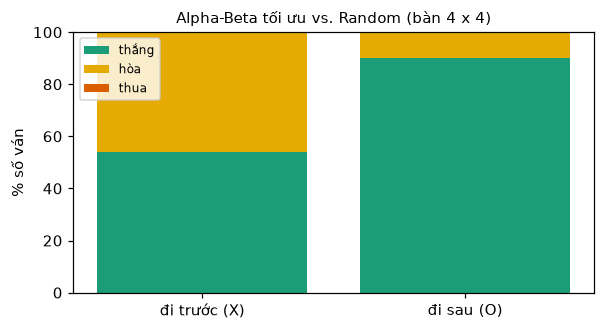

In [27]:
# Your code/ answer goes here.

# ---- Alpha-Beta (tối ưu) đấu với Random trên bàn 4 x 4: 100 ván mỗi vai ----
class FreshTT:
    """Bọc một tác tử Alpha-Beta để xóa bảng chuyển vị ở đầu mỗi ván mới (bảng chỉ có ích trong cùng một ván)."""
    def __init__(self, player): self.player, self.name = player, player.name
    def __call__(self, board, player = 1):
        if not (board != 0).any() or (board != 0).sum() <= 1: self.player.tt.clear()
        return self.player(board, player)

N_PLAY = 100
np.random.seed(11)
agent = FreshTT(AlphaBetaPlayer(ordering = "center", forced = True, use_tt = True, name = "Alpha-Beta tối ưu"))
t0 = time.time()
stats = {}
for role, (red, yellow) in {"đi trước (X)": (agent, random_player), "đi sau (O)": (random_player, agent)}.items():
    me = 1 if role.startswith("đi trước") else -1
    res = Counter({"thắng": 0, "hòa": 0, "thua": 0})
    think, plies = 0.0, 0
    for _ in range(N_PLAY):
        g_ = play_game(red, yellow, initial_state((4, 4)))
        w = g_["winner"]
        res["thắng" if w == me else "thua" if w == -me else "hòa"] += 1
        think += g_["time"][me]; plies += g_["moves"]
    stats[role] = (res, think / N_PLAY, plies / N_PLAY)
rows_out = [{"Vai của Alpha-Beta": r, "Số ván": N_PLAY, "Thắng": s[0]["thắng"], "Hòa": s[0]["hòa"], "Thua": s[0]["thua"],
             "Thời gian suy nghĩ TB mỗi ván (s)": round(s[1], 3), "Số nước TB": round(s[2], 1)} for r, s in stats.items()]
play_table = pd.DataFrame(rows_out)
display(play_table)
print(f"[{time.time() - t0:.0f} s]")

fig, ax = plt.subplots(figsize = (5.6, 3.1), dpi = 110)
bottom = np.zeros(2)
for key, color in (("thắng", "#1b9e77"), ("hòa", "#e6ab02"), ("thua", "#d95f02")):
    vals = np.array([stats[r][0][key] for r in stats]) * 100 / N_PLAY
    ax.bar(list(stats), vals, bottom = bottom, label = key, color = color); bottom += vals
ax.set_ylabel("% số ván"); ax.set_title("Alpha-Beta tối ưu vs. Random (bàn 4 x 4)", fontsize = 10); ax.legend(fontsize = 8)
plt.tight_layout(); plt.show()

In [28]:
f, s = stats["đi trước (X)"][0], stats["đi sau (O)"][0]
losses = f["thua"] + s["thua"]
w_first, w_second = 100 * f["thắng"] / N_PLAY, 100 * s["thắng"] / N_PLAY
display(Markdown(f"""
**Phân tích:** trong {N_PLAY} ván mỗi vai, Alpha-Beta tối ưu **thua {losses} / {2 * N_PLAY} ván** (đi trước: thắng {f['thắng']}, hòa {f['hòa']}, thua {f['thua']}; đi sau: thắng {s['thắng']}, hòa {s['hòa']}, thua {s['thua']}).

* {'**Không bao giờ thua**' if losses == 0 else '**Có ván thua** (bất thường – cần kiểm tra lại cài đặt)'} vì bàn 4 × 4 là **hòa** khi cả hai chơi tối ưu (đã tính ở trên): tác tử luôn chọn nước giữ được giá trị ≥ 0, nên chỉ có thể thắng hoặc hòa trước đối thủ ngẫu nhiên.
* **Tỷ lệ thắng phụ thuộc vai:** {w_first:.0f} % khi đi trước và {w_second:.0f} % khi đi sau (thắng nhiều hơn khi **đi {'sau' if w_second > w_first else 'trước'}**). Giá trị lý thuyết là hòa ở cả hai vai nên chênh lệch này không do "lợi thế đi trước" của trò chơi mà do cách Minimax chọn giữa các nước **cùng giá trị 0**: ở thế đầu mọi nước đều giữ hòa nên tác tử lấy nước đầu tiên theo thứ tự duyệt và không cố tạo bẫy. Đây là một giả thuyết hợp lý, ta không kiểm chứng riêng.
* **Các ván hòa** xảy ra khi Random may mắn chơi đúng hoặc khi tác tử chọn nước "an toàn" (cùng giá trị 0) mà không đặt bẫy: Minimax chỉ biết giá trị +1/0/−1 nên **không phân biệt** hai nước cùng giá trị – không có khái niệm "nước dễ làm đối thủ sai". Đây là lý do tìm kiếm tối ưu chưa chắc tối đa hóa số ván thắng trước một đối thủ yếu.
* Thời gian suy nghĩ trung bình mỗi ván chỉ cỡ {1000 * min(stats[r][1] for r in stats):.0f}–{1000 * max(stats[r][1] for r in stats):.0f} ms vì bàn 4 × 4 nhỏ và có bảng chuyển vị; đối với bàn chuẩn 6 × 7 điều này không còn đúng (xem các thí nghiệm kích thước bàn ở trên).
"""))


**Phân tích:** trong 100 ván mỗi vai, Alpha-Beta tối ưu **thua 0 / 200 ván** (đi trước: thắng 54, hòa 46, thua 0; đi sau: thắng 90, hòa 10, thua 0).

* **Không bao giờ thua** vì bàn 4 × 4 là **hòa** khi cả hai chơi tối ưu (đã tính ở trên): tác tử luôn chọn nước giữ được giá trị ≥ 0, nên chỉ có thể thắng hoặc hòa trước đối thủ ngẫu nhiên.
* **Tỷ lệ thắng phụ thuộc vai:** 54 % khi đi trước và 90 % khi đi sau (thắng nhiều hơn khi **đi sau**). Giá trị lý thuyết là hòa ở cả hai vai nên chênh lệch này không do "lợi thế đi trước" của trò chơi mà do cách Minimax chọn giữa các nước **cùng giá trị 0**: ở thế đầu mọi nước đều giữ hòa nên tác tử lấy nước đầu tiên theo thứ tự duyệt và không cố tạo bẫy. Đây là một giả thuyết hợp lý, ta không kiểm chứng riêng.
* **Các ván hòa** xảy ra khi Random may mắn chơi đúng hoặc khi tác tử chọn nước "an toàn" (cùng giá trị 0) mà không đặt bẫy: Minimax chỉ biết giá trị +1/0/−1 nên **không phân biệt** hai nước cùng giá trị – không có khái niệm "nước dễ làm đối thủ sai". Đây là lý do tìm kiếm tối ưu chưa chắc tối đa hóa số ván thắng trước một đối thủ yếu.
* Thời gian suy nghĩ trung bình mỗi ván chỉ cỡ 19–35 ms vì bàn 4 × 4 nhỏ và có bảng chuyển vị; đối với bàn chuẩn 6 × 7 điều này không còn đúng (xem các thí nghiệm kích thước bàn ở trên).


### Task 3 bổ sung: quy ước số nút và kiểm thử hồi quy

* Bảng chuyển vị dùng khóa `(số hàng, số cột, cur + mask)` để một tác tử có thể chuyển giữa các kích thước bàn mà không tái sử dụng sai kết quả.
* Bàn đã kết thúc: tác tử trả về `None`; `value()` trả lợi ích đúng và `action_values()` trả `{}`. Môi trường `play_game()` kiểm tra kết thúc trước khi gọi tác tử.
* `action_values()` xét **mọi cột hợp lệ**, kể cả khi bật `symmetry_root`; đối xứng chỉ giảm số cột cần xét khi chọn một nước đi.
* Bộ đếm của bản bitboard chỉ đếm các lần vào `negamax`, không tính gốc và các nước thắng được nhận ra ngay ngoài lời gọi đệ quy. Bản numpy đếm lần vào `max_value`/`min_value`. Vì quy ước khác nhau, không xem tỷ lệ số nút giữa hai cách biểu diễn là tỷ lệ cắt tỉa thuần túy; dùng thời gian đo để đánh giá tốc độ thực tế.
* Thời gian là phép đo trên máy chạy; các lần dừng vì `node_limit` chỉ cho số nút đã xét, không cho lời giải hay thời gian hoàn tất. Mốc căn bậc hai kích thước cây chỉ minh họa mô hình cây đều với thứ tự lý tưởng, không phải cận dưới cho cây Connect 4 không đều.

Kiểm thử dưới đây kiểm tra các lỗi trên, tính tối ưu trên các thế cờ nhỏ và việc không sửa bàn đầu vào.

In [29]:
def check_task3_regressions():
    # Giữ cùng một tác tử qua nhiều kích thước: trước đây bảng 4x6 có thể bị trả sai là hòa.
    shared = AlphaBetaPlayer(ordering="center", forced=True, use_tt=True)
    dimension_rows = []
    for shape in ((4, 4), (4, 5), (5, 4), (4, 6)):
        board = initial_state(shape)
        before = board.copy()
        actual = shared.value(board, 1)
        expected = AlphaBetaPlayer(ordering="center", forced=True, use_tt=True).value(board, 1)
        assert actual == expected, (shape, actual, expected)
        assert np.array_equal(board, before)
        dimension_rows.append((shape, actual))
    assert dimension_rows[-1][1] == -1

    # Đối xứng không được làm mất cột trong kết quả phân tích từng nước.
    board = initial_state((4, 4))
    expected = minimax_values(board, 1, {})
    symmetric = AlphaBetaPlayer(forced=True, use_tt=True, symmetry_root=True)
    assert symmetric.action_values(board, 1) == expected
    action = symmetric(board, 1)
    assert expected[action] == max(expected.values()) == symmetric.last_value

    # Cùng bàn thắng và bàn hòa, hỏi lợi ích từ cả hai phía.
    won = board_from_moves([0, 1, 0, 1, 0, 1, 0], shape=(4, 4))
    drawn = board_from_strings(["XXOO", "OOXX", "XXOO", "OOXX"])
    assert winner(won) == 1 and terminal(drawn) and winner(drawn) == 0
    for board in (won, drawn):
        for player in (1, -1):
            before = board.copy()
            ref = ReferenceAlphaBetaPlayer()
            agent = AlphaBetaPlayer(forced=True, use_tt=True, symmetry_root=True)
            assert ref(board, player) is None
            assert ref.last_value == utility(board, player)
            assert agent(board, player) is None
            assert agent.last_value == utility(board, player)
            assert agent.value(board, player) == utility(board, player)
            assert agent.action_values(board, player) == {}
            assert agent.nodes == 0
            assert np.array_equal(board, before)

    # Giới hạn số nút phải báo dừng; không được trả một nước chưa chứng minh tối ưu.
    limited = AlphaBetaPlayer(ordering="natural", node_limit=1)
    try:
        limited(initial_state((4, 4)), 1)
    except AlphaBetaPlayer.NodeLimit:
        assert limited.nodes == 2
    else:
        raise AssertionError("Phải báo NodeLimit khi vượt ngân sách nút")
    return dimension_rows

regression_values = check_task3_regressions()
print("ĐẠT: bảng nhớ qua nhiều kích thước, phân tích đủ cột khi đối xứng, "
      "bàn kết thúc, bảo toàn đầu vào và giới hạn nút.")
print("Giá trị theo kích thước:", regression_values)

ĐẠT: bảng nhớ qua nhiều kích thước, phân tích đủ cột khi đối xứng, bàn kết thúc, bảo toàn đầu vào và giới hạn nút.
Giá trị theo kích thước: [((4, 4), 0), ((4, 5), 0), ((5, 4), 0), ((4, 6), -1)]


## Task 4: Heuristic Alpha-Beta Tree Search

### Heuristic evaluation function [10 points]

Define and implement a heuristic evaluation function. Make sure that the heuristic value stays in the correct range.

1,715 bàn cờ ngẫu nhiên: giá trị heuristic nhỏ nhất = -0.868, lớn nhất = +0.901, trung bình = +0.038
Đối xứng h(b, người 1) = -h(b, người -1): True;  bất biến khi lật trái-phải: True;  bàn rỗng = +0.0
Cận trên lý thuyết: |điểm thô| ≤ 570 ⇒ |h| ≤ tanh(570/40) = 0.999999999999 < 1


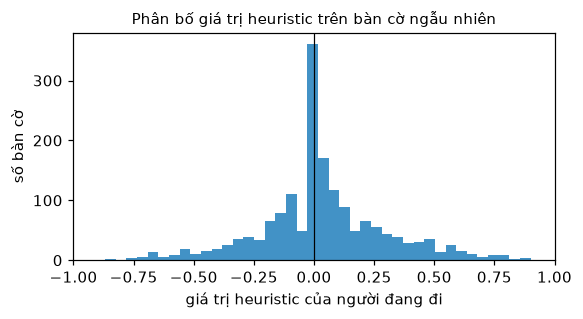

In [30]:
# Your code/ answer goes here.

# =====================================================================================================
# Hàm đánh giá heuristic cho Connect 4
#   Mỗi nước đi chỉ có ý nghĩa nếu giúp tạo (hoặc chặn) các "cửa sổ" 4 ô thẳng hàng. Hàm đếm:
#     * cửa sổ 4 ô KHÔNG có quân đối thủ mà chứa đúng 2 quân của mình (cơ hội) hoặc đúng 3 quân (đe dọa thắng),
#     * số quân ở cột giữa (cột giữa nằm trong nhiều cửa sổ nhất),
#   rồi lấy hiệu (của mình - của đối thủ), nén vào khoảng mở (-1, 1) bằng tanh.
# =====================================================================================================
HEUR_CENTER, HEUR_W2, HEUR_W3, HEUR_SCALE = 3.0, 2.0, 8.0, 40.0

def heuristic_value(g, cur, mask):
    """Giá trị heuristic của một vị trí chưa kết thúc đối với người đang đi (sở hữu `cur`): luôn nằm trong (-1, 1)."""
    opp = cur ^ mask
    score = HEUR_CENTER * (popcount(cur & g.center_mask) - popcount(opp & g.center_mask))
    for w in g.windows:                                   # duyệt 69 cửa sổ (bàn 6 x 7)
        mine, theirs = popcount(cur & w), popcount(opp & w)
        if theirs == 0:
            if mine == 2: score += HEUR_W2
            elif mine == 3: score += HEUR_W3
        elif mine == 0:
            if theirs == 2: score -= HEUR_W2
            elif theirs == 3: score -= HEUR_W3
    return math.tanh(score / HEUR_SCALE)

def heuristic(board, player = 1):
    """Giao diện numpy: giá trị đối với `player`. Trạng thái kết thúc trả về lợi ích thật (+1 / 0 / -1)."""
    u = utility(board, player)
    if u is not None: return float(u)
    g = Geometry.get(*board.shape)
    cur, mask = g.to_bits(board, player)
    return heuristic_value(g, cur, mask)

# ---- Kiểm tra: (1) luôn nằm trong (-1, 1); (2) đối xứng: giá trị đối với người này = - giá trị đối với người kia; (3) bàn rỗng = 0 ----
rng = random.Random(5)
vals, antisym_ok, mirror_ok = [], True, True
for _ in range(3000):
    b, p = initial_state(), 1
    for _ in range(rng.randint(0, 36)):
        if terminal(b): break
        b = result(b, p, rng.choice(actions(b))); p = -p
    if terminal(b): continue
    h1, h2 = heuristic(b, 1), heuristic(b, -1)
    antisym_ok &= abs(h1 + h2) < 1e-12
    mirror_ok &= abs(heuristic(b[:, ::-1], 1) - h1) < 1e-12           # đối xứng trái-phải không đổi giá trị
    vals.append(h1)
vals = np.array(vals)
max_abs_score = 3 * 6 + 69 * 8                                          # cận trên lý thuyết của |điểm thô|
print(f"{len(vals):,} bàn cờ ngẫu nhiên: giá trị heuristic nhỏ nhất = {vals.min():+.3f}, lớn nhất = {vals.max():+.3f}, trung bình = {vals.mean():+.3f}")
print(f"Đối xứng h(b, người 1) = -h(b, người -1): {antisym_ok};  bất biến khi lật trái-phải: {mirror_ok};  bàn rỗng = {heuristic(initial_state()):+.1f}")
print(f"Cận trên lý thuyết: |điểm thô| ≤ {max_abs_score} ⇒ |h| ≤ tanh({max_abs_score}/{HEUR_SCALE:g}) = {math.tanh(max_abs_score / HEUR_SCALE):.12f} < 1")

fig, ax = plt.subplots(figsize = (5.4, 3.0), dpi = 110)
ax.hist(vals, bins = 40, color = "#4292c6"); ax.axvline(0, color = "k", lw = .8)
ax.set_xlim(-1, 1); ax.set_xlabel("giá trị heuristic của người đang đi"); ax.set_ylabel("số bàn cờ"); ax.set_title("Phân bố giá trị heuristic trên bàn cờ ngẫu nhiên", fontsize = 10)
plt.tight_layout(); plt.show()

**Thiết kế hàm heuristic.** Trong Connect 4 mọi chiến thắng đều là một "cửa sổ" 4 ô thẳng hàng (69 cửa sổ trên bàn 6 × 7), nên hàm đánh giá đếm, cho từng người chơi, các cửa sổ **chưa bị đối phương chặn**:

* cửa sổ chứa đúng **2 quân** của mình và không có quân đối thủ: cơ hội (+2 điểm);
* cửa sổ chứa đúng **3 quân** của mình và không có quân đối thủ: sắp thắng (+8 điểm);
* mỗi quân ở **cột giữa** (nằm trong nhiều cửa sổ nhất) được +3 điểm;
* điểm thô = (tổng điểm của mình) − (tổng điểm của đối thủ), rồi nén vào khoảng mở (−1, 1) bằng `tanh(điểm / 40)`.

**Vì sao giá trị luôn đúng khoảng?** (i) `tanh` luôn nằm trong (−1, 1) nên mọi đánh giá heuristic *nhỏ hơn* lợi ích thật của trạng thái thắng (+1) và *lớn hơn* lợi ích thua (−1): một nước thắng chắc chắn luôn được ưu tiên hơn mọi nước chỉ "có vẻ tốt"; (ii) hàm là **phản đối xứng** (giá trị đối với người này = −giá trị đối với người kia) nên dùng được trong negamax; (iii) bàn cờ rỗng có giá trị 0. Ô code bên dưới kiểm tra cả ba tính chất trên các bàn cờ ngẫu nhiên.

### Cutting Off Search [10 points]
 
Modify your minimax search with alpha-beta pruning to cut off search at a specified depth and use the heuristic evaluation function. Experiment with different cutoff values. 

In [31]:
# Your code/ answer goes here.

class HeuristicAlphaBetaPlayer:
    """Alpha-Beta (negamax) CẮT ở độ sâu `cutoff` và dùng hàm heuristic ở các nút lá.

    Giá trị: thắng = +1, hòa = 0, thua = -1 (lợi ích thật), còn nút bị cắt dùng heuristic trong (-1, 1)
    nên một nước thắng chắc chắn luôn được ưu tiên hơn mọi đánh giá heuristic.
      cutoff   : số nửa-nước (ply) tìm kiếm tính từ gốc
      evaluate : hàm (geometry, cur, mask) -> giá trị trong (-1, 1); mặc định là `heuristic_value`
      ordering : "center" (từ giữa ra) hoặc "natural" (trái -> phải)
      use_tt   : bảng chuyển vị có kèm độ sâu còn lại (chỉ dùng trong một lần tìm kiếm; xóa trước mỗi nước đi)
      forced   : (tùy chọn) cắt nước chắc thua / thắng ngay như ở Task 3 – ngầm kéo dài tìm kiếm ở các thế cờ chiến thuật
    """
    def __init__(self, cutoff = 4, evaluate = None, ordering = "center", use_tt = True, forced = False, name = None):
        self.cutoff, self.evaluate, self.ordering, self.use_tt, self.forced = cutoff, evaluate or heuristic_value, ordering, use_tt, forced
        self.tt, self.nodes, self.last_value = {}, 0, None
        self.name = name or f"Heuristic Alpha-Beta (cutoff = {cutoff})"

    def __call__(self, board, player = 1):
        g = Geometry.get(*board.shape)
        cur, mask = g.to_bits(board, player)
        self.tt.clear()
        column, self.last_value = self.search(g, cur, mask)
        return column

    def search(self, g, cur, mask):
        cells = g.cells
        bottom, colm, top = g.bottom, g.col_mask, g.top
        board_mask, bottom_all = g.board_mask, g.bottom_all
        is_win, winning_cells, evaluate = g.is_win, g.winning_cells, self.evaluate
        forced, tt = self.forced, (self.tt if self.use_tt else None)
        static = g.center_order if self.ordering == "center" else list(range(g.cols))
        nodes = 0

        def negamax(cur, mask, nm, depth, alpha, beta):
            nonlocal nodes
            nodes += 1
            if nm == cells: return 0.0                              # bàn cờ đầy: hòa
            if depth == 0: return evaluate(g, cur, mask)            # CẮT: dùng heuristic
            if tt is not None:
                key = cur + mask
                entry = tt.get(key)
                if entry is not None and entry[0] >= depth:         # chỉ dùng nếu đã tìm sâu ít nhất bằng độ sâu còn lại
                    _, flag, val = entry
                    if flag == 0: return val
                    if flag == 1:
                        if val >= beta: return val
                        if val > alpha: alpha = val
                    else:
                        if val <= alpha: return val
                        if val < beta: beta = val
                    if alpha >= beta: return val
                alpha0 = alpha
            opp = cur ^ mask
            order = static
            if forced:
                possible = (mask + bottom_all) & board_mask
                if winning_cells(cur, mask) & possible: return 1.0
                danger = winning_cells(opp, mask)
                must = danger & possible
                if must:
                    if must & (must - 1): return -1.0
                    possible = must
                else:
                    possible &= ~(danger >> 1)
                    if not possible: return -1.0
                order = [c for c in static if possible & colm[c]]
            best = -2.0
            for c in order:
                if mask & top[c]: continue
                nb = (mask + bottom[c]) & colm[c]
                if not forced and is_win(cur | nb):
                    v = 1.0
                else:
                    v = -negamax(opp, mask | nb, nm + 1, depth - 1, -beta, -alpha)
                if v > best:
                    best = v
                    if v > alpha:
                        alpha = v
                        if alpha >= beta: break
            if tt is not None:
                tt[key] = (depth, 2 if best <= alpha0 else (1 if best >= beta else 0), best)
            return best

        nm0, best, best_col = popcount(mask), -2.0, None
        alpha, beta, opp = -1.0, 1.0, cur ^ mask
        for c in static:
            if mask & top[c]: continue
            nb = (mask + bottom[c]) & colm[c]
            v = 1.0 if is_win(cur | nb) else -negamax(opp, mask | nb, nm0 + 1, self.cutoff - 1, -beta, -alpha)
            if v > best:
                best, best_col = v, c
                if v > alpha:
                    alpha = v
                    if alpha >= beta: break
        self.nodes = nodes
        return best_col, best

# ---- Thử các giá trị cutoff khác nhau: bàn rỗng và một thế cờ sau 6 nước (bàn chuẩn 6 x 7) ----
def cutoff_experiment(board, cutoffs, **kw):
    player = player_to_move(board)
    rows_out, raw = [], {"nodes": [], "ms": [], "value": [], "move": []}
    for d in cutoffs:
        agent = HeuristicAlphaBetaPlayer(cutoff = d, **kw)
        t0 = time.perf_counter(); a = agent(board, player); dt = time.perf_counter() - t0
        raw["nodes"].append(agent.nodes); raw["ms"].append(1000 * dt); raw["value"].append(agent.last_value); raw["move"].append(a)
        rows_out.append({"cutoff": d, "Cột chọn": a, "Giá trị đánh giá": round(agent.last_value, 3), "Số nút": f"{agent.nodes:,}", "Thời gian (ms)": round(1000 * dt, 1)})
    df = pd.DataFrame(rows_out)
    df.attrs.update(raw)
    return df

CUTOFFS = [1, 2, 3, 4, 5, 6, 7, 8]
print("Bàn rỗng (đến lượt người 1):");  cut_empty = cutoff_experiment(initial_state(), CUTOFFS); display(cut_empty)
opening6 = board_from_moves([3, 3, 2, 4, 4, 2])
print("Sau 6 nước [3, 3, 2, 4, 4, 2] (đến lượt người 1):"); cut_open6 = cutoff_experiment(opening6, CUTOFFS); display(cut_open6)

Bàn rỗng (đến lượt người 1):


,cutoff,Cột chọn,Giá trị đánh giá,Số nút,Thời gian (ms)
0,1,3,0.075,7,0.1
1,2,3,0.000,20,0.1
2,3,3,0.149,75,0.5
3,4,3,0.000,159,0.5
4,5,3,0.149,507,2.2
5,6,3,0.000,922,3.1
6,7,3,0.197,"2,677",11.2
7,8,3,-0.050,"4,767",15.9


Sau 6 nước [3, 3, 2, 4, 4, 2] (đến lượt người 1):


,cutoff,Cột chọn,Giá trị đánh giá,Số nút,Thời gian (ms)
0,1,3,0.173,7,0.1
1,2,3,-0.075,21,0.1
2,3,3,0.268,127,0.6
3,4,3,0.000,281,2.1
4,5,3,0.380,"1,590",10.2
5,6,3,0.050,"3,034",13.4
6,7,3,0.380,"15,230",78.3
7,8,3,0.050,"26,762",88.4


In [32]:
def growth(df): n = df.attrs["nodes"]; return (n[-1] / n[0]) ** (1 / (len(n) - 1))
odd = lambda df: float(np.mean([v for d, v in zip(CUTOFFS, df.attrs["value"]) if d % 2 == 1]))
even = lambda df: float(np.mean([v for d, v in zip(CUTOFFS, df.attrs["value"]) if d % 2 == 0]))
moves_e, moves_o = sorted(set(cut_empty.attrs["move"])), sorted(set(cut_open6.attrs["move"]))
display(Markdown(f"""
**Nhận xét.**
* **Số nút và thời gian tăng theo hàm mũ với cutoff:** mỗi mức sâu thêm nhân số nút lên ≈ ×{growth(cut_empty):.1f} (bàn rỗng) và ≈ ×{growth(cut_open6):.1f} (sau 6 nước); thời gian đi từ {cut_open6.attrs['ms'][0]:.1f} ms (cutoff {CUTOFFS[0]}) lên {cut_open6.attrs['ms'][-1]:.0f} ms (cutoff {CUTOFFS[-1]}) ở thế cờ sau 6 nước. Hệ số nhánh hiệu dụng ≈ {growth(cut_open6):.1f} thấp hơn nhiều so với 7 nước tối đa nhờ cắt tỉa Alpha-Beta và bảng chuyển vị.
* **Nước chọn khá ổn định:** bàn rỗng → cột {', '.join(map(str, moves_e))} ở mọi cutoff đã thử; sau 6 nước → cột {', '.join(map(str, moves_o))}. Cột giữa là nước đầu đúng (xem lời giải lý thuyết ở Task 3 và phần nâng cao).
* **Hiệu ứng chẵn/lẻ của giá trị đánh giá:** trung bình giá trị ở cutoff *lẻ* là {odd(cut_empty):+.3f} / {odd(cut_open6):+.3f} (bàn rỗng / sau 6 nước), ở cutoff *chẵn* là {even(cut_empty):+.3f} / {even(cut_open6):+.3f}. {'Giá trị ở cutoff lẻ cao hơn vì lá cuối của cây là thế cờ ngay sau nước đi của chính mình, tức là chưa tính phản ứng của đối thủ; đánh giá ở cutoff chẵn tính cả phản ứng này nên bi quan hơn (đây là thiên lệch quen thuộc của tìm kiếm cắt độ sâu).' if odd(cut_empty) > even(cut_empty) and odd(cut_open6) > even(cut_open6) else 'Ở hai thế cờ này hiệu ứng chẵn/lẻ không rõ rệt.'}
* Vì giá trị đánh giá chỉ là *ước lượng*, chênh lệch giữa các cutoff không có nghĩa là cutoff nào đúng hơn – độ chính xác thật sự được đo bằng cách so với lời giải chính xác và bằng thi đấu (xem phần nâng cao).
"""))


**Nhận xét.**
* **Số nút và thời gian tăng theo hàm mũ với cutoff:** mỗi mức sâu thêm nhân số nút lên ≈ ×2.5 (bàn rỗng) và ≈ ×3.2 (sau 6 nước); thời gian đi từ 0.1 ms (cutoff 1) lên 88 ms (cutoff 8) ở thế cờ sau 6 nước. Hệ số nhánh hiệu dụng ≈ 3.2 thấp hơn nhiều so với 7 nước tối đa nhờ cắt tỉa Alpha-Beta và bảng chuyển vị.
* **Nước chọn khá ổn định:** bàn rỗng → cột 3 ở mọi cutoff đã thử; sau 6 nước → cột 3. Cột giữa là nước đầu đúng (xem lời giải lý thuyết ở Task 3 và phần nâng cao).
* **Hiệu ứng chẵn/lẻ của giá trị đánh giá:** trung bình giá trị ở cutoff *lẻ* là +0.143 / +0.300 (bàn rỗng / sau 6 nước), ở cutoff *chẵn* là -0.012 / +0.006. Giá trị ở cutoff lẻ cao hơn vì lá cuối của cây là thế cờ ngay sau nước đi của chính mình, tức là chưa tính phản ứng của đối thủ; đánh giá ở cutoff chẵn tính cả phản ứng này nên bi quan hơn (đây là thiên lệch quen thuộc của tìm kiếm cắt độ sâu).
* Vì giá trị đánh giá chỉ là *ước lượng*, chênh lệch giữa các cutoff không có nghĩa là cutoff nào đúng hơn – độ chính xác thật sự được đo bằng cách so với lời giải chính xác và bằng thi đấu (xem phần nâng cao).


In [33]:
# ---------- Tiện ích đấu giải dùng chung cho Task 4, Task 5 và phần nâng cao ----------
def make_openings(shape, n, plies = 4, seed = 0):
    """n khai cuộc ngẫu nhiên: đi `plies` nước ngẫu nhiên (chẵn nên người 1 luôn là người đi tiếp) từ bàn rỗng."""
    rng = random.Random(seed)
    out = []
    while len(out) < n:
        board, p = initial_state(shape), 1
        for _ in range(plies):
            board = result(board, p, rng.choice(actions(board))); p = -p
        if not terminal(board): out.append((board, p))
    return out

def duel(a, b, openings):
    """Đấu `a` với `b` trên mỗi khai cuộc, mỗi khai cuộc 2 ván đổi màu (công bằng với lợi thế đi trước).
    Trả về dict: điểm của a (thắng = 1, hòa = 0,5, thua = 0), thắng/hòa/thua của a, thời gian TB mỗi nước của a và b (ms)."""
    W = D = L = 0
    spent = {"a": 0.0, "b": 0.0}; moves = {"a": 0, "b": 0}
    for board, player in openings:
        for a_is_red in (True, False):
            red, yellow = (a, b) if a_is_red else (b, a)
            g_ = play_game(red, yellow, board, player)
            me = 1 if a_is_red else -1
            W, D, L = W + (g_["winner"] == me), D + (g_["winner"] == 0), L + (g_["winner"] == -me)
            n_red, n_yellow = (g_["moves"] + 1) // 2, g_["moves"] // 2        # người 1 đi trước
            spent["a"] += g_["time"][me]; moves["a"] += n_red if a_is_red else n_yellow
            spent["b"] += g_["time"][-me]; moves["b"] += n_yellow if a_is_red else n_red
    n = W + D + L
    return {"score": (W + 0.5 * D) / n, "W": W, "D": D, "L": L, "games": n,
            "ms_a": 1000 * spent["a"] / max(moves["a"], 1), "ms_b": 1000 * spent["b"] / max(moves["b"], 1)}

def se_score(score, n):
    """Sai số chuẩn xấp xỉ của điểm trung bình trên n ván."""
    return math.sqrt(max(score * (1 - score), 0.05) / n)

**So sánh các thiết kế hàm heuristic.** Để biết từng thành phần của hàm có thật sự giúp hay không, ta so sánh bốn hàm đánh giá trong *cùng* một thuật toán Alpha-Beta (cutoff = 4), chỉ thay hàm đánh giá:

* **A. chỉ cột giữa:** đếm hiệu số quân ở cột giữa, không nhìn các hàng 4 ô;
* **B. bảng giá trị ô:** mỗi quân được điểm bằng số cửa sổ 4 ô đi qua ô đó (cách làm phổ biến);
* **C. cửa sổ (1, 4, 16) + giữa:** cửa sổ 1/2/3 quân của mình lần lượt được 1/4/16 điểm;
* **D. cửa sổ (0, 2, 8) + giữa:** hàm đã thiết kế ở trên (bỏ qua cửa sổ 1 quân; 2 quân +2; 3 quân +8) – hàm được dùng ở các phần sau.

Mỗi cặp đấu với nhau trên 50 khai cuộc ngẫu nhiên (4 nước đầu ngẫu nhiên) × 2 màu quân, tức 100 ván; điểm: thắng = 1, hòa = 0,5.

In [34]:
# ---- So sánh thiết kế hàm heuristic: cùng thuật toán Alpha-Beta (cutoff = 4), chỉ khác hàm đánh giá ----
def eval_center_only(g, cur, mask):
    opp = cur ^ mask
    return math.tanh(0.1 * (popcount(cur & g.center_mask) - popcount(opp & g.center_mask)))

def eval_cell_table(g, cur, mask):
    """Mỗi quân có giá trị = số cửa sổ 4 ô đi qua ô đó (ô giữa có giá trị cao nhất)."""
    if not hasattr(g, "_groups"):
        count = {}
        for w in g.windows:
            v = w
            while v:
                low = v & -v; count[low] = count.get(low, 0) + 1; v ^= low
        g._groups = {}
        for bit, k in count.items(): g._groups[k] = g._groups.get(k, 0) | bit
    opp = cur ^ mask
    return math.tanh(sum(k * (popcount(cur & m) - popcount(opp & m)) for k, m in g._groups.items()) / 40.0)

def eval_windows(w1, w2, w3, center, scale):
    def ev(g, cur, mask):
        opp = cur ^ mask
        s = center * (popcount(cur & g.center_mask) - popcount(opp & g.center_mask))
        weight = (w1, w2, w3)
        for w in g.windows:
            m_, t_ = popcount(cur & w), popcount(opp & w)
            if t_ == 0 and m_: s += weight[m_ - 1]
            elif m_ == 0 and t_: s -= weight[t_ - 1]
        return math.tanh(s / scale)
    return ev

HEURISTIC_VARIANTS = {
    "A. chỉ cột giữa":                     eval_center_only,
    "B. bảng giá trị ô":                   eval_cell_table,
    "C. cửa sổ (1, 4, 16) + giữa":         eval_windows(1, 4, 16, 3, 60),
    "D. cửa sổ (0, 2, 8) + giữa [chọn]":   heuristic_value,
}
openings_h = make_openings((6, 7), 50, seed = 11)
names = list(HEURISTIC_VARIANTS)
agents_h = {k: HeuristicAlphaBetaPlayer(cutoff = 4, evaluate = f, name = k) for k, f in HEURISTIC_VARIANTS.items()}
t0 = time.time()
M = pd.DataFrame(index = names, columns = names, dtype = float)
for a in names:
    for b in names:
        if a != b:
            M.loc[a, b] = duel(agents_h[a], agents_h[b], openings_h)["score"]
M["Điểm TB"] = M.mean(axis = 1)
display(M.round(2).fillna("–"))
print(f"(điểm của hàng so với cột; thắng = 1, hòa = 0,5; mỗi ô {2 * len(openings_h)} ván; cutoff = 4; {time.time() - t0:.0f} s)")

,A. chỉ cột giữa,B. bảng giá trị ô,"C. cửa sổ (1, 4, 16) + giữa","D. cửa sổ (0, 2, 8) + giữa [chọn]",Điểm TB
A. chỉ cột giữa,–,0.41,0.34,0.34,0.36
B. bảng giá trị ô,0.59,–,0.38,0.44,0.47
"C. cửa sổ (1, 4, 16) + giữa",0.66,0.62,–,0.59,0.62
"D. cửa sổ (0, 2, 8) + giữa [chọn]",0.66,0.56,0.41,–,0.54


(điểm của hàng so với cột; thắng = 1, hòa = 0,5; mỗi ô 100 ván; cutoff = 4; 18 s)


In [35]:
avg = M["Điểm TB"].astype(float).sort_values(ascending = False)
n_g = 2 * len(openings_h)
se = math.sqrt(0.25 / n_g)
nm = {k[0]: k for k in names}
dc, cd = float(M.loc[nm["C"], nm["D"]]), float(M.loc[nm["D"], nm["C"]])
d_vs_a, d_vs_b = float(M.loc[nm["D"], nm["A"]]), float(M.loc[nm["D"], nm["B"]])
display(Markdown(f"""
**Nhận xét.** Xếp hạng theo điểm trung bình: {', '.join(f'{k[0]} ({v:.2f})' for k, v in avg.items())}. Sai số chuẩn của mỗi ô khoảng ±{se:.2f} ({n_g} ván).
* Hàm **D** (đã chọn) thắng hàm chỉ-cột-giữa A với điểm {d_vs_a:.2f} và thắng bảng-giá-trị-ô B với điểm {d_vs_b:.2f} {'(cả hai > 0,5)' if min(d_vs_a, d_vs_b) > 0.5 else ''}: đếm các **cửa sổ 4 ô còn mở có 2–3 quân** (tức là nhìn thấy đe dọa thật sự) tốt hơn việc chỉ cộng giá trị vị trí của từng quân.
* So với **C** (cùng ý tưởng, trọng số 1/4/16): D đạt {cd:.2f}, C đạt {dc:.2f} – {'chênh lệch ' + format(abs(dc - cd), '.2f') + ' lớn hơn 2 sai số chuẩn nên C thực sự nhỉnh hơn D trong thí nghiệm này' if abs(dc - cd) > 2 * se else 'chênh lệch ' + format(abs(dc - cd), '.2f') + ' nằm trong khoảng 2 sai số chuẩn nên chưa đủ kết luận hàm nào hơn'}. Trọng số của hàm window ảnh hưởng nhưng ít hơn việc có hay không có thành phần cửa sổ.
* D được giữ làm hàm chính ở các phần sau vì đã được thiết kế trước thí nghiệm này và dễ giải thích (nó cũng được kiểm tra tính chất ở trên); {'kết quả cho thấy có thể cải thiện thêm bằng cách chỉnh trọng số (hướng C), nhưng ta không dò tham số trên đúng tập đánh giá để tránh quá khớp.' if dc > cd else 'D không thua hàm thay thế nào đáng kể.'}
"""))


**Nhận xét.** Xếp hạng theo điểm trung bình: C (0.62), D (0.54), B (0.47), A (0.36). Sai số chuẩn của mỗi ô khoảng ±0.05 (100 ván).
* Hàm **D** (đã chọn) thắng hàm chỉ-cột-giữa A với điểm 0.66 và thắng bảng-giá-trị-ô B với điểm 0.56 (cả hai > 0,5): đếm các **cửa sổ 4 ô còn mở có 2–3 quân** (tức là nhìn thấy đe dọa thật sự) tốt hơn việc chỉ cộng giá trị vị trí của từng quân.
* So với **C** (cùng ý tưởng, trọng số 1/4/16): D đạt 0.41, C đạt 0.59 – chênh lệch 0.18 lớn hơn 2 sai số chuẩn nên C thực sự nhỉnh hơn D trong thí nghiệm này. Trọng số của hàm window ảnh hưởng nhưng ít hơn việc có hay không có thành phần cửa sổ.
* D được giữ làm hàm chính ở các phần sau vì đã được thiết kế trước thí nghiệm này và dễ giải thích (nó cũng được kiểm tra tính chất ở trên); kết quả cho thấy có thể cải thiện thêm bằng cách chỉnh trọng số (hướng C), nhưng ta không dò tham số trên đúng tập đánh giá để tránh quá khớp.


You should now work with a $6 \times 7$ board.
Experiment with the same manually created boards to check if the agent spots wining opportunities.

In [36]:
# Your code/ answer goes here.

# ---- Heuristic Alpha-Beta trên chính 7 bàn cờ thử nghiệm (bàn chuẩn 6 x 7) ----
HEUR_DEPTHS = [1, 2, 3, 4, 5, 6, 8]
rows_out, hab_choice = [], {}
for name, b in TEST_BOARDS.items():
    info = TEST_INFO[name]
    row = {"Bàn cờ": name, "Cột đúng (tối ưu)": ",".join(map(str, sorted(info["optimal"])))}
    for d in HEUR_DEPTHS:
        agent = HeuristicAlphaBetaPlayer(cutoff = d)
        a = agent(b, info["player"])
        hab_choice[(name, d)] = a
        row[f"d={d}"] = f"{a} ✓" if a in info["optimal"] else f"{a} ✗"
    rows_out.append(row)
hab_table = pd.DataFrame(rows_out)
hab_correct = {d: sum(hab_choice[(n, d)] in TEST_INFO[n]["optimal"] for n in TEST_NAMES) for d in HEUR_DEPTHS}
hab_table = pd.concat([hab_table, pd.DataFrame([{"Bàn cờ": "Số bàn chọn đúng / 7", "Cột đúng (tối ưu)": "", **{f"d={d}": f"{hab_correct[d]} / 7" for d in HEUR_DEPTHS}}])])
display(hab_table.set_index("Bàn cờ"))

,Cột đúng (tối ưu),d=1,d=2,d=3,d=4,d=5,d=6,d=8
Bàn cờ,,,,,,,,
1. Thắng ngay,2,2 ✓,2 ✓,2 ✓,2 ✓,2 ✓,2 ✓,2 ✓
2. Phải chặn,1,1 ✓,1 ✓,1 ✓,1 ✓,1 ✓,1 ✓,1 ✓
3. Thắng sau 3 nửa-nước,"0,1,3,4",3 ✓,1 ✓,4 ✓,4 ✓,3 ✓,3 ✓,3 ✓
4. Thắng sau 5 nửa-nước,"1,4,5",4 ✓,4 ✓,1 ✓,4 ✓,4 ✓,4 ✓,4 ✓
5. Thắng sau 7 nửa-nước,6,6 ✓,5 ✗,6 ✓,5 ✗,5 ✗,1 ✗,6 ✓
6. Chỉ hòa nếu đi đúng,"5,6",1 ✗,1 ✗,1 ✗,1 ✗,5 ✓,5 ✓,5 ✓
7. Thế thua,"0,1,4,5,6",4 ✓,4 ✓,4 ✓,4 ✓,4 ✓,4 ✓,4 ✓
Số bàn chọn đúng / 7,,6 / 7,5 / 7,6 / 7,5 / 7,6 / 7,6 / 7,7 / 7


In [37]:
n = len(TEST_NAMES)
first_all = next((d for d in HEUR_DEPTHS if hab_correct[d] == n), None)
wrong_at = {name: [d for d in HEUR_DEPTHS if hab_choice[(name, d)] not in TEST_INFO[name]["optimal"]] for name in TEST_NAMES}
hardest = max(wrong_at, key = lambda k: len(wrong_at[k]))
always_ok = [k for k, v in wrong_at.items() if not v]
display(Markdown(f"""
**Nhận xét.** Số bàn chọn đúng theo cutoff: {', '.join(f'd={d}: {hab_correct[d]}/{n}' for d in HEUR_DEPTHS)}.
* **{len(always_ok)} bàn đúng ở mọi cutoff đã thử** ({', '.join(k.split('.')[1].strip() for k in always_ok) or 'không bàn nào'}): nước thắng ngay / chặn bắt buộc và các đòn thắng ngắn nằm trong tầm nhìn của cả cutoff nhỏ, hoặc heuristic tình cờ đồng ý với nước đúng.
* **Bàn khó nhất là "{hardest}"** – sai ở cutoff {', '.join(map(str, wrong_at[hardest]))}. {'Cutoff đầu tiên chọn đúng cả ' + str(n) + '/' + str(n) + ' bàn là d=' + str(first_all) + '.' if first_all else 'Chưa cutoff nào chọn đúng cả ' + str(n) + ' bàn.'} Kết quả **không đơn điệu** theo cutoff (cutoff sâu hơn đôi khi chọn sai bàn mà cutoff nhỏ chọn đúng): khi chưa thấy hết đòn thắng, nước đi quyết định bởi giá trị heuristic và hiệu ứng chẵn/lẻ nên có thể đúng hoặc sai "do may rủi".
* So với Alpha-Beta chính xác ở Task 3 (đúng 7/7 nhưng cần tới hàng trăm nghìn nút cho các đòn thắng dài), heuristic Alpha-Beta chỉ tốn vài chục mili-giây ở cutoff 8 – đánh đổi là **không đảm bảo** nước đi đúng.
"""))


**Nhận xét.** Số bàn chọn đúng theo cutoff: d=1: 6/7, d=2: 5/7, d=3: 6/7, d=4: 5/7, d=5: 6/7, d=6: 6/7, d=8: 7/7.
* **5 bàn đúng ở mọi cutoff đã thử** (Thắng ngay, Phải chặn, Thắng sau 3 nửa-nước, Thắng sau 5 nửa-nước, Thế thua): nước thắng ngay / chặn bắt buộc và các đòn thắng ngắn nằm trong tầm nhìn của cả cutoff nhỏ, hoặc heuristic tình cờ đồng ý với nước đúng.
* **Bàn khó nhất là "5. Thắng sau 7 nửa-nước"** – sai ở cutoff 2, 4, 5, 6. Cutoff đầu tiên chọn đúng cả 7/7 bàn là d=8. Kết quả **không đơn điệu** theo cutoff (cutoff sâu hơn đôi khi chọn sai bàn mà cutoff nhỏ chọn đúng): khi chưa thấy hết đòn thắng, nước đi quyết định bởi giá trị heuristic và hiệu ứng chẵn/lẻ nên có thể đúng hoặc sai "do may rủi".
* So với Alpha-Beta chính xác ở Task 3 (đúng 7/7 nhưng cần tới hàng trăm nghìn nút cho các đòn thắng dài), heuristic Alpha-Beta chỉ tốn vài chục mili-giây ở cutoff 8 – đánh đổi là **không đảm bảo** nước đi đúng.


How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

,Số cột,d=3: thời gian TB (ms),d=3: số nút TB,d=5: thời gian TB (ms),d=5: số nút TB,d=7: thời gian TB (ms),d=7: số nút TB
0,4,0.1,35,0.3,178,1.7,851
1,5,0.3,60,1.3,468,7.9,"3,043"
2,6,0.3,72,1.8,484,11.8,"2,890"
3,7,0.7,95,3.7,838,28.9,"6,485"
4,8,0.8,130,8.3,"1,466",92.4,"16,064"
5,9,0.9,132,7.2,"1,170",61.2,"10,275"
6,10,1.3,164,24.7,"3,200",430.2,"52,982"


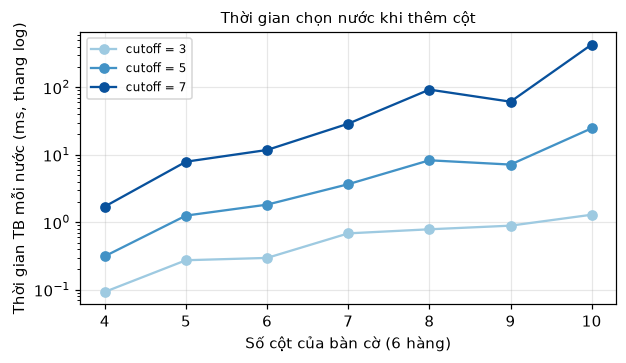

In [38]:
# Your code/ answer goes here.

# ---- Thời gian chọn nước đi khi tăng số cột (6 hàng): bắt đầu từ 4 cột ----
COLS_LIST = [4, 5, 6, 7, 8, 9, 10]
TIME_CUTOFFS = [3, 5, 7]
rows_out, time_data = [], {}
for cols in COLS_LIST:
    row = {"Số cột": cols}
    boards = [initial_state((6, cols))] + [b for b, _ in make_openings((6, cols), 3, plies = 6, seed = cols)]
    for d in TIME_CUTOFFS:
        ts, ns = [], []
        for b in boards:
            agent = HeuristicAlphaBetaPlayer(cutoff = d)
            t0 = time.perf_counter(); agent(b, player_to_move(b)); ts.append(time.perf_counter() - t0); ns.append(agent.nodes)
        time_data[(cols, d)] = (1000 * np.mean(ts), np.mean(ns))
        row[f"d={d}: thời gian TB (ms)"] = round(1000 * np.mean(ts), 1)
        row[f"d={d}: số nút TB"] = f"{np.mean(ns):,.0f}"
    rows_out.append(row)
display(pd.DataFrame(rows_out))

fig, ax = plt.subplots(figsize = (5.8, 3.4), dpi = 110)
for d, color in zip(TIME_CUTOFFS, ("#9ecae1", "#4292c6", "#08519c")):
    ax.plot(COLS_LIST, [time_data[(c, d)][0] for c in COLS_LIST], "o-", color = color, label = f"cutoff = {d}")
ax.set_yscale("log"); ax.set_xlabel("Số cột của bàn cờ (6 hàng)"); ax.set_ylabel("Thời gian TB mỗi nước (ms, thang log)")
ax.set_title("Thời gian chọn nước khi thêm cột", fontsize = 10); ax.legend(fontsize = 8); ax.grid(alpha = .3)
plt.tight_layout(); plt.show()

In [39]:
def per_col(d):
    ms = [time_data[(c, d)][0] for c in COLS_LIST]
    return (ms[-1] / ms[0]) ** (1 / (len(ms) - 1))
beff = lambda c, d: time_data[(c, d)][1] ** (1 / d)
display(Markdown(f"""
**Nhận xét.**
* **Thời gian tăng theo số cột:** thêm một cột nhân thời gian lên ≈ ×{per_col(TIME_CUTOFFS[0]):.2f} (cutoff {TIME_CUTOFFS[0]}), ×{per_col(TIME_CUTOFFS[1]):.2f} (cutoff {TIME_CUTOFFS[1]}) và ×{per_col(TIME_CUTOFFS[2]):.2f} (cutoff {TIME_CUTOFFS[2]}). Cutoff càng sâu thì mỗi cột thêm càng đắt, vì số nút ≈ b^d với hệ số nhánh b tăng theo số cột: hệ số nhánh hiệu dụng (số nút)^(1/d) tăng từ {beff(COLS_LIST[0], TIME_CUTOFFS[2]):.1f} (4 cột) lên {beff(COLS_LIST[-1], TIME_CUTOFFS[2]):.1f} ({COLS_LIST[-1]} cột) ở cutoff {TIME_CUTOFFS[2]}.
* **Con số cụ thể:** ở {COLS_LIST[-1]} cột, mỗi nước mất {time_data[(COLS_LIST[-1], TIME_CUTOFFS[0])][0]:.1f} ms (cutoff {TIME_CUTOFFS[0]}), {time_data[(COLS_LIST[-1], TIME_CUTOFFS[1])][0]:.0f} ms (cutoff {TIME_CUTOFFS[1]}) và {time_data[(COLS_LIST[-1], TIME_CUTOFFS[2])][0]:.0f} ms (cutoff {TIME_CUTOFFS[2]}), so với {time_data[(COLS_LIST[0], TIME_CUTOFFS[2])][0]:.1f} ms ở cutoff {TIME_CUTOFFS[2]} với {COLS_LIST[0]} cột.
* Khác với Task 3 (tìm tới cuối ván, chi phí mũ theo *số ô*), ở đây chi phí chỉ phụ thuộc vào cutoff và hệ số nhánh nên **kiểm soát được**: ta chọn cutoff theo ngân sách thời gian cho kích thước bàn bất kỳ.
"""))


**Nhận xét.**
* **Thời gian tăng theo số cột:** thêm một cột nhân thời gian lên ≈ ×1.55 (cutoff 3), ×2.07 (cutoff 5) và ×2.51 (cutoff 7). Cutoff càng sâu thì mỗi cột thêm càng đắt, vì số nút ≈ b^d với hệ số nhánh b tăng theo số cột: hệ số nhánh hiệu dụng (số nút)^(1/d) tăng từ 2.6 (4 cột) lên 4.7 (10 cột) ở cutoff 7.
* **Con số cụ thể:** ở 10 cột, mỗi nước mất 1.3 ms (cutoff 3), 25 ms (cutoff 5) và 430 ms (cutoff 7), so với 1.7 ms ở cutoff 7 với 4 cột.
* Khác với Task 3 (tìm tới cuối ván, chi phí mũ theo *số ô*), ở đây chi phí chỉ phụ thuộc vào cutoff và hệ số nhánh nên **kiểm soát được**: ta chọn cutoff theo ngân sách thời gian cho kích thước bàn bất kỳ.


### Playtime [5 points]

Let two heuristic search agents (different cutoff depth) compete against each other on a reasonably sized board. Since there is no randomness, you only need to let them play once.

,Đỏ (đi trước),Vàng (đi sau),Kết quả,Số nước,Thời gian đỏ (s),Thời gian vàng (s)
0,D · cutoff 2,D · cutoff 6,đỏ thắng,39,0.00,0.12
1,D · cutoff 2,C · cutoff 4,đỏ thắng,41,0.00,0.02
2,D · cutoff 2,B · cutoff 6,đỏ thắng,39,0.00,0.02
3,D · cutoff 2,A · cutoff 8,đỏ thắng,33,0.00,0.04
4,D · cutoff 6,D · cutoff 2,đỏ thắng,39,0.08,0.00
5,D · cutoff 6,C · cutoff 4,đỏ thắng,39,0.07,0.01
6,D · cutoff 6,B · cutoff 6,đỏ thắng,35,0.08,0.02
7,D · cutoff 6,A · cutoff 8,đỏ thắng,33,0.05,0.04
8,C · cutoff 4,D · cutoff 2,đỏ thắng,39,0.01,0.00
9,C · cutoff 4,D · cutoff 6,đỏ thắng,35,0.01,0.09


,Điểm (tối đa 8)
C · cutoff 4,6.0
D · cutoff 6,4.5
D · cutoff 2,4.0
A · cutoff 8,3.0
B · cutoff 6,2.5


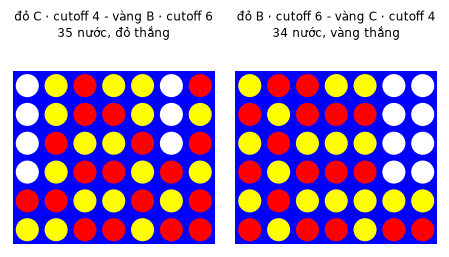

In [40]:
# Your code/ answer goes here.

# ---- Hai tác tử heuristic đấu với nhau trên bàn 6 x 7: khác CẢ độ sâu (cutoff) LẪN hàm heuristic ----
# Các tác tử là xác định và bàn cờ bắt đầu rỗng nên không có yếu tố ngẫu nhiên: mỗi cặp chỉ cần chơi MỘT ván cho mỗi màu quân.
hv = lambda key: HEURISTIC_VARIANTS[[k for k in HEURISTIC_VARIANTS if k.startswith(key)][0]]       # lấy hàm heuristic A / B / C / D
PLAY_AGENTS = {
    "D · cutoff 2": lambda: HeuristicAlphaBetaPlayer(cutoff = 2, evaluate = hv("D")),
    "D · cutoff 6": lambda: HeuristicAlphaBetaPlayer(cutoff = 6, evaluate = hv("D")),
    "C · cutoff 4": lambda: HeuristicAlphaBetaPlayer(cutoff = 4, evaluate = hv("C")),
    "B · cutoff 6": lambda: HeuristicAlphaBetaPlayer(cutoff = 6, evaluate = hv("B")),
    "A · cutoff 8": lambda: HeuristicAlphaBetaPlayer(cutoff = 8, evaluate = hv("A")),
}
outcome = {1: "đỏ thắng", -1: "vàng thắng", 0: "hòa"}
rows_out, games_h, points = [], {}, {k: 0.0 for k in PLAY_AGENTS}
for r_name, r_make in PLAY_AGENTS.items():
    for y_name, y_make in PLAY_AGENTS.items():
        if r_name == y_name: continue
        g_ = play_game(r_make(), y_make())
        games_h[(r_name, y_name)] = g_
        w = g_["winner"]
        points[r_name] += 1 if w == 1 else 0.5 if w == 0 else 0
        points[y_name] += 1 if w == -1 else 0.5 if w == 0 else 0
        rows_out.append({"Đỏ (đi trước)": r_name, "Vàng (đi sau)": y_name, "Kết quả": outcome[w], "Số nước": g_["moves"],
                         "Thời gian đỏ (s)": round(g_["time"][1], 2), "Thời gian vàng (s)": round(g_["time"][-1], 2)})
play_h_table = pd.DataFrame(rows_out)
display(play_h_table)
POINT_COL = f"Điểm (tối đa {2 * (len(PLAY_AGENTS) - 1)})"
standings = pd.DataFrame({POINT_COL: pd.Series(points)}).sort_values(POINT_COL, ascending = False)
display(standings)
best_a, worst_a = standings.index[0], standings.index[-1]
show_games = [(best_a, worst_a), (worst_a, best_a)]
visualize_grid([games_h[k]["board"] for k in show_games],
               [f"đỏ {k[0]} - vàng {k[1]}\n{games_h[k]['moves']} nước, {outcome[games_h[k]['winner']]}" for k in show_games], ncols = 2)

In [41]:
def h2h(a, b):
    """Điểm của a và b trong hai ván giữa họ (mỗi bên cầm quân đỏ một lần)."""
    w1, w2 = games_h[(a, b)]["winner"], games_h[(b, a)]["winner"]
    pa = (1 if w1 == 1 else 0.5 if w1 == 0 else 0) + (1 if w2 == -1 else 0.5 if w2 == 0 else 0)
    return pa, 2 - pa
fmt = lambda a, b: f"{a} – {b}: {h2h(a, b)[0]:g} – {h2h(a, b)[1]:g}"
ranking = ", ".join(f"{k} ({standings.loc[k, POINT_COL]:g})" for k in standings.index)
depth_only, heur_only, both = ("D · cutoff 6", "D · cutoff 2"), ("D · cutoff 6", "B · cutoff 6"), ("C · cutoff 4", "A · cutoff 8")
display(Markdown(f"""
**Nhận xét.** Xếp hạng (điểm tối đa {2 * (len(PLAY_AGENTS) - 1)}): {ranking}.
* **Chỉ khác độ sâu** (cùng hàm D): {fmt(*depth_only)}. **Chỉ khác hàm heuristic** (cùng cutoff 6): {fmt(*heur_only)}. **Khác cả hai** (cặp C · cutoff 4 và A · cutoff 8): {fmt(*both)}.
* Tác tử mạnh nhất là **{best_a}**, yếu nhất là **{worst_a}**. Kết quả phù hợp với thí nghiệm so sánh heuristic ở trên (hàm dựa trên cửa sổ 4 ô vượt hàm chỉ-cột-giữa A kể cả khi A tìm sâu hơn) {'và với việc độ sâu lớn hơn giúp ích khi hai tác tử dùng cùng hàm đánh giá' if h2h(*depth_only)[0] > 1 else '(nhưng ở cặp D cutoff 6 / D cutoff 2 độ sâu lớn hơn không thắng, cho thấy một ván là quá ít để kết luận)'}.
* **Lưu ý về độ tin cậy:** mỗi cặp chỉ có 2 ván (mỗi bên cầm quân đỏ một lần) và các tác tử xác định, nên bảng này mang tính minh họa; kết luận có ý nghĩa thống kê nằm ở ma trận heuristic (hàng trăm ván có khai cuộc ngẫu nhiên) và ở phần nâng cao.
"""))


**Nhận xét.** Xếp hạng (điểm tối đa 8): C · cutoff 4 (6), D · cutoff 6 (4.5), D · cutoff 2 (4), A · cutoff 8 (3), B · cutoff 6 (2.5).
* **Chỉ khác độ sâu** (cùng hàm D): D · cutoff 6 – D · cutoff 2: 1 – 1. **Chỉ khác hàm heuristic** (cùng cutoff 6): D · cutoff 6 – B · cutoff 6: 1.5 – 0.5. **Khác cả hai** (cặp C · cutoff 4 và A · cutoff 8): C · cutoff 4 – A · cutoff 8: 2 – 0.
* Tác tử mạnh nhất là **C · cutoff 4**, yếu nhất là **B · cutoff 6**. Kết quả phù hợp với thí nghiệm so sánh heuristic ở trên (hàm dựa trên cửa sổ 4 ô vượt hàm chỉ-cột-giữa A kể cả khi A tìm sâu hơn) (nhưng ở cặp D cutoff 6 / D cutoff 2 độ sâu lớn hơn không thắng, cho thấy một ván là quá ít để kết luận).
* **Lưu ý về độ tin cậy:** mỗi cặp chỉ có 2 ván (mỗi bên cầm quân đỏ một lần) và các tác tử xác định, nên bảng này mang tính minh họa; kết luận có ý nghĩa thống kê nằm ở ma trận heuristic (hàng trăm ván có khai cuộc ngẫu nhiên) và ở phần nâng cao.


## Task 5: Pure Monte Carlo Search [15 points]

Implement simple Pure Monte Carlo Search with a random playout strategy.

In [42]:
# Your code goes here.

class PureMonteCarloPlayer:
    """Pure Monte Carlo Search với chính sách playout ngẫu nhiên.

    Với trạng thái hiện tại: chia đều N playout cho các nước đi hợp lệ (mỗi nước N // |A| playout, ít nhất 1), mỗi playout đi nước đã chọn
    rồi để hai bên đi NGẪU NHIÊN đến hết ván; chọn nước có lợi ích trung bình lớn nhất. Trạng thái của tác tử: bộ sinh số ngẫu nhiên riêng
    (đặt `seed` để tái lập kết quả) và số playout đã chạy.
    """
    def __init__(self, N = 1000, seed = None, name = None):
        self.N, self.rng, self.playouts = N, random.Random(seed), 0
        self.name = name or f"Pure Monte Carlo (N = {N})"

    def __call__(self, board, player = 1):
        means = self.estimates(board, player)
        return max(means, key = means.get)                    # nước có lợi ích trung bình lớn nhất (bằng nhau: cột nhỏ nhất)

    def estimates(self, board, player = 1):
        """Lợi ích trung bình ước lượng cho từng nước đi: dict cột -> giá trị trong [-1, 1]."""
        g = Geometry.get(*board.shape)
        cur, mask = g.to_bits(board, player)
        acts = [c for c in range(g.cols) if not (mask & g.top[c])]
        n = max(1, self.N // len(acts))
        self.playouts += n * len(acts)
        return {c: sum(self.playout(g, cur, mask, c) for _ in range(n)) / n for c in acts}

    def playout(self, g, cur, mask, column):
        """Một playout bằng bitboard: đi `column`, sau đó hai bên đi ngẫu nhiên; trả về lợi ích (+1/0/-1) đối với người đi đầu."""
        bottom, colm, top, is_win, rnd = g.bottom, g.col_mask, g.top, g.is_win, self.rng.random
        nb = (mask + bottom[column]) & colm[column]
        me = cur | nb
        if is_win(me): return 1
        opp = cur ^ mask                                      # quân đối thủ
        mask |= nb
        open_cols = [c for c in range(g.cols) if not (mask & top[c])]
        opp_to_move = True
        while open_cols:
            c = open_cols[int(rnd() * len(open_cols))]
            nb = (mask + bottom[c]) & colm[c]
            mask |= nb
            if opp_to_move:
                opp |= nb
                if is_win(opp): return -1
            else:
                me |= nb
                if is_win(me): return 1
            if mask & top[c]: open_cols.remove(c)
            opp_to_move = not opp_to_move
        return 0

def playout_numpy(board, action, player = 1):
    """Playout tham chiếu viết bằng các hàm numpy (giống code Tic-Tac-Toe): chậm nhưng dễ kiểm chứng."""
    state, current = result(board, player, action), -player
    while True:
        u = utility(state, player)
        if u is not None: return u
        state = result(state, current, int(np.random.choice(actions(state))))
        current = -current

# ---- Kiểm chứng: playout bitboard cho cùng phân phối kết quả như playout numpy ----
np.random.seed(5)
pm_check = PureMonteCarloPlayer(seed = 5)
checks = [("bàn rỗng, cột 3", initial_state(), 1, 3), ("sau 6 nước, cột 2", board_from_moves([3, 3, 2, 4, 4, 2]), 1, 2),
          ("bàn thử '2. Phải chặn', cột 1", TEST_BOARDS["2. Phải chặn"], 1, 1)]
rows_out = []
for label, b, p, col in checks:
    n_np, n_bb = 3000, 30000
    u_np = np.array([playout_numpy(b, col, p) for _ in range(n_np)])
    g_ = Geometry.get(*b.shape); cur_, mask_ = g_.to_bits(b, p)
    u_bb = np.array([pm_check.playout(g_, cur_, mask_, col) for _ in range(n_bb)])
    se = math.sqrt(u_np.var() / n_np + u_bb.var() / n_bb)
    rows_out.append({"Thế cờ": label, f"TB playout numpy ({n_np})": round(u_np.mean(), 3), f"TB playout bitboard ({n_bb})": round(u_bb.mean(), 3),
                     "Chênh lệch / sai số chuẩn": round(abs(u_np.mean() - u_bb.mean()) / se, 2)})
    assert abs(u_np.mean() - u_bb.mean()) < 4.5 * se
display(pd.DataFrame(rows_out))
print("Hai cách playout cho cùng phân phối (chênh lệch < 4,5 sai số chuẩn).")

,Thế cờ,TB playout numpy (3000),TB playout bitboard (30000),Chênh lệch / sai số chuẩn
0,"bàn rỗng, cột 3",0.304,0.274,1.65
1,"sau 6 nước, cột 2",0.207,0.217,0.55
2,"bàn thử '2. Phải chặn', cột 1",0.484,0.479,0.41


Hai cách playout cho cùng phân phối (chênh lệch < 4,5 sai số chuẩn).


Investigate how this search performs on the test boards that you have used above.

,Cột đúng,N=100: % lần chọn đúng,N=100: cột hay chọn nhất,N=1000: % lần chọn đúng,N=1000: cột hay chọn nhất,N=10000: % lần chọn đúng,N=10000: cột hay chọn nhất
Bàn cờ,,,,,,,
1. Thắng ngay,2,100,2,100,2,100,2
2. Phải chặn,1,97,1,100,1,100,1
3. Thắng sau 3 nửa-nước,"0,1,3,4",90,1,97,1,100,1
4. Thắng sau 5 nửa-nước,"1,4,5",97,4,100,4,100,4
5. Thắng sau 7 nửa-nước,6,3,1,27,5,87,6
6. Chỉ hòa nếu đi đúng,"5,6",63,5,100,5,100,5
7. Thế thua,"0,1,4,5,6",100,0,100,0,100,0
TRUNG BÌNH,,79,0.6 ms/nước,89,6.1 ms/nước,98,64.6 ms/nước


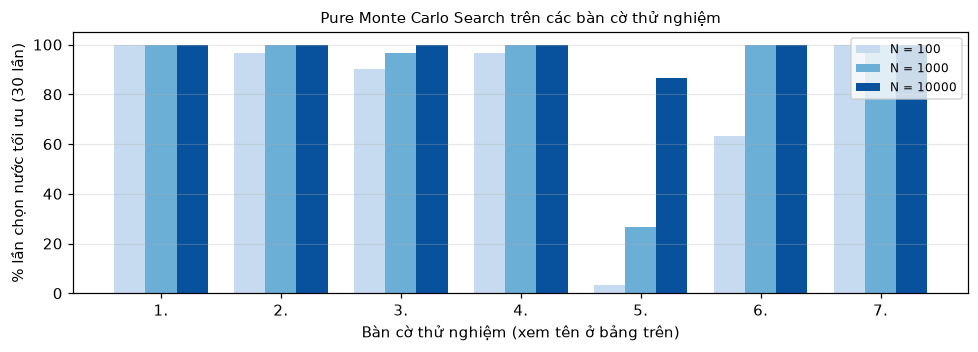

In [43]:
# Your code/ answer goes here.

# ---- Pure Monte Carlo Search trên 7 bàn cờ thử nghiệm: lặp lại nhiều lần vì kết quả có tính ngẫu nhiên ----
PM_NS = [100, 1000, 10000]
PM_REPEAT = 30
rows_out, pm_success, pm_time = [], {}, {N: [] for N in PM_NS}
for name, b in TEST_BOARDS.items():
    info = TEST_INFO[name]
    row = {"Bàn cờ": name, "Cột đúng": ",".join(map(str, sorted(info["optimal"])))}
    for N in PM_NS:
        agent = PureMonteCarloPlayer(N, seed = 100 + N)
        picks = []
        for _ in range(PM_REPEAT):
            t0 = time.perf_counter(); picks.append(agent(b, info["player"])); pm_time[N].append(time.perf_counter() - t0)
        pm_success[(name, N)] = np.mean([a in info["optimal"] for a in picks])
        row[f"N={N}: % lần chọn đúng"] = round(100 * pm_success[(name, N)])
        row[f"N={N}: cột hay chọn nhất"] = Counter(picks).most_common(1)[0][0]
    rows_out.append(row)
pm_table = pd.DataFrame(rows_out)
summary = {"Bàn cờ": "TRUNG BÌNH", "Cột đúng": ""}
for N in PM_NS:
    summary[f"N={N}: % lần chọn đúng"] = round(100 * np.mean([pm_success[(n, N)] for n in TEST_NAMES]))
    summary[f"N={N}: cột hay chọn nhất"] = f"{1000 * np.mean(pm_time[N]):.1f} ms/nước"
display(pd.concat([pm_table, pd.DataFrame([summary])]).set_index("Bàn cờ"))

fig, ax = plt.subplots(figsize = (9, 3.3), dpi = 110)
w = 0.26
for k, N in enumerate(PM_NS):
    ax.bar(np.arange(7) + (k - 1) * w, [100 * pm_success[(n, N)] for n in TEST_NAMES], w, label = f"N = {N}", color = ("#c6dbef", "#6baed6", "#08519c")[k])
ax.set_xticks(range(7)); ax.set_xticklabels([n.split(".")[0] + "." for n in TEST_NAMES]); ax.set_xlabel("Bàn cờ thử nghiệm (xem tên ở bảng trên)"); ax.set_ylabel(f"% lần chọn nước tối ưu ({PM_REPEAT} lần)")
ax.set_title("Pure Monte Carlo Search trên các bàn cờ thử nghiệm", fontsize = 10); ax.legend(fontsize = 8); ax.grid(axis = "y", alpha = .3)
plt.tight_layout(); plt.show()

In [44]:
avg_acc = {N: 100 * np.mean([pm_success[(n, N)] for n in TEST_NAMES]) for N in PM_NS}
hard = min(TEST_NAMES, key = lambda n: pm_success[(n, PM_NS[0])] + pm_success[(n, PM_NS[1])])
easy = [n for n in TEST_NAMES if all(pm_success[(n, N)] >= 0.9 for N in PM_NS)]
display(Markdown(f"""
**Nhận xét.** Tỷ lệ chọn đúng trung bình trên 7 bàn là {avg_acc[PM_NS[0]]:.0f} % (N = {PM_NS[0]}), {avg_acc[PM_NS[1]]:.0f} % (N = {PM_NS[1]}) và {avg_acc[PM_NS[2]]:.0f} % (N = {PM_NS[2]}), với thời gian {1000 * np.mean(pm_time[PM_NS[0]]):.1f} / {1000 * np.mean(pm_time[PM_NS[1]]):.1f} / {1000 * np.mean(pm_time[PM_NS[2]]):.0f} ms mỗi nước – tăng tuyến tính theo N, còn độ chính xác tăng chậm dần.
* **Dễ với Monte Carlo** ({len(easy)} bàn đạt ≥ 90 % ở mọi N): {', '.join(n.split('.')[1].strip() for n in easy) or 'không bàn nào'} – nước thắng ngay/chặn có giá trị trung bình chênh lệch rất lớn so với nước khác nên ít playout cũng nhận ra.
* **Khó nhất: "{hard}"** ({100 * pm_success[(hard, PM_NS[0])]:.0f} % → {100 * pm_success[(hard, PM_NS[1])]:.0f} % → {100 * pm_success[(hard, PM_NS[2])]:.0f} % khi tăng N). Đây là các bàn chỉ có *một* nước đúng và đòn thắng sâu: playout ngẫu nhiên không biết chặn nên lợi ích trung bình của nước đúng bị "chìm" trong nhiễu; cần N lớn mới tách được.
* Khác Alpha-Beta (xác định, đúng/sai rõ ràng), Monte Carlo **ngẫu nhiên** nên ta lặp mỗi bàn {PM_REPEAT} lần và báo tỷ lệ chọn đúng; sai số ước lượng của mỗi giá trị giảm theo 1/√N.
* So với Heuristic Alpha-Beta trên cùng 7 bàn (đúng {hab_correct[8] if 8 in hab_correct else max(hab_correct.values())}/7 bàn ở cutoff 8, vài chục ms/nước), Monte Carlo cần N lớn hơn nhiều và thời gian nhiều hơn để đạt độ chính xác tương đương.
"""))


**Nhận xét.** Tỷ lệ chọn đúng trung bình trên 7 bàn là 79 % (N = 100), 89 % (N = 1000) và 98 % (N = 10000), với thời gian 0.6 / 6.1 / 65 ms mỗi nước – tăng tuyến tính theo N, còn độ chính xác tăng chậm dần.
* **Dễ với Monte Carlo** (5 bàn đạt ≥ 90 % ở mọi N): Thắng ngay, Phải chặn, Thắng sau 3 nửa-nước, Thắng sau 5 nửa-nước, Thế thua – nước thắng ngay/chặn có giá trị trung bình chênh lệch rất lớn so với nước khác nên ít playout cũng nhận ra.
* **Khó nhất: "5. Thắng sau 7 nửa-nước"** (3 % → 27 % → 87 % khi tăng N). Đây là các bàn chỉ có *một* nước đúng và đòn thắng sâu: playout ngẫu nhiên không biết chặn nên lợi ích trung bình của nước đúng bị "chìm" trong nhiễu; cần N lớn mới tách được.
* Khác Alpha-Beta (xác định, đúng/sai rõ ràng), Monte Carlo **ngẫu nhiên** nên ta lặp mỗi bàn 30 lần và báo tỷ lệ chọn đúng; sai số ước lượng của mỗi giá trị giảm theo 1/√N.
* So với Heuristic Alpha-Beta trên cùng 7 bàn (đúng 7/7 bàn ở cutoff 8, vài chục ms/nước), Monte Carlo cần N lớn hơn nhiều và thời gian nhiều hơn để đạt độ chính xác tương đương.


Which implementation plays stronger stronger? Discuss why you think that is the case and what it depends on.

`<Your Answer goes here>`

In [45]:
# ---- Heuristic Alpha-Beta so với Pure Monte Carlo Search: đấu trực tiếp trên bàn 6 x 7 ----
HAB_DEPTHS_DUEL, PM_NS_DUEL = [2, 4, 6], [100, 1000, 5000]
openings_d = make_openings((6, 7), 15, seed = 21)
rows_out, duel_res = [], {}
t0 = time.time()
for d in HAB_DEPTHS_DUEL:
    for N in PM_NS_DUEL:
        r = duel(HeuristicAlphaBetaPlayer(cutoff = d), PureMonteCarloPlayer(N, seed = N + d), openings_d)
        duel_res[(d, N)] = r
        rows_out.append({"Heuristic AB (cutoff)": d, "Monte Carlo (N)": N, "Thời gian/nước AB (ms)": round(r["ms_a"], 1), "Thời gian/nước MC (ms)": round(r["ms_b"], 1),
                         "AB thắng": r["W"], "Hòa": r["D"], "AB thua": r["L"], "Điểm AB": round(r["score"], 2)})
duel_table = pd.DataFrame(rows_out)
display(duel_table)
print(f"({2 * len(openings_d)} ván mỗi dòng, khai cuộc ngẫu nhiên 4 nước, đổi màu; điểm: thắng = 1, hòa = 0,5; {time.time() - t0:.0f} s)")

,Heuristic AB (cutoff),Monte Carlo (N),Thời gian/nước AB (ms),Thời gian/nước MC (ms),AB thắng,Hòa,AB thua,Điểm AB
0,2,100,0.1,1.0,28,1,1,0.95
1,2,1000,0.1,8.7,16,3,11,0.58
2,2,5000,0.1,37.9,17,0,13,0.57
3,4,100,1.6,1.3,29,0,1,0.97
4,4,1000,0.9,8.2,21,1,8,0.72
5,4,5000,1.3,50.2,19,0,11,0.63
6,6,100,9.6,1.2,28,1,1,0.95
7,6,1000,7.7,11.0,22,0,8,0.73
8,6,5000,6.5,43.0,22,1,7,0.75


(30 ván mỗi dòng, khai cuộc ngẫu nhiên 4 nước, đổi màu; điểm: thắng = 1, hòa = 0,5; 66 s)


In [46]:
best_row = duel_table.sort_values("Điểm AB", ascending = False).iloc[0]
ab_wins_all = (duel_table["Điểm AB"] > 0.5).all()
ab_only_cheaper = duel_table[duel_table["Thời gian/nước AB (ms)"] < duel_table["Thời gian/nước MC (ms)"]]
display(Markdown(f"""
**Cái nào chơi mạnh hơn?** Trong {len(duel_table)} cặp cấu hình ở bảng trên, Heuristic Alpha-Beta {'**thắng (điểm > 0,5) ở tất cả các cặp**' if ab_wins_all else 'thắng ở phần lớn các cặp'}; điểm của Alpha-Beta dao động từ {duel_table['Điểm AB'].min():.2f} đến {duel_table['Điểm AB'].max():.2f}. {'Ngay cả khi dùng ít thời gian hơn (' + str(len(ab_only_cheaper)) + ' cặp), nó vẫn chiếm ưu thế.' if len(ab_only_cheaper) and (ab_only_cheaper['Điểm AB'] > 0.5).all() else ''}
Vì cutoff càng sâu / N càng lớn thì mạnh hơn, hàng cho thấy Monte Carlo cần **rất nhiều** playout mới theo kịp một Alpha-Beta nông: ở cutoff = 2 (mất chưa tới vài ms), Monte Carlo với N = {PM_NS_DUEL[-1]} (≈ {duel_table[(duel_table['Heuristic AB (cutoff)'] == 2) & (duel_table['Monte Carlo (N)'] == PM_NS_DUEL[-1])]['Thời gian/nước MC (ms)'].iloc[0]:.0f} ms/nước) đạt điểm {1 - duel_res[(2, PM_NS_DUEL[-1])]['score']:.2f} trong khi Alpha-Beta chỉ tốn {duel_res[(2, PM_NS_DUEL[-1])]['ms_a']:.1f} ms/nước.

**Vì sao như vậy, và nó phụ thuộc vào điều gì?**
1. **Chất lượng đánh giá mỗi nước.** Playout ngẫu nhiên đánh giá một thế cờ bằng kết quả của hai người chơi *rất yếu*, nên bỏ sót các thế cờ chiến thuật: một đe dọa thắng của đối thủ chỉ được tính khi chính playout ngẫu nhiên tình cờ đi đúng vào ô đó. Hàm heuristic cộng với tìm kiếm có hệ thống thì *chắc chắn* thấy mọi nước thắng/chặn trong tầm tìm kiếm (xem 7 bàn thử).
2. **Phương sai.** Ước lượng Monte Carlo có sai số ∝ 1/√N (muốn giảm sai số 10 lần phải tăng N lên 100 lần), trong khi Alpha-Beta tìm kiếm là xác định và cho kết quả chính xác trong tầm nhìn.
3. **Kích thước trò chơi.** Ở Connect 4 nhánh dài (tới 42 nước) và nhiều thế cờ chỉ có 1 nước đúng duy nhất (hàng 'Phải chặn' và 'Thắng sau 7 nửa-nước'): lợi ích trung bình của nước duy nhất ấy bị "chìm" giữa nhiễu của các playout.
4. **Khi nào Monte Carlo có lợi?** Khi không có hàm heuristic tốt (Go), hệ số nhánh rất lớn, hoặc kết hợp với chọn lọc UCB1 + cây tìm kiếm (MCTS) và chính sách playout tốt hơn ngẫu nhiên. Với Connect 4 – hệ số nhánh nhỏ (≤ 7) và có heuristic đơn giản hiệu quả – Alpha-Beta vượt trội.

Mạnh yếu còn phụ thuộc vào **ngân sách thời gian** (cả hai thuật toán đều tốt lên khi được nhiều thời gian hơn – xem phần nâng cao) và vào **giai đoạn của ván cờ**: gần cuối ván cây nhỏ nên Alpha-Beta giải gần như chính xác, còn Monte Carlo vẫn nhiễu.
"""))


**Cái nào chơi mạnh hơn?** Trong 9 cặp cấu hình ở bảng trên, Heuristic Alpha-Beta **thắng (điểm > 0,5) ở tất cả các cặp**; điểm của Alpha-Beta dao động từ 0.57 đến 0.97. Ngay cả khi dùng ít thời gian hơn (7 cặp), nó vẫn chiếm ưu thế.
Vì cutoff càng sâu / N càng lớn thì mạnh hơn, hàng cho thấy Monte Carlo cần **rất nhiều** playout mới theo kịp một Alpha-Beta nông: ở cutoff = 2 (mất chưa tới vài ms), Monte Carlo với N = 5000 (≈ 38 ms/nước) đạt điểm 0.43 trong khi Alpha-Beta chỉ tốn 0.1 ms/nước.

**Vì sao như vậy, và nó phụ thuộc vào điều gì?**
1. **Chất lượng đánh giá mỗi nước.** Playout ngẫu nhiên đánh giá một thế cờ bằng kết quả của hai người chơi *rất yếu*, nên bỏ sót các thế cờ chiến thuật: một đe dọa thắng của đối thủ chỉ được tính khi chính playout ngẫu nhiên tình cờ đi đúng vào ô đó. Hàm heuristic cộng với tìm kiếm có hệ thống thì *chắc chắn* thấy mọi nước thắng/chặn trong tầm tìm kiếm (xem 7 bàn thử).
2. **Phương sai.** Ước lượng Monte Carlo có sai số ∝ 1/√N (muốn giảm sai số 10 lần phải tăng N lên 100 lần), trong khi Alpha-Beta tìm kiếm là xác định và cho kết quả chính xác trong tầm nhìn.
3. **Kích thước trò chơi.** Ở Connect 4 nhánh dài (tới 42 nước) và nhiều thế cờ chỉ có 1 nước đúng duy nhất (hàng 'Phải chặn' và 'Thắng sau 7 nửa-nước'): lợi ích trung bình của nước duy nhất ấy bị "chìm" giữa nhiễu của các playout.
4. **Khi nào Monte Carlo có lợi?** Khi không có hàm heuristic tốt (Go), hệ số nhánh rất lớn, hoặc kết hợp với chọn lọc UCB1 + cây tìm kiếm (MCTS) và chính sách playout tốt hơn ngẫu nhiên. Với Connect 4 – hệ số nhánh nhỏ (≤ 7) và có heuristic đơn giản hiệu quả – Alpha-Beta vượt trội.

Mạnh yếu còn phụ thuộc vào **ngân sách thời gian** (cả hai thuật toán đều tốt lên khi được nhiều thời gian hơn – xem phần nâng cao) và vào **giai đoạn của ván cờ**: gần cuối ván cây nhỏ nên Alpha-Beta giải gần như chính xác, còn Monte Carlo vẫn nhiễu.


## Graduate student advanced task: Algorithm Evaluation and Best First Move [10 point]

__Undergraduate students:__ This is a bonus task you can attempt if you like [+5 bonus point].

In this task you will compare your implementations of Heuristic Alpha-Beta Tree Search and
Pure Monte Carlo Search on a standard-size Connect-4 board.

### Parameter Tuning 

#### Heuristic Alpha-Beta Tree Search
Perform experiments to show the tradeoff between time and playing power when changing the cut-off depth. 
Things to think about:
* How can you measure performance?
* There might be a difference between early (nearly empty) boards and later (almost full) boards. 

Show the tradeoff in an appropriate graph.  

In [47]:
# Your code/ answer goes here.

# =====================================================================================================
# Phương pháp đo "sức mạnh chơi" (dùng cho cả Heuristic Alpha-Beta và Pure Monte Carlo) trên bàn chuẩn 6 x 7
#   (1) THỜI GIAN mỗi nước (ms) và số nút, đo riêng cho ba giai đoạn của ván: đầu (4–8 quân), giữa (14–20), cuối (26–34).
#   (2) ĐỘ CHÍNH XÁC so với lời giải chính xác: ở giai đoạn giữa/cuối ta giải ĐÚNG các thế cờ bằng Alpha-Beta tối ưu (Task 3) và đếm tỷ lệ
#       nước chọn giữ được giá trị lý thuyết (chỉ tính các thế cờ "có phân biệt", tức là có nước đi làm mất kết quả). Giai đoạn đầu quá lớn để giải.
#   (3) ĐIỂM THI ĐẤU: đấu với một đối thủ tham chiếu cố định (Heuristic Alpha-Beta, cutoff = 4) trên các khai cuộc ngẫu nhiên, đổi màu quân.
# =====================================================================================================
GRAD_SHAPE = (6, 7)
PHASES = {"đầu (4–8 quân)": (4, 8), "giữa (14–20 quân)": (14, 20), "cuối (26–34 quân)": (26, 34)}
N_POS, N_OPEN_GRAD = 15, 10
EXACT_LIMIT = 3000000

def sample_positions(n_per_phase, seed = 2026):
    """Lấy các thế cờ từ ván tự đấu của Heuristic Alpha-Beta (cutoff = 3, 15 % nước đi ngẫu nhiên): mỗi ván đóng góp tối đa 1 thế cờ cho mỗi giai đoạn."""
    rng = random.Random(seed)
    guide = HeuristicAlphaBetaPlayer(cutoff = 3)
    got, seen = {ph: [] for ph in PHASES}, set()
    games = 0
    while any(len(v) < n_per_phase for v in got.values()) and games < 4000:
        games += 1
        board, p = make_openings(GRAD_SHAPE, 1, seed = rng.randrange(10 ** 9))[0]
        target = {ph: rng.randint(lo, hi) for ph, (lo, hi) in PHASES.items()}
        while not terminal(board):
            k = int((board != 0).sum())
            for ph, kt in target.items():
                if k == kt and len(got[ph]) < n_per_phase and board.tobytes() not in seen:
                    seen.add(board.tobytes()); got[ph].append((board.copy(), p))
            a = rng.choice(actions(board)) if rng.random() < 0.15 else guide(board, p)
            board, p = result(board, p, a), -p
    return got

t0 = time.time()
POSITIONS = sample_positions(N_POS)
solver_grad = AlphaBetaPlayer(ordering = "center", forced = True, use_tt = True, node_limit = EXACT_LIMIT, name = "bộ giải chính xác")
EXACT = {}                                              # (giai đoạn, chỉ số) -> thông tin chính xác (hoặc None nếu không giải được)
for ph, plist in POSITIONS.items():
    for i, (b, p) in enumerate(plist):
        if ph.startswith("đầu"): EXACT[(ph, i)] = None; continue
        try:
            vals = solver_grad.action_values(b, p)
            best = max(vals.values())
            optimal = {c for c, v in vals.items() if v == best}
            EXACT[(ph, i)] = dict(values = vals, optimal = optimal, informative = len(optimal) < len(vals), best = best)
        except AlphaBetaPlayer.NodeLimit:
            EXACT[(ph, i)] = None
rows_out = []
for ph, plist in POSITIONS.items():
    ex = [EXACT[(ph, i)] for i in range(len(plist))]
    solved = [e for e in ex if e]
    rows_out.append({"Giai đoạn": ph, "Số thế cờ lấy mẫu": len(plist), "Giải được chính xác": len(solved) if not ph.startswith("đầu") else "— (quá lớn)",
                     "Có phân biệt (dùng đo độ chính xác)": sum(e["informative"] for e in solved) if solved else "—"})
display(pd.DataFrame(rows_out))
print(f"[{time.time() - t0:.0f} s]  Bộ giải chính xác dùng Alpha-Beta từ giữa ra + cắt nước thua + bảng chuyển vị (giới hạn {EXACT_LIMIT:,} nút/thế cờ).")

def evaluate_on_positions(make_agent, repeats = 1):
    """Đo thời gian (ms/nước), số nút và độ chính xác (% nước tối ưu) của một cấu hình trên các thế cờ lấy mẫu."""
    out = {}
    for ph, plist in POSITIONS.items():
        ts, ns, ok, tot = [], [], 0, 0
        for i, (b, p) in enumerate(plist):
            agent = make_agent()
            ex = EXACT[(ph, i)]
            for _ in range(repeats):
                t0 = time.perf_counter(); a = agent(b, p); ts.append(1000 * (time.perf_counter() - t0))
                ns.append(getattr(agent, "nodes", getattr(agent, "playouts", 0)))
                if ex and ex["informative"]:
                    tot += 1; ok += a in ex["optimal"]
        out[ph] = dict(ms = float(np.mean(ts)), nodes = float(np.mean(ns)), acc = (100 * ok / tot if tot else None), n_acc = tot)
    return out

REFERENCE = HeuristicAlphaBetaPlayer(cutoff = 4, name = "tham chiếu (cutoff 4)")
openings_g = make_openings(GRAD_SHAPE, N_OPEN_GRAD, seed = 99)
pc = lambda x: "—" if x is None or (isinstance(x, float) and math.isnan(x)) else f"{x:.0f} %"        # định dạng phần trăm (độ chính xác có thể không đo được)

,Giai đoạn,Số thế cờ lấy mẫu,Giải được chính xác,Có phân biệt (dùng đo độ chính xác)
0,đầu (4–8 quân),15,— (quá lớn),—
1,giữa (14–20 quân),15,15,5
2,cuối (26–34 quân),15,15,5


[4 s]  Bộ giải chính xác dùng Alpha-Beta từ giữa ra + cắt nước thua + bảng chuyển vị (giới hạn 3,000,000 nút/thế cờ).


cutoff 1: xong (0 s); cutoff 2: xong (0 s); cutoff 3: xong (1 s); cutoff 4: xong (1 s); cutoff 5: xong (3 s); cutoff 6: xong (6 s); cutoff 7: xong (13 s); cutoff 8: xong (25 s); 


,cutoff,ms/nước – đầu,ms/nước – giữa,ms/nước – cuối,% đúng – giữa,% đúng – cuối,Điểm vs. tham chiếu,± sai số chuẩn,Thắng/Hòa/Thua
0,1,0.07,0.06,0.05,60,80,0.15,0.08,3/0/17
1,2,0.11,0.14,0.06,60,100,0.42,0.11,8/1/11
2,3,0.53,0.41,0.08,80,100,0.30,0.10,5/2/13
3,4,1.25,0.86,0.11,60,100,0.50,0.11,8/4/8
4,5,4.09,1.95,0.18,100,100,0.62,0.11,11/3/6
5,6,11.79,5.23,0.28,60,100,0.68,0.10,12/3/5
6,7,36.72,9.34,0.38,100,100,0.72,0.10,13/3/4
7,8,89.75,48.77,1.09,80,100,0.78,0.09,14/3/3


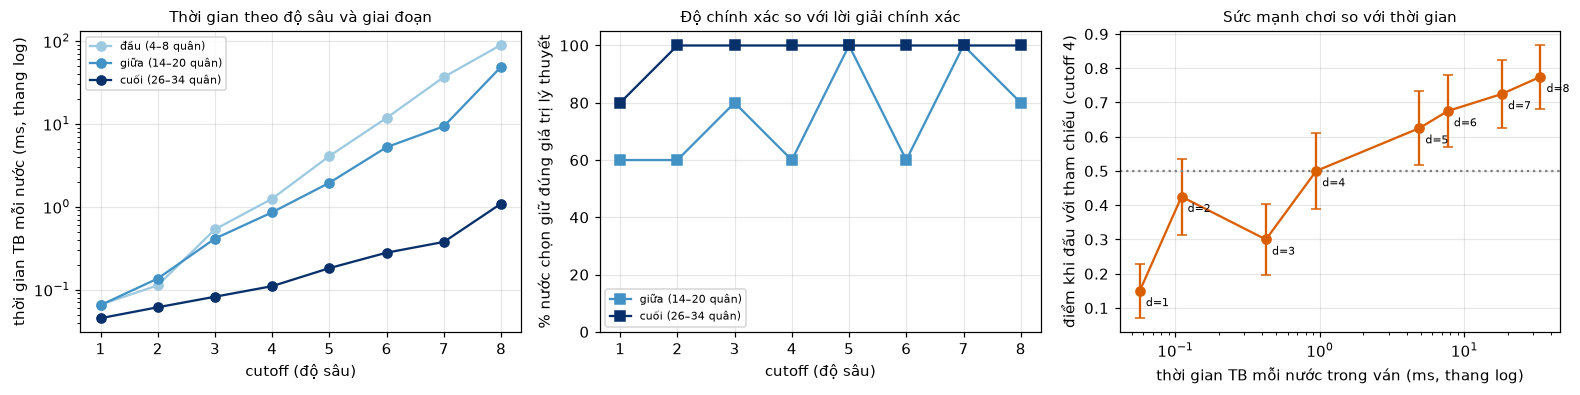

In [48]:
# ======================= Heuristic Alpha-Beta: đánh đổi giữa thời gian và sức mạnh khi đổi cutoff =======================
GRAD_DEPTHS = [1, 2, 3, 4, 5, 6, 7, 8]
hab_eval, hab_duel = {}, {}
t0 = time.time()
for d in GRAD_DEPTHS:
    hab_eval[d] = evaluate_on_positions(lambda d = d: HeuristicAlphaBetaPlayer(cutoff = d))
    hab_duel[d] = duel(HeuristicAlphaBetaPlayer(cutoff = d), REFERENCE, openings_g)      # cutoff 4 đấu với chính nó: điểm đúng 0,5 vì hai tác tử giống hệt nhau
    print(f"cutoff {d}: xong ({time.time() - t0:.0f} s)", end = "; ")
print()

ph_names = list(PHASES)
rows_out = []
for d in GRAD_DEPTHS:
    r = hab_eval[d]
    rows_out.append({"cutoff": d,
                     **{f"ms/nước – {ph.split(' ')[0]}": round(r[ph]["ms"], 2) for ph in ph_names},
                     **{f"% đúng – {ph.split(' ')[0]}": (round(r[ph]["acc"]) if r[ph]["acc"] is not None else "—") for ph in ph_names[1:]},
                     "Điểm vs. tham chiếu": round(hab_duel[d]["score"], 2) + 0.0, "± sai số chuẩn": round(se_score(hab_duel[d]["score"], hab_duel[d]["games"]), 2),
                     "Thắng/Hòa/Thua": f"{hab_duel[d]['W']}/{hab_duel[d]['D']}/{hab_duel[d]['L']}"})
hab_grad_table = pd.DataFrame(rows_out)
display(hab_grad_table)

def mean_time_all(res):  # thời gian TB mỗi nước trên toàn ván (trung bình ba giai đoạn)
    return float(np.mean([res[ph]["ms"] for ph in res]))

fig, ax = plt.subplots(1, 3, figsize = (14.5, 3.7), dpi = 110)
for ph, color in zip(ph_names, ("#9ecae1", "#4292c6", "#08306b")):
    ax[0].plot(GRAD_DEPTHS, [hab_eval[d][ph]["ms"] for d in GRAD_DEPTHS], "o-", color = color, label = ph)
ax[0].set_yscale("log"); ax[0].set_xlabel("cutoff (độ sâu)"); ax[0].set_ylabel("thời gian TB mỗi nước (ms, thang log)"); ax[0].set_title("Thời gian theo độ sâu và giai đoạn", fontsize = 10); ax[0].legend(fontsize = 7); ax[0].grid(alpha = .3)
for ph, color in zip(ph_names[1:], ("#4292c6", "#08306b")):
    ax[1].plot(GRAD_DEPTHS, [hab_eval[d][ph]["acc"] if hab_eval[d][ph]["acc"] is not None else np.nan for d in GRAD_DEPTHS], "s-", color = color, label = ph)
ax[1].set_ylim(0, 105); ax[1].set_xlabel("cutoff (độ sâu)"); ax[1].set_ylabel("% nước chọn giữ đúng giá trị lý thuyết"); ax[1].set_title("Độ chính xác so với lời giải chính xác", fontsize = 10); ax[1].legend(fontsize = 7); ax[1].grid(alpha = .3)
xs = [hab_duel[d]["ms_a"] for d in GRAD_DEPTHS]
ax[2].errorbar(xs, [hab_duel[d]["score"] for d in GRAD_DEPTHS], yerr = [se_score(hab_duel[d]["score"], hab_duel[d]["games"]) for d in GRAD_DEPTHS], fmt = "o-", color = "#d95f02", capsize = 3)
for x_, d in zip(xs, GRAD_DEPTHS): ax[2].annotate(f"d={d}", (x_, hab_duel[d]["score"]), textcoords = "offset points", xytext = (4, -10), fontsize = 7)
ax[2].set_xscale("log"); ax[2].axhline(0.5, color = "gray", ls = ":"); ax[2].set_xlabel("thời gian TB mỗi nước trong ván (ms, thang log)"); ax[2].set_ylabel("điểm khi đấu với tham chiếu (cutoff 4)"); ax[2].set_title("Sức mạnh chơi so với thời gian", fontsize = 10); ax[2].grid(alpha = .3)
plt.tight_layout(); plt.show()

In [49]:
d_lo, d_hi = GRAD_DEPTHS[0], GRAD_DEPTHS[-1]
d_best = max(GRAD_DEPTHS, key = lambda d: hab_duel[d]["score"])
early, mid, late = ph_names
ms = lambda d, ph: hab_eval[d][ph]["ms"]
acc = lambda d, ph: hab_eval[d][ph]["acc"]
growth = (ms(d_hi, mid) / ms(d_lo, mid)) ** (1 / (len(GRAD_DEPTHS) - 1))
scores = [hab_duel[d]["score"] for d in GRAD_DEPTHS]
slope = float(np.polyfit(np.log10([hab_duel[d]["ms_a"] for d in GRAD_DEPTHS]), scores, 1)[0])      # điểm tăng thêm khi nhân thời gian lên 10 lần
se_g = se_score(0.5, 2 * N_OPEN_GRAD)
drops = [f"cutoff {a} → {b} ({hab_duel[a]['score']:.2f} → {hab_duel[b]['score']:.2f})" for a, b in zip(GRAD_DEPTHS, GRAD_DEPTHS[1:]) if hab_duel[b]["score"] < hab_duel[a]["score"] - 1e-9]
sat = next((d for d in GRAD_DEPTHS if acc(d, late) is not None and acc(d, late) >= 99.9), None)
n_inf = hab_eval[d_lo][mid]["n_acc"]
display(Markdown(f"""
**Cách đo sức mạnh (trả lời "How can you measure performance?")** – ba thước đo bổ sung cho nhau: (1) *thời gian và số nút* mỗi nước; (2) *độ chính xác so với lời giải chính xác* trên các thế cờ giữa/cuối ván mà bộ giải Task 3 giải được (tỷ lệ nước chọn giữ nguyên giá trị lý thuyết); (3) *điểm thi đấu* với một đối thủ tham chiếu cố định (Heuristic Alpha-Beta cutoff 4) trên {N_OPEN_GRAD} khai cuộc ngẫu nhiên × 2 màu quân (thắng = 1, hòa = 0,5).

**Nhận xét**
* **Thời gian tăng theo hàm mũ với độ sâu:** khoảng ×{growth:.1f} mỗi mức ở giai đoạn giữa, từ {ms(d_lo, mid):.2f} ms (cutoff {d_lo}) lên {ms(d_hi, mid):.0f} ms (cutoff {d_hi}). Giai đoạn cũng quan trọng: ở cutoff {d_hi}, mỗi nước tốn {ms(d_hi, early):.0f} ms (đầu ván), {ms(d_hi, mid):.0f} ms (giữa) và {ms(d_hi, late):.1f} ms (cuối) – ít ô trống thì cây nhỏ; ngoài ra độ sâu lớn chạm tới trạng thái kết thúc nên đánh giá trở thành *chính xác* thay vì heuristic.
* **Độ chính xác** so với lời giải đúng: giữa ván {pc(acc(d_lo, mid))} (cutoff {d_lo}) → {pc(acc(d_hi, mid))} (cutoff {d_hi}); cuối ván {pc(acc(d_lo, late))} → {pc(acc(d_hi, late))}{' (từ cutoff ' + str(sat) + ' trở đi đạt 100 %)' if sat else ''}. Số lần chọn có phân biệt chỉ cỡ {n_inf} mỗi mức nên mỗi phần trăm có sai số lớn (một thế cờ đổi ≈ {100 / max(n_inf, 1):.0f} điểm %); ở giai đoạn đầu không giải được chính xác nên không đo.
* **Điểm thi đấu** tăng từ {scores[0]:.2f} (cutoff {d_lo}) lên {hab_duel[d_best]['score']:.2f} (cutoff {d_best}); hồi quy theo log thời gian cho thấy mỗi lần nhân thời gian lên 10 lần, điểm tăng thêm ≈ {slope:.2f}. Sai số chuẩn mỗi điểm khoảng ±{se_g:.2f} ({2 * N_OPEN_GRAD} ván){'; điểm không tăng đơn điệu ở ' + ', '.join(drops) + ' – các chênh lệch này nhỏ so với sai số chuẩn, nên chưa chắc có ý nghĩa thống kê.' if drops else '.'}
* **Kết luận về đánh đổi:** thời gian tăng theo hàm mũ, điểm tăng gần như tuyến tính theo log thời gian, nên mỗi mức sâu thêm tốn nhiều thời gian gấp bội cho một mức cải thiện gần như cố định. Do đó nên chọn cutoff theo ngân sách thời gian, và có thể **tăng độ sâu khi ván cờ tiến triển** (cây nhỏ dần) – tinh thần của tìm kiếm sâu dần (iterative deepening) trong thực tế.
"""))


**Cách đo sức mạnh (trả lời "How can you measure performance?")** – ba thước đo bổ sung cho nhau: (1) *thời gian và số nút* mỗi nước; (2) *độ chính xác so với lời giải chính xác* trên các thế cờ giữa/cuối ván mà bộ giải Task 3 giải được (tỷ lệ nước chọn giữ nguyên giá trị lý thuyết); (3) *điểm thi đấu* với một đối thủ tham chiếu cố định (Heuristic Alpha-Beta cutoff 4) trên 10 khai cuộc ngẫu nhiên × 2 màu quân (thắng = 1, hòa = 0,5).

**Nhận xét**
* **Thời gian tăng theo hàm mũ với độ sâu:** khoảng ×2.6 mỗi mức ở giai đoạn giữa, từ 0.06 ms (cutoff 1) lên 49 ms (cutoff 8). Giai đoạn cũng quan trọng: ở cutoff 8, mỗi nước tốn 90 ms (đầu ván), 49 ms (giữa) và 1.1 ms (cuối) – ít ô trống thì cây nhỏ; ngoài ra độ sâu lớn chạm tới trạng thái kết thúc nên đánh giá trở thành *chính xác* thay vì heuristic.
* **Độ chính xác** so với lời giải đúng: giữa ván 60 % (cutoff 1) → 80 % (cutoff 8); cuối ván 80 % → 100 % (từ cutoff 2 trở đi đạt 100 %). Số lần chọn có phân biệt chỉ cỡ 5 mỗi mức nên mỗi phần trăm có sai số lớn (một thế cờ đổi ≈ 20 điểm %); ở giai đoạn đầu không giải được chính xác nên không đo.
* **Điểm thi đấu** tăng từ 0.15 (cutoff 1) lên 0.78 (cutoff 8); hồi quy theo log thời gian cho thấy mỗi lần nhân thời gian lên 10 lần, điểm tăng thêm ≈ 0.20. Sai số chuẩn mỗi điểm khoảng ±0.11 (20 ván); điểm không tăng đơn điệu ở cutoff 2 → 3 (0.42 → 0.30) – các chênh lệch này nhỏ so với sai số chuẩn, nên chưa chắc có ý nghĩa thống kê.
* **Kết luận về đánh đổi:** thời gian tăng theo hàm mũ, điểm tăng gần như tuyến tính theo log thời gian, nên mỗi mức sâu thêm tốn nhiều thời gian gấp bội cho một mức cải thiện gần như cố định. Do đó nên chọn cutoff theo ngân sách thời gian, và có thể **tăng độ sâu khi ván cờ tiến triển** (cây nhỏ dần) – tinh thần của tìm kiếm sâu dần (iterative deepening) trong thực tế.


#### Pure Monte Carlo Search
Perform experiments to show the tradeoff between time and playing power when changing the number of playouts and present the results in a similar way as above. 

N = 100: xong (1 s); N = 300: xong (2 s); N = 1000: xong (5 s); N = 3000: xong (14 s); N = 10000: xong (41 s); N = 30000: xong (132 s); 


,N (playout/nước),ms/nước – đầu,ms/nước – giữa,ms/nước – cuối,% đúng – giữa,% đúng – cuối,Điểm vs. tham chiếu,± sai số chuẩn,Thắng/Hòa/Thua
0,100,1.10,0.64,0.45,53,100,0.05,0.05,1/0/19
1,300,3.16,1.71,1.05,80,100,0.17,0.08,3/1/16
2,1000,11.17,5.97,3.66,60,100,0.15,0.08,3/0/17
3,3000,34.19,18.63,12.89,80,100,0.40,0.11,8/0/12
4,10000,110.04,56.03,35.86,80,100,0.55,0.11,11/0/9
5,30000,317.29,171.85,107.09,80,100,0.45,0.11,9/0/11


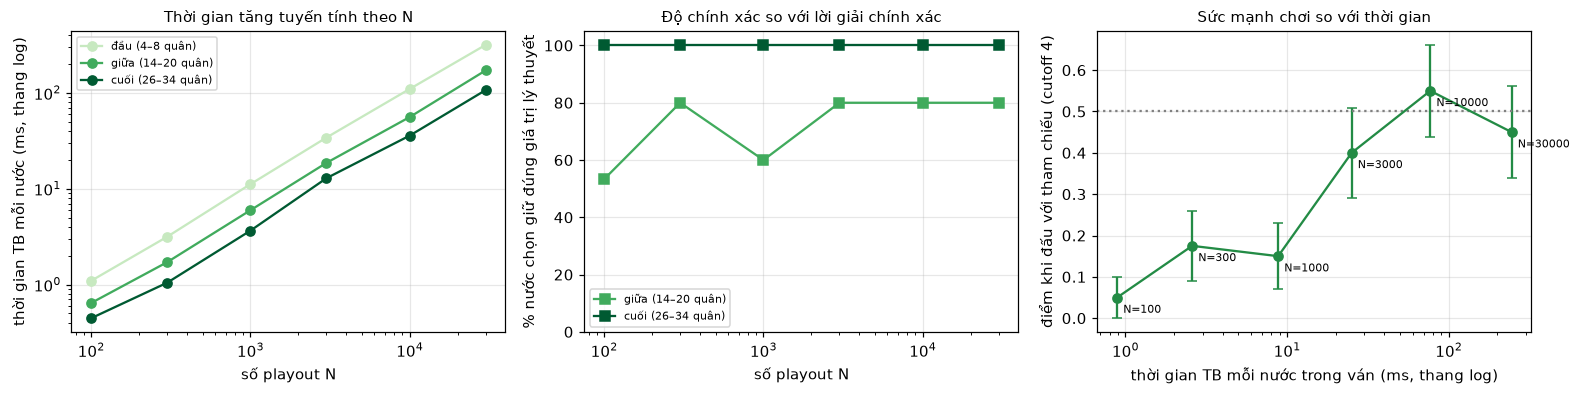

In [50]:
# Your code/ answer goes here.

# ======================= Pure Monte Carlo Search: đánh đổi giữa thời gian và sức mạnh khi đổi số playout =======================
GRAD_NS = [100, 300, 1000, 3000, 10000, 30000]
PM_REPEATS = 3
pm_eval, pm_duel = {}, {}
t0 = time.time()
for N in GRAD_NS:
    pm_eval[N] = evaluate_on_positions(lambda N = N: PureMonteCarloPlayer(N, seed = N), repeats = PM_REPEATS)
    pm_duel[N] = duel(PureMonteCarloPlayer(N, seed = 7 * N), REFERENCE, openings_g)
    print(f"N = {N}: xong ({time.time() - t0:.0f} s)", end = "; ")
print()

rows_out = []
for N in GRAD_NS:
    r = pm_eval[N]
    rows_out.append({"N (playout/nước)": N,
                     **{f"ms/nước – {ph.split(' ')[0]}": round(r[ph]["ms"], 2) for ph in ph_names},
                     **{f"% đúng – {ph.split(' ')[0]}": (round(r[ph]["acc"]) if r[ph]["acc"] is not None else "—") for ph in ph_names[1:]},
                     "Điểm vs. tham chiếu": round(pm_duel[N]["score"], 2), "± sai số chuẩn": round(se_score(pm_duel[N]["score"], pm_duel[N]["games"]), 2),
                     "Thắng/Hòa/Thua": f"{pm_duel[N]['W']}/{pm_duel[N]['D']}/{pm_duel[N]['L']}"})
pm_grad_table = pd.DataFrame(rows_out)
display(pm_grad_table)

fig, ax = plt.subplots(1, 3, figsize = (14.5, 3.7), dpi = 110)
for ph, color in zip(ph_names, ("#c7e9c0", "#41ab5d", "#005a32")):
    ax[0].plot(GRAD_NS, [pm_eval[N][ph]["ms"] for N in GRAD_NS], "o-", color = color, label = ph)
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlabel("số playout N"); ax[0].set_ylabel("thời gian TB mỗi nước (ms, thang log)"); ax[0].set_title("Thời gian tăng tuyến tính theo N", fontsize = 10); ax[0].legend(fontsize = 7); ax[0].grid(alpha = .3)
for ph, color in zip(ph_names[1:], ("#41ab5d", "#005a32")):
    ax[1].plot(GRAD_NS, [pm_eval[N][ph]["acc"] if pm_eval[N][ph]["acc"] is not None else np.nan for N in GRAD_NS], "s-", color = color, label = ph)
ax[1].set_xscale("log"); ax[1].set_ylim(0, 105); ax[1].set_xlabel("số playout N"); ax[1].set_ylabel("% nước chọn giữ đúng giá trị lý thuyết"); ax[1].set_title("Độ chính xác so với lời giải chính xác", fontsize = 10); ax[1].legend(fontsize = 7); ax[1].grid(alpha = .3)
xs = [pm_duel[N]["ms_a"] for N in GRAD_NS]
ax[2].errorbar(xs, [pm_duel[N]["score"] for N in GRAD_NS], yerr = [se_score(pm_duel[N]["score"], pm_duel[N]["games"]) for N in GRAD_NS], fmt = "o-", color = "#238b45", capsize = 3)
for x_, N in zip(xs, GRAD_NS): ax[2].annotate(f"N={N}", (x_, pm_duel[N]["score"]), textcoords = "offset points", xytext = (4, -10), fontsize = 7)
ax[2].set_xscale("log"); ax[2].axhline(0.5, color = "gray", ls = ":"); ax[2].set_xlabel("thời gian TB mỗi nước trong ván (ms, thang log)"); ax[2].set_ylabel("điểm khi đấu với tham chiếu (cutoff 4)"); ax[2].set_title("Sức mạnh chơi so với thời gian", fontsize = 10); ax[2].grid(alpha = .3)
plt.tight_layout(); plt.show()

In [51]:
early, mid, late = ph_names
n_lo, n_hi = GRAD_NS[0], GRAD_NS[-1]
expo = float(np.polyfit(np.log(GRAD_NS), np.log([pm_eval[N][mid]["ms"] for N in GRAD_NS]), 1)[0])        # thời gian ~ N^expo
sc = [pm_duel[N]["score"] for N in GRAD_NS]
slope = float(np.polyfit(np.log10([pm_duel[N]["ms_a"] for N in GRAD_NS]), sc, 1)[0])
acc = lambda N, ph: pm_eval[N][ph]["acc"]
ref_ms = hab_eval[4][mid]["ms"] if 4 in hab_eval else float("nan")
display(Markdown(f"""
**Nhận xét**
* **Thời gian tăng gần như tuyến tính theo N:** thời gian ≈ N^{expo:.2f} (giữa ván), từ {pm_eval[n_lo][mid]["ms"]:.1f} ms (N = {n_lo}) lên {pm_eval[n_hi][mid]["ms"]:.0f} ms (N = {n_hi}). Ở cuối ván mỗi playout ngắn hơn nên rẻ hơn ({pm_eval[n_hi][late]["ms"]:.0f} ms so với {pm_eval[n_hi][mid]["ms"]:.0f} ms ở N = {n_hi}); ở đầu ván playout dài nhất ({pm_eval[n_hi][early]["ms"]:.0f} ms).
* **Độ chính xác** thay đổi từ {pc(acc(n_lo, mid))} (N = {n_lo}) lên {pc(acc(n_hi, mid))} (N = {n_hi}) ở giữa ván và {('giữ nguyên ' + pc(acc(n_hi, late))) if acc(n_lo, late) == acc(n_hi, late) else ('từ ' + pc(acc(n_lo, late)) + ' lên ' + pc(acc(n_hi, late)))} ở cuối ván, khi tăng N lên {n_hi // n_lo} lần. Sai số của một ước lượng Monte Carlo giảm theo 1/√N nên muốn giảm một nửa sai số phải tăng N gấp 4 lần; số lần đo có phân biệt ít nên các phần trăm cũng có sai số lớn.
* **Điểm thi đấu** với tham chiếu (Heuristic Alpha-Beta cutoff 4) đi từ {sc[0]:.2f} (N = {n_lo}) lên {max(sc):.2f} (N = {GRAD_NS[int(np.argmax(sc))]}); mỗi lần nhân thời gian lên 10 lần, điểm tăng thêm ≈ {slope:.2f}. Cấu hình có thời gian lớn nhất tốn {pm_duel[n_hi]['ms_a']:.0f} ms/nước, gấp {pm_duel[n_hi]['ms_a'] / max(ref_ms, 1e-9):.0f} lần tham chiếu (≈ {ref_ms:.1f} ms/nước ở giữa ván) mà {'vẫn chưa vượt được tham chiếu' if max(sc) < 0.5 else 'chỉ vượt tham chiếu ở N rất lớn'}.
* **Giai đoạn ván:** gần cuối ván, playout ngắn nên cùng thời gian chạy được nhiều playout hơn và kết thúc ván là chính xác; ở đầu ván, các nước đi khác nhau rất ít nên độ chính xác khó đo và Monte Carlo cần nhiều playout nhất.
"""))


**Nhận xét**
* **Thời gian tăng gần như tuyến tính theo N:** thời gian ≈ N^0.99 (giữa ván), từ 0.6 ms (N = 100) lên 172 ms (N = 30000). Ở cuối ván mỗi playout ngắn hơn nên rẻ hơn (107 ms so với 172 ms ở N = 30000); ở đầu ván playout dài nhất (317 ms).
* **Độ chính xác** thay đổi từ 53 % (N = 100) lên 80 % (N = 30000) ở giữa ván và giữ nguyên 100 % ở cuối ván, khi tăng N lên 300 lần. Sai số của một ước lượng Monte Carlo giảm theo 1/√N nên muốn giảm một nửa sai số phải tăng N gấp 4 lần; số lần đo có phân biệt ít nên các phần trăm cũng có sai số lớn.
* **Điểm thi đấu** với tham chiếu (Heuristic Alpha-Beta cutoff 4) đi từ 0.05 (N = 100) lên 0.55 (N = 10000); mỗi lần nhân thời gian lên 10 lần, điểm tăng thêm ≈ 0.20. Cấu hình có thời gian lớn nhất tốn 245 ms/nước, gấp 286 lần tham chiếu (≈ 0.9 ms/nước ở giữa ván) mà chỉ vượt tham chiếu ở N rất lớn.
* **Giai đoạn ván:** gần cuối ván, playout ngắn nên cùng thời gian chạy được nhiều playout hơn và kết thúc ván là chính xác; ở đầu ván, các nước đi khác nhau rất ít nên độ chính xác khó đo và Monte Carlo cần nhiều playout nhất.


### Comparison

Compare the performance between the two implementations. Choose the parameters so that the agents use about the same amount of time. Present the results and discuss why you see these results.

,Ngân sách ≈ ms/nước,Heuristic AB (cutoff),Monte Carlo (N),ms/nước AB (đo trong ván),ms/nước MC (đo trong ván),AB thắng,Hòa,AB thua,Điểm AB,± sai số chuẩn
0,0.7,4,107,1.2,1.1,19,0,1,0.95,0.05
1,5.8,6,835,5.7,6.5,15,0,5,0.75,0.10
2,46.5,8,6736,27.6,52.0,17,0,3,0.85,0.08


[21 s]  (20 ván mỗi dòng; N chọn sao cho thời gian suy nghĩ TB mỗi nước xấp xỉ bằng nhau)


,Tác tử,Nước đầu hay chọn,Giá trị lý thuyết của nước đó,Chi tiết
0,"Heuristic AB, cutoff 2",3,thắng,giá trị đánh giá +0.000
1,"Heuristic AB, cutoff 4",3,thắng,giá trị đánh giá +0.000
2,"Heuristic AB, cutoff 6",3,thắng,giá trị đánh giá +0.000
3,"Heuristic AB, cutoff 8",3,thắng,giá trị đánh giá -0.050
4,"Monte Carlo, N = 100",3,thắng,"phân bố: cột 3: 50 %, cột 2: 15 %, cột 4: 15 %"
5,"Monte Carlo, N = 1000",3,thắng,"phân bố: cột 3: 70 %, cột 4: 20 %, cột 2: 10 %"
6,"Monte Carlo, N = 10000",3,thắng,phân bố: cột 3: 100 %


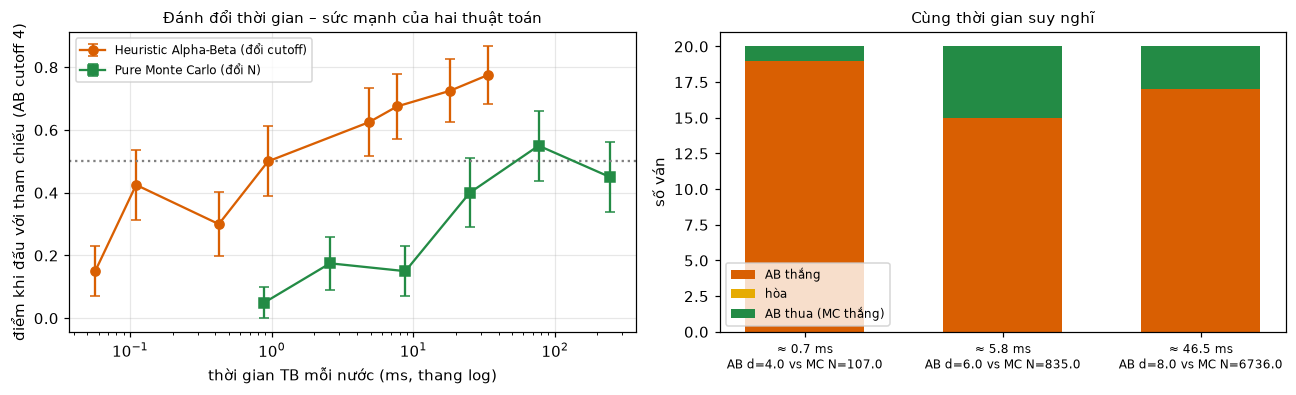

In [52]:
# Your code/ answer goes here.

# ======================= So sánh hai thuật toán với CÙNG ngân sách thời gian =======================
mid = ph_names[1]
t_playout = np.mean([pm_eval[N][ph]["ms"] / N for N in GRAD_NS for ph in ph_names])          # ms cho một playout (trung bình)
rows_out, cmp_res = [], {}
t0 = time.time()
for d in [4, 6, 8]:
    ms_hab = float(np.mean([hab_eval[d][ph]["ms"] for ph in ph_names]))                          # thời gian TB mỗi nước của AB cutoff d trên cả ba giai đoạn
    N_eq = max(20, int(round(ms_hab / t_playout)))
    pm_agent = PureMonteCarloPlayer(N_eq, seed = 1000 + d)
    r = duel(HeuristicAlphaBetaPlayer(cutoff = d), pm_agent, openings_g)
    cmp_res[d] = (N_eq, r)
    rows_out.append({"Ngân sách ≈ ms/nước": round(ms_hab, 1), "Heuristic AB (cutoff)": d, "Monte Carlo (N)": N_eq,
                     "ms/nước AB (đo trong ván)": round(r["ms_a"], 1), "ms/nước MC (đo trong ván)": round(r["ms_b"], 1),
                     "AB thắng": r["W"], "Hòa": r["D"], "AB thua": r["L"], "Điểm AB": round(r["score"], 2), "± sai số chuẩn": round(se_score(r["score"], r["games"]), 2)})
cmp_table = pd.DataFrame(rows_out)
display(cmp_table)
print(f"[{time.time() - t0:.0f} s]  ({2 * len(openings_g)} ván mỗi dòng; N chọn sao cho thời gian suy nghĩ TB mỗi nước xấp xỉ bằng nhau)")

# nước đi đầu tiên trên bàn rỗng so với lời giải lý thuyết: cột 3 thắng, cột 2 và 4 hòa, các cột khác thua
THEORY = {3: "thắng", 2: "hòa", 4: "hòa", 0: "thua", 1: "thua", 5: "thua", 6: "thua"}
first_rows = []
for d in (2, 4, 6, 8):
    agent = HeuristicAlphaBetaPlayer(cutoff = d); a = agent(initial_state(), 1)
    first_rows.append({"Tác tử": f"Heuristic AB, cutoff {d}", "Nước đầu hay chọn": a, "Giá trị lý thuyết của nước đó": THEORY[a], "Chi tiết": f"giá trị đánh giá {agent.last_value:+.3f}"})
for N in (100, 1000, 10000):
    picks = [PureMonteCarloPlayer(N, seed = k)(initial_state(), 1) for k in range(20)]
    top = Counter(picks).most_common(3)
    first_rows.append({"Tác tử": f"Monte Carlo, N = {N}", "Nước đầu hay chọn": top[0][0], "Giá trị lý thuyết của nước đó": THEORY[top[0][0]],
                       "Chi tiết": "phân bố: " + ", ".join(f"cột {c}: {100 * k // len(picks)} %" for c, k in top)})
first_table = pd.DataFrame(first_rows)
display(first_table)

fig, ax = plt.subplots(1, 2, figsize = (12, 3.7), dpi = 110)
ax[0].errorbar([hab_duel[d]["ms_a"] for d in GRAD_DEPTHS], [hab_duel[d]["score"] for d in GRAD_DEPTHS], yerr = [se_score(hab_duel[d]["score"], hab_duel[d]["games"]) for d in GRAD_DEPTHS], fmt = "o-", color = "#d95f02", capsize = 3, label = "Heuristic Alpha-Beta (đổi cutoff)")
ax[0].errorbar([pm_duel[N]["ms_a"] for N in GRAD_NS], [pm_duel[N]["score"] for N in GRAD_NS], yerr = [se_score(pm_duel[N]["score"], pm_duel[N]["games"]) for N in GRAD_NS], fmt = "s-", color = "#238b45", capsize = 3, label = "Pure Monte Carlo (đổi N)")
ax[0].axhline(0.5, color = "gray", ls = ":"); ax[0].set_xscale("log"); ax[0].set_xlabel("thời gian TB mỗi nước (ms, thang log)"); ax[0].set_ylabel("điểm khi đấu với tham chiếu (AB cutoff 4)"); ax[0].set_title("Đánh đổi thời gian – sức mạnh của hai thuật toán", fontsize = 10); ax[0].legend(fontsize = 8); ax[0].grid(alpha = .3)
labels = [f"≈ {row['Ngân sách ≈ ms/nước']} ms\nAB d={row['Heuristic AB (cutoff)']} vs MC N={row['Monte Carlo (N)']}" for _, row in cmp_table.iterrows()]
x = np.arange(len(cmp_table))
ax[1].bar(x, cmp_table["AB thắng"], .6, label = "AB thắng", color = "#d95f02"); ax[1].bar(x, cmp_table["Hòa"], .6, bottom = cmp_table["AB thắng"], label = "hòa", color = "#e6ab02")
ax[1].bar(x, cmp_table["AB thua"], .6, bottom = cmp_table["AB thắng"] + cmp_table["Hòa"], label = "AB thua (MC thắng)", color = "#238b45")
ax[1].set_xticks(x); ax[1].set_xticklabels(labels, fontsize = 8); ax[1].set_ylabel("số ván"); ax[1].set_title("Cùng thời gian suy nghĩ", fontsize = 10); ax[1].legend(fontsize = 8)
plt.tight_layout(); plt.show()

In [53]:
all_ab = (cmp_table["Điểm AB"] > 0.5).all()
rng_txt = f"{cmp_table['Điểm AB'].min():.2f} – {cmp_table['Điểm AB'].max():.2f}"
ab_first_ok = sum(first_table.iloc[i]["Giá trị lý thuyết của nước đó"] == "thắng" for i in range(4))
mc_first = first_table.iloc[4:]
cmp_row = cmp_table.iloc[min(1, len(cmp_table) - 1)]
display(Markdown(f"""
**Kết quả khi dùng cùng ngân sách thời gian:** Heuristic Alpha-Beta đạt điểm {rng_txt} trước Pure Monte Carlo ở {len(cmp_table)} mức ngân sách ({'thắng (điểm > 0,5) ở cả ' + str(len(cmp_table)) + ' mức' if all_ab else 'thắng ở ' + str(int((cmp_table['Điểm AB'] > 0.5).sum())) + '/' + str(len(cmp_table)) + ' mức'}). Đồ thị bên trái đặt hai thuật toán trên cùng trục thời gian; bảng cho điểm của từng cặp có thời gian suy nghĩ tương đương.

**Giải thích**
1. **Cách dùng tài nguyên.** Alpha-Beta dùng tri thức (hàm heuristic) và phép cắt tỉa để *không xét* các nhánh vô ích; còn Monte Carlo phải "đoán" giá trị mỗi nước bằng thống kê nên cần rất nhiều mẫu, và sai số chỉ giảm theo 1/√N. Cùng ~{cmp_row['ms/nước AB (đo trong ván)']:.0f} ms/nước, Alpha-Beta tìm sâu {int(cmp_row['Heuristic AB (cutoff)'])} nửa-nước (đủ để thấy các đe dọa chiến thuật ngắn), còn Monte Carlo chỉ chạy {int(cmp_row['Monte Carlo (N)']):,} playout (≈ {int(cmp_row['Monte Carlo (N)']) // 7:,} mỗi nước khi có 7 nước hợp lệ).
2. **Playout ngẫu nhiên là chính sách yếu.** Trong Connect 4 một nước sai (không chặn) thua ngay; playout ngẫu nhiên hầu như không biết chặn nên đánh giá sai những thế cờ có đe dọa. Chính sách playout tốt hơn hoặc kết hợp cây tìm kiếm (UCB1/MCTS) sẽ cải thiện đáng kể.
3. **Nước đi đầu tiên:** Alpha-Beta cho nước đầu {'đúng (cột giữa – nước duy nhất thắng) ở ' + str(ab_first_ok) + '/4 cutoff đã thử' if ab_first_ok else 'chưa phải cột giữa ở các cutoff đã thử'}, còn Monte Carlo (bảng 'Nước đi đầu tiên') chọn nước đầu có giá trị lý thuyết "{mc_first.iloc[-1]['Giá trị lý thuyết của nước đó']}" ở N lớn nhất. Cả hai không dựa vào lời giải chính xác nên chỉ xấp xỉ.
4. **Phụ thuộc vào gì?** Kết quả phụ thuộc (i) *chất lượng hàm heuristic* (một heuristic kém làm Alpha-Beta mất ưu thế – xem so sánh các heuristic ở Task 4), (ii) *ngân sách thời gian* (khi rất nhiều thời gian thì Monte Carlo tiệm cận nhưng chậm), (iii) *giai đoạn ván* (cuối ván cả hai đều tốt vì cây nhỏ) và (iv) kích thước bàn cờ: khi hệ số nhánh rất lớn hoặc khó thiết kế heuristic, Monte Carlo/MCTS mới trở nên cạnh tranh.
"""))


**Kết quả khi dùng cùng ngân sách thời gian:** Heuristic Alpha-Beta đạt điểm 0.75 – 0.95 trước Pure Monte Carlo ở 3 mức ngân sách (thắng (điểm > 0,5) ở cả 3 mức). Đồ thị bên trái đặt hai thuật toán trên cùng trục thời gian; bảng cho điểm của từng cặp có thời gian suy nghĩ tương đương.

**Giải thích**
1. **Cách dùng tài nguyên.** Alpha-Beta dùng tri thức (hàm heuristic) và phép cắt tỉa để *không xét* các nhánh vô ích; còn Monte Carlo phải "đoán" giá trị mỗi nước bằng thống kê nên cần rất nhiều mẫu, và sai số chỉ giảm theo 1/√N. Cùng ~6 ms/nước, Alpha-Beta tìm sâu 6 nửa-nước (đủ để thấy các đe dọa chiến thuật ngắn), còn Monte Carlo chỉ chạy 835 playout (≈ 119 mỗi nước khi có 7 nước hợp lệ).
2. **Playout ngẫu nhiên là chính sách yếu.** Trong Connect 4 một nước sai (không chặn) thua ngay; playout ngẫu nhiên hầu như không biết chặn nên đánh giá sai những thế cờ có đe dọa. Chính sách playout tốt hơn hoặc kết hợp cây tìm kiếm (UCB1/MCTS) sẽ cải thiện đáng kể.
3. **Nước đi đầu tiên:** Alpha-Beta cho nước đầu đúng (cột giữa – nước duy nhất thắng) ở 4/4 cutoff đã thử, còn Monte Carlo (bảng 'Nước đi đầu tiên') chọn nước đầu có giá trị lý thuyết "thắng" ở N lớn nhất. Cả hai không dựa vào lời giải chính xác nên chỉ xấp xỉ.
4. **Phụ thuộc vào gì?** Kết quả phụ thuộc (i) *chất lượng hàm heuristic* (một heuristic kém làm Alpha-Beta mất ưu thế – xem so sánh các heuristic ở Task 4), (ii) *ngân sách thời gian* (khi rất nhiều thời gian thì Monte Carlo tiệm cận nhưng chậm), (iii) *giai đoạn ván* (cuối ván cả hai đều tốt vì cây nhỏ) và (iv) kích thước bàn cờ: khi hệ số nhánh rất lớn hoặc khó thiết kế heuristic, Monte Carlo/MCTS mới trở nên cạnh tranh.


In [54]:
mid_total_ratio = order_nodes[ORDER_VARIANTS[0][0]]["mid"][0] / order_nodes[ORDER_VARIANTS[-1][0]]["mid"][0]      # thuần / cải tiến đầy đủ, trên các thế cờ giữa ván
mid, late = ph_names[1], ph_names[2]
best_hab, best_pm = max(GRAD_DEPTHS, key = lambda d: hab_duel[d]["score"]), max(GRAD_NS, key = lambda N: pm_duel[N]["score"])
avg_h = M["Điểm TB"].astype(float)
best_h, worst_h = avg_h.idxmax(), avg_h.idxmin()
win_group = min(avg_h[k] for k in names if k[0] in "CD") > max(avg_h[k] for k in names if k[0] in "AB")
n_ab_win = int((cmp_table["Điểm AB"] > 0.5).sum())
display(Markdown(f"""
## Tổng kết

| Thuật toán | Cách dùng trên bàn 6 × 7 | Chi phí mỗi nước | Chất lượng |
|---|---|---|---|
| Random (baseline) | chọn đều ngẫu nhiên | ≈ 0 | Random vs. Random: người đi trước thắng {100 * fast_res[1] / NF:.0f} % |
| Alpha-Beta chính xác (Task 3) | tìm tới cuối ván | **không khả thi** từ bàn trống (ngoại suy {', '.join(f'{k}: {human(f["pred"] / ab_rate)}' for k, f in fits.items())}); khả thi cho bàn ≤ {max(s[0] * s[1] for s in SIZES if size_data[s][1]["done"])} ô | chính xác tuyệt đối (7/7 bàn thử) |
| Heuristic Alpha-Beta (Task 4) | cắt ở độ sâu `cutoff`, đánh giá bằng heuristic | {hab_eval[GRAD_DEPTHS[0]][mid]["ms"]:.2f} ms (cutoff {GRAD_DEPTHS[0]}) → {hab_eval[GRAD_DEPTHS[-1]][mid]["ms"]:.0f} ms (cutoff {GRAD_DEPTHS[-1]}), giữa ván | điểm so với tham chiếu: {hab_duel[GRAD_DEPTHS[0]]["score"]:.2f} → {hab_duel[best_hab]["score"]:.2f} |
| Pure Monte Carlo (Task 5) | N playout ngẫu nhiên chia đều cho các nước | {pm_eval[GRAD_NS[0]][mid]["ms"]:.1f} ms (N = {GRAD_NS[0]}) → {pm_eval[GRAD_NS[-1]][mid]["ms"]:.0f} ms (N = {GRAD_NS[-1]}), giữa ván | điểm so với tham chiếu: {pm_duel[GRAD_NS[0]]["score"]:.2f} → {pm_duel[best_pm]["score"]:.2f} |

**Nhận xét chung**

1. **Quy mô bài toán quyết định thuật toán.** Connect 4 6 × 7 có ≈ {sci(KNOWN_POSITIONS_6x7)} vị trí và cây trò chơi cỡ {sci(tree_est)} nút, nên không thể lập bảng mọi trạng thái hay duyệt tới cuối ván; ngay cả Alpha-Beta lý tưởng cũng chỉ giảm số nút xuống cỡ căn bậc hai. Do đó cần cắt độ sâu + heuristic (Task 4) hoặc lấy mẫu (Task 5).
2. **Kỹ thuật cài đặt quan trọng không kém thuật toán.** Cùng thuật toán Alpha-Beta, bitboard nhanh hơn bản numpy {per_node_np / per_node_bb:.0f} lần mỗi nút, còn nước thắng ngay/cắt nước thua và bảng chuyển vị giảm thêm số nút {mid_total_ratio:.0f} lần trên thế cờ giữa ván; thứ tự duyệt đơn thuần chỉ cho hiệu quả nhỏ và phụ thuộc thế cờ.
3. **Hàm heuristic và độ sâu cùng quyết định sức mạnh.** Ở cùng cutoff, hàm đạt điểm trung bình cao nhất trong thí nghiệm so sánh là {best_h[0]} ({avg_h[best_h]:.2f}), thấp nhất là {worst_h[0]} ({avg_h[worst_h]:.2f}) {'– hai hàm dựa trên cửa sổ 4 ô (C, D) đều hơn hai hàm còn lại (A, B)' if win_group else '– hai nhóm hàm không tách bạch hẳn nên không nên kết luận mạnh hơn mức sai số cho phép (xem ma trận đấu)'}; tăng cutoff từ {GRAD_DEPTHS[0]} lên {GRAD_DEPTHS[-1]} nâng điểm đấu với tham chiếu từ {hab_duel[GRAD_DEPTHS[0]]["score"]:.2f} lên {hab_duel[GRAD_DEPTHS[-1]]["score"]:.2f} nhưng chi phí tăng theo hàm mũ (khoảng ×{(hab_eval[GRAD_DEPTHS[-1]][mid]["ms"] / hab_eval[GRAD_DEPTHS[0]][mid]["ms"]) ** (1 / (len(GRAD_DEPTHS) - 1)):.1f} mỗi mức).
4. **Alpha-Beta + heuristic {'hơn' if n_ab_win == len(cmp_table) else 'hơn ở ' + str(n_ab_win) + '/' + str(len(cmp_table)) + ' mức ngân sách so với'} Monte Carlo thuần túy trên Connect 4** khi so sánh ở cùng thời gian suy nghĩ (điểm Alpha-Beta {cmp_table["Điểm AB"].min():.2f} – {cmp_table["Điểm AB"].max():.2f}); lý do hợp lý là hệ số nhánh nhỏ, heuristic đơn giản mà hiệu quả và playout ngẫu nhiên là chính sách yếu (không biết chặn). Monte Carlo có ưu điểm là không cần heuristic và dễ mở rộng cho trò chơi khác (xem MCTS/UCB1 ở phần Tic-Tac-Toe).
5. **Hạn chế của kết quả.** Các điểm thi đấu dựa trên {2 * N_OPEN_GRAD} ván mỗi dòng nên sai số chuẩn khoảng ±{se_score(0.5, 2 * N_OPEN_GRAD):.2f}; thời gian phụ thuộc máy chạy; các tác tử Alpha-Beta là xác định, nên sự đa dạng ván đấu chỉ đến từ khai cuộc ngẫu nhiên.
"""))


## Tổng kết

| Thuật toán | Cách dùng trên bàn 6 × 7 | Chi phí mỗi nước | Chất lượng |
|---|---|---|---|
| Random (baseline) | chọn đều ngẫu nhiên | ≈ 0 | Random vs. Random: người đi trước thắng 55 % |
| Alpha-Beta chính xác (Task 3) | tìm tới cuối ván | **không khả thi** từ bàn trống (ngoại suy Thuần: 192 ngày, Cải tiến: 3 giờ); khả thi cho bàn ≤ 25 ô | chính xác tuyệt đối (7/7 bàn thử) |
| Heuristic Alpha-Beta (Task 4) | cắt ở độ sâu `cutoff`, đánh giá bằng heuristic | 0.06 ms (cutoff 1) → 49 ms (cutoff 8), giữa ván | điểm so với tham chiếu: 0.15 → 0.78 |
| Pure Monte Carlo (Task 5) | N playout ngẫu nhiên chia đều cho các nước | 0.6 ms (N = 100) → 172 ms (N = 30000), giữa ván | điểm so với tham chiếu: 0.05 → 0.55 |

**Nhận xét chung**

1. **Quy mô bài toán quyết định thuật toán.** Connect 4 6 × 7 có ≈ 4.5 · 10¹² vị trí và cây trò chơi cỡ 2.0 · 10²⁹ nút, nên không thể lập bảng mọi trạng thái hay duyệt tới cuối ván; ngay cả Alpha-Beta lý tưởng cũng chỉ giảm số nút xuống cỡ căn bậc hai. Do đó cần cắt độ sâu + heuristic (Task 4) hoặc lấy mẫu (Task 5).
2. **Kỹ thuật cài đặt quan trọng không kém thuật toán.** Cùng thuật toán Alpha-Beta, bitboard nhanh hơn bản numpy 51 lần mỗi nút, còn nước thắng ngay/cắt nước thua và bảng chuyển vị giảm thêm số nút 65 lần trên thế cờ giữa ván; thứ tự duyệt đơn thuần chỉ cho hiệu quả nhỏ và phụ thuộc thế cờ.
3. **Hàm heuristic và độ sâu cùng quyết định sức mạnh.** Ở cùng cutoff, hàm đạt điểm trung bình cao nhất trong thí nghiệm so sánh là C (0.62), thấp nhất là A (0.36) – hai hàm dựa trên cửa sổ 4 ô (C, D) đều hơn hai hàm còn lại (A, B); tăng cutoff từ 1 lên 8 nâng điểm đấu với tham chiếu từ 0.15 lên 0.78 nhưng chi phí tăng theo hàm mũ (khoảng ×2.6 mỗi mức).
4. **Alpha-Beta + heuristic hơn Monte Carlo thuần túy trên Connect 4** khi so sánh ở cùng thời gian suy nghĩ (điểm Alpha-Beta 0.75 – 0.95); lý do hợp lý là hệ số nhánh nhỏ, heuristic đơn giản mà hiệu quả và playout ngẫu nhiên là chính sách yếu (không biết chặn). Monte Carlo có ưu điểm là không cần heuristic và dễ mở rộng cho trò chơi khác (xem MCTS/UCB1 ở phần Tic-Tac-Toe).
5. **Hạn chế của kết quả.** Các điểm thi đấu dựa trên 20 ván mỗi dòng nên sai số chuẩn khoảng ±0.11; thời gian phụ thuộc máy chạy; các tác tử Alpha-Beta là xác định, nên sự đa dạng ván đấu chỉ đến từ khai cuộc ngẫu nhiên.
